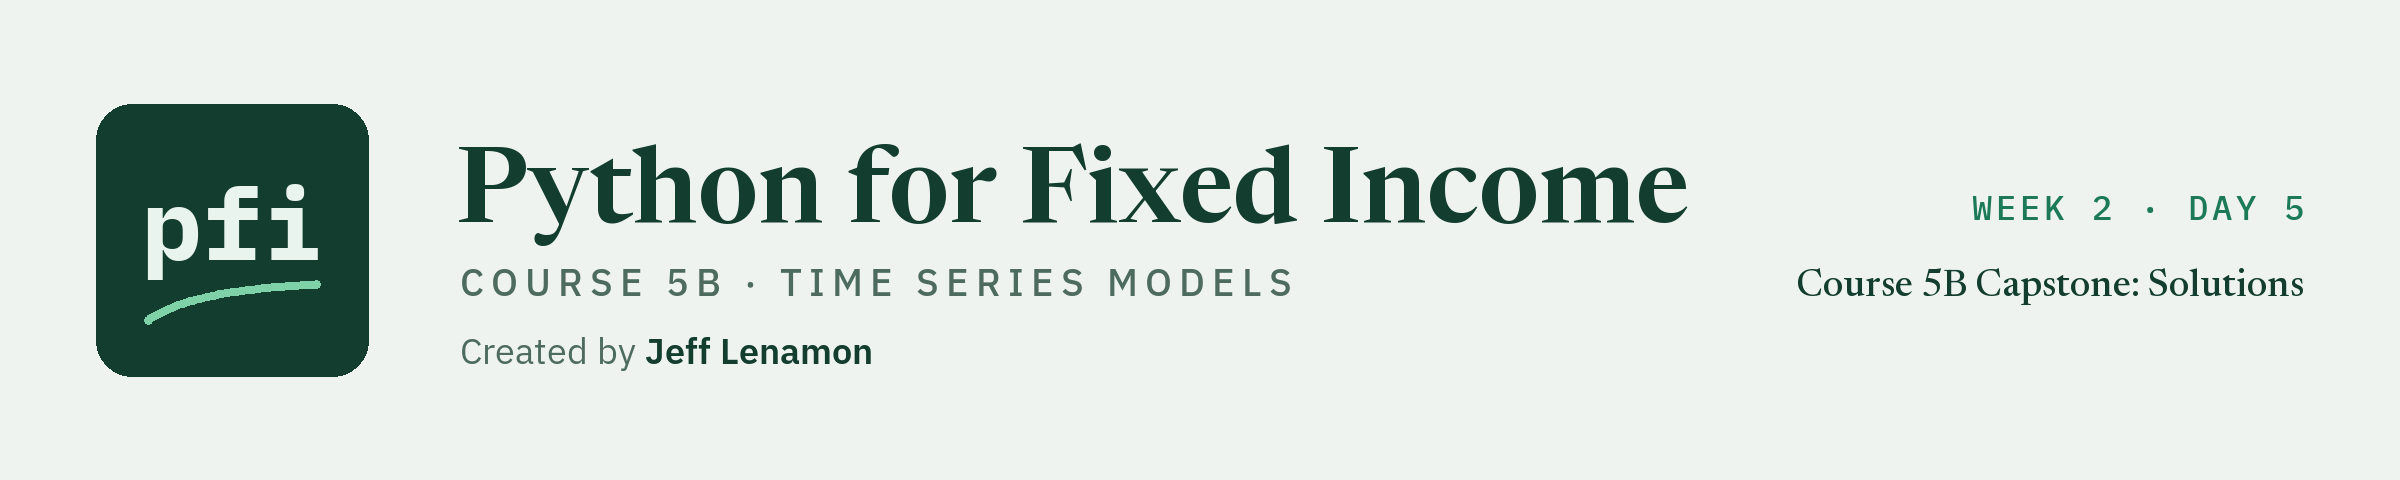

# Course 5B Capstone: Solutions

Week 2, Day 5. The worked version of the capstone: every question answered with code, its output, and what the output shows. Write your own answers and your own description first.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day5/course5b_capstone_solutions.ipynb)

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05b_time_series/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


## The Brief

**The desk's question, in the past tense.** The desk keeps two daily series in bp: the **2s10s** slope (the 10 Yr yield less the 2 Yr yield, from the U.S. Treasury's public file) and an **invented HY spread** (Course 3's synthetic file; it is not ICE, Moody's, or any index). Fitted on the development years, 2015-01-02 to 2022-12-30, did any model score closer to each day's value over the held-out years, 2023-01-03 to 2026-10-02, than the last value carried forward? And did a volatility model score closer to the size of each day's change than a constant did?

You answer with the course's workflow, start to finish, on both series: repair the planted problems with a change log; set the years; test stationarity; read the ACF; score the baselines, ARIMA, exponential smoothing, and LightGBM on lags walk-forward; fit GARCH for the size of a change; write the choice rule as a tested function and choose on the development years only; commit the choice; open the held-out years once; and write what the models showed and where they failed. **If nothing beats the last value, that is the result, and you say so in plain words.**

<table align="left">
<tr><th align="left">Deliverable</th><th align="left">Question</th><th align="left">What it holds</th></tr>
<tr><td align="left">1 The module</td><td align="left">1</td><td align="left"><code>tskit.py</code> and its tests, passing, committed</td></tr>
<tr><td align="left">2 The repaired series</td><td align="left">2</td><td align="left">blanks and wrong prints found, corrected from a second feed with a change log, filled by a rule</td></tr>
<tr><td align="left">3 Stationarity</td><td align="left">3</td><td align="left">ADF and KPSS on levels and changes of both series</td></tr>
<tr><td align="left">4 Memory</td><td align="left">4</td><td align="left">the ACF of the changes and of their squares, Ljung-Box</td></tr>
<tr><td align="left">5 Baselines</td><td align="left">5</td><td align="left">five walk-forward folds, the last value, the drift, the training mean</td></tr>
<tr><td align="left">6 Models of the level</td><td align="left">6</td><td align="left">ARIMA, exponential smoothing, LightGBM on lags</td></tr>
<tr><td align="left">7 Volatility</td><td align="left">7</td><td align="left">GARCH(1,1) and two simpler rules for the size of a change</td></tr>
<tr><td align="left">8 The choice</td><td align="left">8</td><td align="left"><code>choose_model</code>, tested; <code>choice.md</code>, committed before the held-out years open</td></tr>
<tr><td align="left">9 The held-out years</td><td align="left">9</td><td align="left">opened once, every model scored once</td></tr>
<tr><td align="left">10 What the models show</td><td align="left">10</td><td align="left">the summary table, the closing picture, the description, <code>results.csv</code></td></tr>
<tr><td align="left">11 The AI-use log</td><td align="left">10</td><td align="left">what you asked an assistant, accepted, rejected, and checked</td></tr>
</table>
<br clear="left">

<table align="left">
<tr><th align="left">Sitting</th><th align="left">Sections</th></tr>
<tr><td align="left">First</td><td align="left">1 the module, 2 the repair, 3 stationarity, 4 memory</td></tr>
<tr><td align="left">Second</td><td align="left">5 baselines, 6 models of the level, 7 volatility</td></tr>
<tr><td align="left">Third</td><td align="left">8 the choice, 9 the held-out years, 10 the summary and the description, then Excel and Git</td></tr>
</table>
<br clear="left">

The whole notebook runs in a few minutes on one thread. Let it.

### The rules

1. **The held-out years stay closed until question 9.** `open_held_out_rows()` reads them once, stops if it is used a second time, and stops before the first unless `choice.md` has been committed in the work folder.
2. **Every model is fitted and scored walk-forward,** on day 2's five folds of the development years: 504 training dates first, then 252 test dates a fold. The model's value for a date comes from dates before it.
3. **Every choice is made on the development folds by a rule written down before the models are scored.** Question 8 writes the rule as a tested function.
4. **Plain names.** A model's output is "the model's value for that date", "the one-step value", or "fitted volatility". It is never called a forecast, a prediction, a projection, an outlook, a signal, or a view on rates.
5. **Past tense.** Every sentence you write says what a model did on dates inside the file.
6. **The same answer on every run.** `SEED = 42`, one thread, and `random_state=SEED` or `n_jobs=1` wherever a function takes them.
7. **Git only in the work folder.** Every Git command is written `!git -C "{work}" ...`, as on every day of the course.
8. **The notebook runs from top to bottom** with Restart and Run All before you hand it in.

### What help is allowed

Every earlier notebook of Course 5B and your notes; the documentation of pandas, statsmodels, arch, LightGBM, and openpyxl; and an AI assistant, used the way the course taught: the docstring is the prompt, read the code that comes back, test it before you trust it, and keep a log as you go (question 10.4). Nothing from an employer goes into an AI tool or into Colab.

### How to check your work

Most questions ask you to store an answer in a variable such as `answer_2_1`. The cell after it runs `check()`, which prints `correct`, `not yet` with what you have, or `not attempted yet`. The right answers are not written anywhere in this notebook: each check holds a short code made from the right answer, and `check()` makes a code from yours in the same way and compares the two. A whole number can be given as `7` or `7.0`. A decimal is rounded to the places the question states before it is compared, so store the full number and let `check()` round it. Several values go in a tuple, in the order the question asks.

Your choices change the numbers that follow, so the checks after section 8 assume the choices the course made. Under some questions a closed block that starts "Stuck after trying?" holds the decision the capstone expects for one kind of choice: not a count and not an answer. Leave it closed until you have made your own.

Worked answers are in `course5b_capstone_solutions.ipynb` in this folder. Open it after you have written your own description.

## The Data

**The files** are the two the course has used since day 1: `treasury_par_yields.csv` (the U.S. Treasury's daily par yield curve, 2,940 dates from 2015-01-02 to 2026-10-02, public domain) and `course3_synthetic_spreads.csv` (invented IG and HY spreads in bp, one per date: **synthetic**, not ICE, Moody's, or any index).

**The planted problems.** The capstone works on a *published copy* of three series, the 2 Yr, the 10 Yr, and the HY, made for this lesson from the files with one seeded generator: four blank cells in each, and one wrong print in each (a decimal slipped). A second feed holds the true value of each wrong print and of one blank in each column. The real file has none of these problems; they were planted so the repair has something to find.

**The years.** The development years run to 2022-12-30 (2,001 dates) and the held-out years start on 2023-01-03 (939 dates). The files hold both. The loading cell below keeps only the development rows, and nothing reads a held-out row until question 9.

**Place and period.** One government curve and one invented spread, 2015 to 2026. Nothing here says anything about any date after 2026-10-02.

## Setup

Run the setup cells first. They are complete: do not change them. The first sets the thread settings, makes today's work folder, and copies the two data files into it. The next cells write the complete `mlkit.py`, `tskit.py`, and `test_tskit.py` as day 9 left them (**if you kept your own `my_bondmath` up to date, paste your own `tskit` files into those cells instead**), import them, and set the chart style. The last setup cell defines `jump_and_back()`, `open_held_out_rows()`, `answered()`, `answer_text()`, and `check()`.

Q. Set up the work folder and copy the data files into it.

In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, statsmodels, arch, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("arch", "arch"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05b_time_series/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "arch": "8.0.0", "scikit-learn": "1.9.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5b_10_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, arch 8.0.0, scikit-learn 1.9.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5b_10_cdbq1yc_, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, unchanged. `tskit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `tskit.py` and `test_tskit.py` as day 9 left them: the complete module.

In [4]:
%%writefile tskit.py
"""tskit: the time series pieces of Course 5B, written down and tested.

Written day by day in Python for Fixed Income, Course 5B: Time Series Models.

Conventions, the same in every function:
- A series is a pandas Series, and a frame a DataFrame, indexed by date: unique and ascending.
- Yields are in percent and changes in bp, as in the Treasury file; each docstring states its unit.
- A function that describes or repairs data never fills an earlier date from a later one unless its docstring
  says so in its first lines.
- A fitted value is for a date inside the file, from a model fitted on earlier dates only; it is never a
  statement about a date after the file ends.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # dated tables

import mlkit  # Course 4's module: its walk-forward splits and its past-only check are used from day 2


def _check_dated(index: pd.Index, name: str) -> None:
    """Stop unless the index is a DatetimeIndex that is not empty, unique, and ascending."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{name} must be indexed by date (a DatetimeIndex)")
    if len(index) == 0:
        raise ValueError(f"{name} is empty")
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError(f"{name} must have unique dates in ascending order")


def gap_report(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per column of a dated frame: where the series starts and ends, and where its values are blank.

    Input: frame, dated rows (a DatetimeIndex, unique and ascending), one column per series.
    Output: a DataFrame indexed by column name, with
      rows: the rows in the frame;
      first_valid, last_valid: the first and last dates that hold a value (NaT for a column with none);
      before_start: blank rows before first_valid (a series that had not started yet);
      blank_inside: blank cells from first_valid to last_valid (outages and gaps inside the series);
      after_end: blank rows after last_valid;
      longest_inside: the longest run of consecutive blank rows inside the series (0 when there is none).
    A date with no row at all (a market holiday) is not in the frame, so it is not counted here: compare the
    index with a calendar to find those.
    Raises ValueError for an empty frame or an index that is not dated, unique, and ascending.
    """
    _check_dated(frame.index, "frame")
    rows = []
    for column in frame.columns:
        blank = frame[column].isna().to_numpy()
        first, last = frame[column].first_valid_index(), frame[column].last_valid_index()
        if first is None:
            # no value at all: every row counts as before the start
            rows.append({"column": column, "rows": len(blank), "first_valid": pd.NaT, "last_valid": pd.NaT,
                         "before_start": len(blank), "blank_inside": 0, "after_end": 0, "longest_inside": 0})
            continue
        start, end = frame.index.get_loc(first), frame.index.get_loc(last)
        inside = blank[start:end + 1]
        runs = gap_runs(frame[column].iloc[start:end + 1]) if inside.any() else None
        rows.append({"column": column, "rows": len(blank), "first_valid": first, "last_valid": last,
                     "before_start": start, "blank_inside": int(inside.sum()), "after_end": len(blank) - 1 - end,
                     "longest_inside": int(runs["rows"].max()) if runs is not None else 0})
    return pd.DataFrame(rows).set_index("column")


def gap_runs(series: pd.Series) -> pd.DataFrame:
    """Every run of consecutive blank values in a dated series: its first and last dates and its length in rows.

    Input: series, values indexed by date (unique and ascending).
    Output: a DataFrame with one row per run, in date order, and columns
      start, end: the first and last dates of the run;
      rows: the number of blank rows in the run;
      kind: "before start" for a run on the first row (the series had not started), "after end" for a run that
      reaches the last row, and "inside" for every other run.
    With nothing blank, an empty DataFrame with the same columns. A run counts rows, not calendar days: a blank
    Friday and the blank Monday after it are one run of 2 rows.
    Raises ValueError for an empty series or an index that is not dated, unique, and ascending.
    """
    _check_dated(series.index, "series")
    blank = series.isna()
    # a new run number starts wherever blank switches between True and False
    run_number = (blank != blank.shift(fill_value=not blank.iloc[0])).cumsum()
    runs = []
    for _, run in series[blank].groupby(run_number[blank]):
        first, last = series.index.get_loc(run.index[0]), series.index.get_loc(run.index[-1])
        kind = "before start" if first == 0 else "after end" if last == len(series) - 1 else "inside"
        runs.append({"start": run.index[0], "end": run.index[-1], "rows": len(run), "kind": kind})
    return pd.DataFrame(runs, columns=["start", "end", "rows", "kind"])


def apply_corrections(frame: pd.DataFrame, corrections: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply a table of corrections to a dated frame; return the corrected copy and a log of every change.

    Inputs: frame, dated rows, one column per series; corrections, a DataFrame with the columns date, column,
    value, source: one row per cell to set. value may be NaN, to blank a value known to be wrong (DataFrame.update
    skips a NaN, so it can never blank a cell).
    Output: (corrected, log). corrected is a copy of frame; the input is not changed. log is a DataFrame with the
    columns date, column, old, new, source: one row per cell whose value changed, in the order of corrections.
    A correction that leaves a cell as it was (the same number, or blank to blank) is not a change and is not
    logged.
    Raises ValueError if corrections lacks one of its four columns, if a date or a column is not in frame, or if
    one cell is corrected twice.
    """
    _check_dated(frame.index, "frame")
    needed = ["date", "column", "value", "source"]
    missing = [name for name in needed if name not in corrections.columns]
    if missing:
        raise ValueError(f"corrections needs the columns {needed}; missing {missing}")
    dates = pd.DatetimeIndex(corrections["date"])
    unknown_dates = dates[~dates.isin(frame.index)]
    if len(unknown_dates):
        raise ValueError(f"dates not in frame: {[str(d.date()) for d in unknown_dates]}")
    unknown_columns = sorted(set(corrections["column"]) - set(frame.columns))
    if unknown_columns:
        raise ValueError(f"columns not in frame: {unknown_columns}")
    cells = list(zip(dates, corrections["column"]))
    if len(set(cells)) != len(cells):
        raise ValueError("a cell is corrected twice: one row per cell")
    corrected = frame.copy()
    log = []
    for (date, column), value, source in zip(cells, corrections["value"], corrections["source"]):
        old = corrected.at[date, column]
        # blank to blank, or the same number, is not a change
        if (pd.isna(old) and pd.isna(value)) or old == value:
            continue
        corrected.at[date, column] = value
        log.append({"date": date, "column": column, "old": old, "new": value, "source": source})
    return corrected, pd.DataFrame(log, columns=["date", "column", "old", "new", "source"])


NAIVE_KINDS = ("last", "mean", "drift")


def naive_values(series: pd.Series, kind: str, n_train: int | None = None) -> pd.Series:
    """The naive value for each date, built only from the dates before it.

    Input: series, a dated Series of levels (yields or spreads in bp); kind, one of
      "last": the value on the row before (the last value carried forward);
      "mean": the average of the values so far;
      "drift": the last value plus the average change so far;
    n_train, the rows of the training window, or None.
    Output: with n_train None, a Series on every date of the input, NaN where no earlier date exists (the first row
    for "last" and "mean", the first two rows for "drift"), each value using the dates before it. With n_train set,
    the Series for the dates from row n_train on, where "mean" and "drift" use the average level and the average
    change of the first n_train rows only, fixed for the whole test window, and "last" still uses the row before.
    Raises ValueError for an unknown kind, an input that is not dated and ascending, or an n_train outside 2 to
    one less than the rows.
    """
    _check_dated(series.index, "series")
    if kind not in NAIVE_KINDS:
        raise ValueError(f"kind must be one of {NAIVE_KINDS}, not {kind!r}")
    last = series.shift(1)
    if n_train is None:
        # expanding averages, shifted one row so a date never sees itself
        mean = series.expanding().mean().shift(1)
        change = series.diff().expanding().mean().shift(1)
        return {"last": last, "mean": mean, "drift": last + change}[kind]
    if not 2 <= n_train < len(series):
        raise ValueError(f"n_train must be from 2 to {len(series) - 1}, not {n_train}")
    train = series.iloc[:n_train]
    fixed = {"last": last, "mean": pd.Series(train.mean(), index=series.index),
             "drift": last + train.diff().mean()}[kind]
    return fixed.iloc[n_train:]


def _paired(actual, values) -> tuple[np.ndarray, np.ndarray]:
    """Two equal-length arrays with no NaN; anything else is a mistake to fix, not to hide."""
    a, v = np.asarray(actual, dtype=float), np.asarray(values, dtype=float)
    if a.shape != v.shape or a.ndim != 1 or len(a) == 0:
        raise ValueError(f"need two non-empty arrays of one length; got shapes {a.shape} and {v.shape}")
    if np.isnan(a).any() or np.isnan(v).any():
        raise ValueError("NaN in the scored values: drop those dates, or fill them on purpose, before scoring")
    return a, v


def mae(actual, values) -> float:
    """Mean absolute error: the average size of a miss, in the unit of the inputs (bp in this course)."""
    a, v = _paired(actual, values)
    return float(np.abs(a - v).mean())


def rmse(actual, values) -> float:
    """Root mean squared error, in the unit of the inputs. Squaring weights big misses more than MAE does."""
    a, v = _paired(actual, values)
    return float(np.sqrt(((a - v) ** 2).mean()))


def mase(actual, values, baseline) -> float:
    """MAE of `values` divided by the MAE of `baseline`, on the same dates (here: the last value carried forward).

    1.0 means as far from the actual values as the baseline; below 1.0 is closer. Raises ValueError if the
    baseline is exact on every date (a division by zero) or the inputs do not pair.
    """
    scale = mae(actual, baseline)
    if scale == 0:
        raise ValueError("the baseline has no error on these dates, so a ratio to it is undefined")
    return mae(actual, values) / scale


def walk_forward_score(series: pd.Series, fit_one, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a rule fold by fold, walk-forward, and check that it uses only the past.

    Inputs: series, a dated Series with no NaN (levels in bp); fit_one(history, n_train), a function that fits on
    history.iloc[:n_train] and returns one value per row from n_train to the end of history, the value for row t
    using only rows before t; splits, the (train_positions, test_positions) list of mlkit.walk_forward_splits
    with gap 0; check, whether to prove the past-only rule by removing later rows (default True).
    Output: (scores, values). scores has one row per fold: test_start, test_end, rows, mae, rmse, all against the
    actual series. values is a Series on the series' dates, NaN outside the test windows.
    The proof: the values for the first half of each test window plus one row are recomputed with every later row
    set to NaN; a value that moves used a later row, and AssertionError names its date.
    Raises ValueError for a series with NaN, a split with a gap, or a wrong number of values.
    """
    _check_dated(series.index, "series")
    if series.isna().any():
        raise ValueError("the series has blank dates: score only dates with a value (day 1)")
    values = pd.Series(np.nan, index=series.index)
    rows = []
    for number, (train, test) in enumerate(splits, start=1):
        mlkit.assert_past_only(series.index[train], series.index[test])
        n_train, end = len(train), int(test[-1]) + 1
        if int(test[0]) != n_train:
            raise ValueError("splits must have gap 0: the test window starts on the row after training")
        history = series.iloc[:end]
        found = np.asarray(fit_one(history, n_train), dtype=float)
        if found.shape != (end - n_train,):
            raise ValueError(f"fit_one returned {found.shape} values; the test window has {end - n_train} rows")
        if check:
            # rows from the halfway row on are removed: values up to and including that row may not move
            half = n_train + len(found) // 2
            removed = history.copy()
            removed.iloc[half:] = np.nan
            again = np.asarray(fit_one(removed, n_train), dtype=float)
            moved = np.flatnonzero(~np.isclose(found[:half - n_train + 1], again[:half - n_train + 1], equal_nan=True))
            if len(moved):
                raise AssertionError(f"fold {number}: the value for {history.index[n_train + moved[0]].date()} changed "
                                     "when later rows were removed, so it used a row that is not before its date")
        actual = series.iloc[test].to_numpy()
        values.iloc[test] = found
        rows.append({"fold": number, "test_start": series.index[test[0]], "test_end": series.index[test[-1]],
                     "rows": len(test), "mae": mae(actual, found), "rmse": rmse(actual, found)})
    return pd.DataFrame(rows).set_index("fold"), values


import warnings  # kpss_summary names the one warning it handles

from statsmodels.tools.sm_exceptions import InterpolationWarning  # statsmodels' ADF and KPSS tests
from statsmodels.tsa.stattools import adfuller, kpss


def _values(series: pd.Series, name: str) -> np.ndarray:
    """The values of a Series as floats, or ValueError: a test needs at least 20 values and no blank."""
    if not isinstance(series, pd.Series):
        raise ValueError(f"{name} must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 20:
        raise ValueError(f"{name} has {len(values)} values; a stationarity test needs at least 20")
    if np.isnan(values).any():
        raise ValueError(f"{name} has blank values: drop them first (the first change of a series is blank)")
    return values


def adf_summary(series: pd.Series, regression: str = "c", maxlag: int | None = None, autolag: str | None = "AIC") -> dict:
    """The augmented Dickey-Fuller test of a series, in a few named numbers.

    Null hypothesis: the series has a unit root (it wanders; it is not stationary). A small p-value rejects it.
    Inputs: series, values with no blank (levels or changes); regression, "c" (a constant), "ct" (a constant and a
    trend), or "n" (neither); maxlag, the most lagged changes to include (None lets statsmodels set it); autolag,
    the rule that picks the number of lagged changes up to maxlag ("AIC", "BIC", or None to use exactly maxlag).
    Output: a dict with statistic, p_value, lags_used, n_obs, critical_5pct (the 5 percent critical value), and
    rejects_unit_root (True when p_value is below 0.05).
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    result = adfuller(values, maxlag=maxlag, regression=regression, autolag=autolag, result_object=True)
    return {"statistic": float(result.statistic), "p_value": float(result.pvalue), "lags_used": int(result.lags),
            "n_obs": int(result.nobs), "critical_5pct": float(result.critical_values["5%"]),
            "rejects_unit_root": bool(result.pvalue < 0.05)}


def kpss_summary(series: pd.Series, regression: str = "c", nlags: str | int = "auto") -> dict:
    """The KPSS test of a series, in a few named numbers.

    Null hypothesis: the series is stationary (around a constant for "c", around a trend for "ct"). A small p-value
    rejects it, which is the opposite reading of the ADF test.
    Inputs: series, values with no blank; regression, "c" or "ct"; nlags, "auto" or the number of lags in the
    long-run variance estimate.
    Output: a dict with statistic, p_value, lags_used, critical_5pct, p_note, and rejects_stationarity (True when
    p_value is below 0.05). statsmodels interpolates p-values in a table that runs from 0.01 to 0.1, so a statistic
    outside the table gives 0.01 or 0.1 exactly; p_note then says "at most 0.01" or "at least 0.1", and "inside the
    table" otherwise.
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    # statsmodels warns when the statistic is outside its p-value table; p_note carries that information instead
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        result = kpss(values, regression=regression, nlags=nlags, result_object=True)
    p_value = float(result.pvalue)
    note = "at most 0.01" if p_value <= 0.01 else "at least 0.1" if p_value >= 0.1 else "inside the table"
    return {"statistic": float(result.statistic), "p_value": p_value, "lags_used": int(result.lags),
            "critical_5pct": float(result.critical_values["5%"]), "p_note": note, "rejects_stationarity": bool(p_value < 0.05)}


def acf_by_hand(series: pd.Series, lag: int) -> float:
    """The autocorrelation of a series at one lag, from the definition.

    The values' average is taken away; the autocorrelation at lag k is the sum, over every date that has a value k rows
    before it, of the product of the two deviations, divided by the sum of every deviation squared. It equals
    statsmodels' acf (adjusted=False), and differs a little from pandas' Series.autocorr, which takes the correlation
    of the two offset stretches.
    Inputs: series, values with no blank (changes in bp, say); lag, the rows between the two values (0 gives 1.0).
    Output: a float from -1 to 1.
    Raises ValueError for a series that is not a Series, has fewer than 3 values or a blank or no variation, or for a
    lag that is negative or not below the number of values.
    """
    if not isinstance(series, pd.Series):
        raise ValueError("series must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 3:
        raise ValueError(f"series has {len(values)} values; an autocorrelation needs at least 3")
    if np.isnan(values).any():
        raise ValueError("series has blank values: drop them first (the first change of a series is blank)")
    if not 0 <= lag < len(values):
        raise ValueError(f"lag must be from 0 to {len(values) - 1}; got {lag}")
    deviations = values - values.mean()
    total = float((deviations ** 2).sum())
    if total == 0:
        raise ValueError("series does not vary, so its autocorrelation is undefined")
    return float((deviations[lag:] * deviations[:len(values) - lag]).sum() / total)


from statsmodels.tools.sm_exceptions import EstimationWarning  # the one warning fit_arima handles
from statsmodels.tsa.arima.model import ARIMA


def fit_arima(values, order: tuple, trend: str = "c", require_convergence: bool = True, **settings):
    """Fit an ARIMA(p, d, q) by maximum likelihood to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (daily changes in bp, say); order, the tuple (p, d, q);
    trend, "n" (none), "c" (a constant), "t" (a time trend), or "ct"; require_convergence, whether to raise if the
    optimiser did not converge (the default) or return the results anyway, for a grid that records `converged`;
    settings, any other ARIMA setting by name (enforce_stationarity=False, say).
    Output: the fitted results; results.mle_retvals["converged"] says whether the optimiser converged.
    The array goes in without its dates on purpose: a series of trading days has no frequency, and statsmodels warns
    about a date index it cannot use. Two statsmodels messages are handled here and nowhere else: the optimiser's
    ConvergenceWarning is switched off through method_kwargs (the result says so instead), and the EstimationWarning
    "starting parameters replaced by zeros", which reports a fallback for mixed AR and MA orders, is caught.
    Raises ValueError for an order that is not three non-negative integers or values with a blank, and RuntimeError when
    require_convergence is True and the optimiser did not converge.
    """
    if len(order) != 3 or not all(isinstance(k, (int, np.integer)) and k >= 0 for k in order):
        raise ValueError(f"order must be three non-negative integers (p, d, q); got {order}")
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", EstimationWarning)
        results = ARIMA(array, order=order, trend=trend, **settings).fit(method_kwargs={"warn_convergence": False})
    if require_convergence and not results.mle_retvals["converged"]:
        raise RuntimeError(f"ARIMA{tuple(order)} did not converge on {len(array)} values: try a smaller order")
    return results


def arima_grid(values, max_p: int, max_q: int, trend: str = "c") -> pd.DataFrame:
    """The information criteria of every ARIMA(p, 0, q) with p up to max_p and q up to max_q, on one array.

    Input: values, as for fit_arima (a stationary series: a change, not a level); trend as for fit_arima.
    Output: a DataFrame with one row per (p, q), in order, and the columns p, q, aic, bic, converged. AIC is
    2k - 2 ln L and BIC is k ln(n) - 2 ln L, with k fitted parameters (including the variance) and L the likelihood:
    lower is better, and BIC charges more per parameter. A fit that did not converge keeps its row, with converged False.
    Only criteria of fits to the same values can be compared.
    """
    rows = []
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            results = fit_arima(values, (p, 0, q), trend=trend, require_convergence=False)
            rows.append({"p": p, "q": q, "aic": float(results.aic), "bic": float(results.bic),
                         "converged": bool(results.mle_retvals["converged"])})
    return pd.DataFrame(rows)


def walk_forward_arima(series: pd.Series, order: tuple, splits, trend: str = "c", check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an ARIMA's one-step values fold by fold, walk-forward, with the past-only proof of walk_forward_score.

    Inputs: series, a dated Series with no NaN, the series the ARIMA is fitted to (daily changes in bp for a stationary
    model, order (p, 0, q)); order, the tuple (p, d, q); splits, from mlkit.walk_forward_splits with gap 0 and positions in
    this series; trend, as for fit_arima; check, as for walk_forward_score.
    Each fold fits the ARIMA once, on its training rows only, then gives the model's value for every test row: the
    fitted model is run over the test rows with .append(..., refit=False), whose .predict gives the one-step value for each
    row from the rows before it. The parameters do not change inside a fold, and are refitted at the next fold.
    Output: (scores, values), as walk_forward_score returns them: the MAE and RMSE of each fold against the actual series,
    and the model's value for every test date.
    Raises what fit_arima and walk_forward_score raise (RuntimeError if a fold's fit does not converge).
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_arima(history.iloc[:n_train].to_numpy(), order, trend=trend)
        run = fitted[n_train].append(history.iloc[n_train:].to_numpy(), refit=False)
        return np.asarray(run.predict(start=n_train, end=len(history) - 1), dtype=float)

    return walk_forward_score(series, fit_one, splits, check=check)


from statsmodels.tsa.holtwinters import ExponentialSmoothing


def ewma(series: pd.Series, alpha: float) -> pd.Series:
    """The exponentially weighted moving average of a series, one recursive step per row.

    Input: series, a dated Series with no blank (levels in bp, or squared changes); alpha, the weight on the newest
    row, above 0 and up to 1 (1 gives the series back; a small alpha gives a slow average).
    Output: a Series on the same dates with s[0] = x[0] and s[t] = alpha x[t] + (1 - alpha) s[t-1], which is
    pandas' ewm(alpha=alpha, adjust=False).mean(). The value on a date uses that date's row and the rows before it;
    to use it as a value for a date, shift it down one row.
    Raises ValueError for an alpha outside (0, 1], an empty series, or a blank.
    """
    if not 0 < alpha <= 1:
        raise ValueError(f"alpha must be above 0 and at most 1, not {alpha}")
    values = series.to_numpy(dtype=float)
    if len(values) == 0 or np.isnan(values).any():
        raise ValueError("the series must have at least one row and no blank")
    smoothed = np.empty(len(values))
    smoothed[0] = values[0]
    for row in range(1, len(values)):
        smoothed[row] = alpha * values[row] + (1 - alpha) * smoothed[row - 1]
    return pd.Series(smoothed, index=series.index)


def smoothing_values(values, level0: float, alpha: float, trend0: float = 0.0, beta: float = 0.0, phi: float = 1.0) -> np.ndarray:
    """The one-step value of an exponential smoothing for every row, by the recursion, from fixed coefficients.

    Inputs: values, a one-dimensional array of levels in bp (a NaN stops the recursion from that row on); level0 and
    trend0, the state before the first row; alpha, beta, and phi, the weights on the newest level, on the newest trend,
    and the damping of the trend (1 means no damping). With trend0 = 0 and beta = 0 this is simple smoothing.
    Output: an array the length of values. Entry t is level[t-1] + phi x trend[t-1], the value for row t given only the
    rows before it, where level[t] = alpha x[t] + (1 - alpha)(level[t-1] + phi trend[t-1]) and
    trend[t] = beta (level[t] - level[t-1]) + (1 - beta) phi trend[t-1].
    """
    array = np.asarray(values, dtype=float)
    out = np.empty(len(array))
    level, trend = level0, trend0
    for row in range(len(array)):
        out[row] = level + phi * trend
        new_level = alpha * array[row] + (1 - alpha) * (level + phi * trend)
        trend = beta * (new_level - level) + (1 - beta) * phi * trend
        level = new_level
    return out


def fit_smoothing(values, trend: str | None = None, damped: bool = False, **settings):
    """Fit an exponential smoothing by least squares to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (levels in bp); trend, None for simple smoothing
    or "add" for Holt's linear trend; damped, whether the trend is damped (needs trend="add"); settings, any other
    ExponentialSmoothing setting by name (initialization_method, bounds). The starting level and trend are estimated
    along with the weights, from these values only.
    Output: the fitted results; results.params holds smoothing_level, smoothing_trend, damping_trend, initial_level,
    and initial_trend (nan for a part the model does not have).
    The array goes in without its dates for the reason fit_arima gives: a series of trading days has no frequency.
    Raises ValueError for values with a blank or fewer than 10 numbers.
    """
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    settings.setdefault("initialization_method", "estimated")
    return ExponentialSmoothing(array, trend=trend, damped_trend=damped, **settings).fit()


def walk_forward_smoothing(series: pd.Series, splits, trend: str | None = None, damped: bool = False,
                           check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an exponential smoothing's one-step values fold by fold, walk-forward, with walk_forward_score's proof.

    Inputs: series, a dated Series of levels in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0;
    trend and damped, as for fit_smoothing; check, as for walk_forward_score.
    Each fold fits the weights and the starting state on its training rows only, then runs the recursion
    (smoothing_values) over the training rows and on through the fold's rows with those weights held fixed: the value
    for a test row uses only the rows before it. The weights are fitted again at the next fold.
    Output: (scores, values), as walk_forward_score returns them. The level folds are day 2's, so the last value
    carried forward scores day 2's numbers on the same dates.
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_smoothing(history.iloc[:n_train].to_numpy(), trend=trend, damped=damped).params
        p = fitted[n_train]
        trended = trend is not None
        found = smoothing_values(history.to_numpy(), p["initial_level"], p["smoothing_level"],
                                 trend0=float(p["initial_trend"]) if trended else 0.0,
                                 beta=float(p["smoothing_trend"]) if trended else 0.0,
                                 phi=float(p["damping_trend"]) if damped else 1.0)
        return found[n_train:]

    return walk_forward_score(series, fit_one, splits, check=check)


from arch import arch_model

ABS_SCALE = float(np.sqrt(2 / np.pi))   # for a normal shock with standard deviation s, the average absolute shock is s x ABS_SCALE


def garch_half_life(alpha: float, beta: float) -> float:
    """The number of rows after which half of a volatility shock has faded, from a GARCH(1,1)'s alpha and beta.

    Inputs: alpha, the weight on the latest squared shock; beta, the weight on the variance before. Their sum is the
    persistence: the share of a variance gap that is still there one row later.
    Output: ln(0.5) / ln(alpha + beta) rows. At a persistence of 0.9 it is 6.6 rows; at 0.99 it is 69.
    Raises ValueError unless 0 < alpha + beta < 1: at 1 or above a shock never fades and the half-life does not exist.
    """
    persistence = alpha + beta
    if not 0 < persistence < 1:
        raise ValueError(f"alpha + beta must be above 0 and below 1 for a half-life; got {persistence:.4f}")
    return float(np.log(0.5) / np.log(persistence))


def fit_garch(changes, mean: str = "Constant", vol: str = "GARCH", p: int = 1, o: int = 0, q: int = 1,
              dist: str = "normal", **settings):
    """Fit a GARCH-family model by maximum likelihood to a plain array of changes and return arch's results.

    Inputs: changes, a one-dimensional array of at least 100 daily changes in bp with no blank (a change, never a level);
    mean, vol, p, o, q, dist, as for arch_model ("Constant" or "Zero" mean; "GARCH", "EGARCH", ...; lags of the squared
    shock, the asymmetry term, and the variance; "normal", "t", "skewt", "ged"); settings, any other arch_model setting.
    Output: the fitted results. For a GARCH(1,1), results.params is mu, omega, alpha[1], beta[1] (then nu for "t").
    The data are not rescaled (changes in bp are of the size arch expects), the optimiser's progress is not printed,
    and the fit raises if the optimiser did not converge.
    Raises ValueError for fewer than 100 values or a blank, and RuntimeError when the optimiser did not converge.
    """
    array = np.asarray(changes, dtype=float)
    if array.ndim != 1 or len(array) < 100 or np.isnan(array).any():
        raise ValueError("changes must be a one-dimensional array of at least 100 numbers with no blank")
    model = arch_model(array, mean=mean, vol=vol, p=p, o=o, q=q, dist=dist, rescale=False, **settings)
    results = model.fit(disp="off", update_freq=0)
    if results.convergence_flag != 0:
        raise RuntimeError(f"{vol}({p}, {o}, {q}) with a {dist} shock did not converge on {len(array)} values")
    return results


def garch_variance(changes, mu: float, omega: float, alpha: float, beta: float, variance0: float) -> np.ndarray:
    """The one-step variance of a GARCH(1,1) for every row, by the recursion, from fixed coefficients.

    Inputs: changes, a one-dimensional array in bp (a NaN stops the recursion from the next row on); mu, omega, alpha, and
    beta, the model's mean and variance coefficients; variance0, the variance for the first row.
    Output: an array the length of changes. Entry 0 is variance0, and entry t is
    omega + alpha (changes[t-1] - mu)^2 + beta x entry t-1: the variance for row t uses only the rows before it.
    """
    array = np.asarray(changes, dtype=float)
    out = np.empty(len(array))
    out[0] = variance0
    for row in range(1, len(array)):
        out[row] = omega + alpha * (array[row - 1] - mu) ** 2 + beta * out[row - 1]
    return out


def walk_forward_garch(changes: pd.Series, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a GARCH(1,1)'s one-step volatility fold by fold, walk-forward, against the size of each change.

    Inputs: changes, a dated Series of daily changes in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0
    and positions in this series; check, as for walk_forward_score.
    Each fold fits a normal GARCH(1,1) once, on its training rows only, then runs the variance recursion over the fold's
    rows from the last training row's variance, with the coefficients held fixed: the volatility for a test row uses
    only the rows before it. What is scored is the model's value for the absolute change, ABS_SCALE x the volatility,
    against the absolute change: MAE and RMSE by fold, as walk_forward_score computes them.
    Output: (scores, volatility): the scores table, and the fitted volatility in bp for every test date (NaN elsewhere).
    Raises what fit_garch and walk_forward_score raise.
    """
    fitted = {}

    def fit_one(history_abs: pd.Series, n_train: int) -> np.ndarray:
        # the signed changes with the same rows blank as the (possibly cut) history the proof hands over
        signed = changes.iloc[:len(history_abs)].to_numpy(dtype=float).copy()
        signed[np.isnan(history_abs.to_numpy())] = np.nan
        if n_train not in fitted:
            fitted[n_train] = fit_garch(changes.iloc[:n_train].to_numpy())
        result = fitted[n_train]
        mu, omega, alpha, beta = (float(v) for v in np.asarray(result.params)[:4])
        variance = garch_variance(signed[n_train - 1:], mu, omega, alpha, beta, float(result.conditional_volatility[-1]) ** 2)
        return ABS_SCALE * np.sqrt(variance[1:])

    scores, values = walk_forward_score(changes.abs(), fit_one, splits, check=check)
    return scores, values / ABS_SCALE


from lightgbm import LGBMRegressor


def lag_features(frame: pd.DataFrame, column: str, lags: list, windows: list, others: bool = True, calendar: bool = True) -> pd.DataFrame:
    """The features for scoring one column's value on each date, built only from the rows before that date.

    Inputs: frame, a dated DataFrame of daily changes in bp (one column per series, ascending dates, no NaN needed);
    column, the series to be scored; lags, whole numbers of 1 or more (lag 3 is the value three rows back); windows, whole
    numbers of 2 or more (rows in a rolling window); others, whether to add each other column's value one row back;
    calendar, whether to add the weekday (Monday is 0) and the month, which are known in advance for any date.
    Output: a DataFrame on the same dates with the columns "<column> lag L" for each lag; for each window w, "<column> mean w",
    "<column> sd w", and "<column> abs mean w" (the mean, the standard deviation, and the mean absolute value of the w rows
    before the date); "<other> lag 1" for each other column; then "weekday" and "month". The first max(lags, windows) rows have
    NaN where the history is too short.
    Every rolling statistic is taken on the column shifted one row down, so a window ends on the row before the date: shift first,
    then roll. A window taken before the shift would include the date's own value, which is the leak this module refuses.
    Raises ValueError for a column that is not in the frame, a lag below 1, or a window below 2.
    """
    if column not in frame.columns:
        raise ValueError(f"{column!r} is not a column of the frame: {list(frame.columns)}")
    if any(int(lag) != lag or lag < 1 for lag in lags):
        raise ValueError(f"lags must be whole numbers of 1 or more (a lag of 0 is the row itself); got {list(lags)}")
    if any(int(window) != window or window < 2 for window in windows):
        raise ValueError(f"windows must be whole numbers of 2 or more; got {list(windows)}")
    series = frame[column]
    features = {f"{column} lag {lag}": series.shift(lag) for lag in lags}
    past = series.shift(1)
    for window in windows:
        features[f"{column} mean {window}"] = past.rolling(window).mean()
        features[f"{column} sd {window}"] = past.rolling(window).std()
        features[f"{column} abs mean {window}"] = past.abs().rolling(window).mean()
    if others:
        for other in frame.columns:
            if other != column:
                features[f"{other} lag 1"] = frame[other].shift(1)
    if calendar:
        features["weekday"] = pd.Series(frame.index.dayofweek, index=frame.index)
        features["month"] = pd.Series(frame.index.month, index=frame.index)
    return pd.DataFrame(features)


def walk_forward_lgbm(features: pd.DataFrame, target: pd.Series, splits, check: bool = True, **settings) -> tuple[pd.DataFrame, pd.Series]:
    """Score LightGBM's value for each test date fold by fold, walk-forward, with walk_forward_score's proof.

    Inputs: features, a DataFrame on the same dates as target, built only from earlier rows (lag_features); target, a dated
    Series with no NaN (daily changes in bp, or their absolute values); splits, from mlkit.walk_forward_splits with gap 0 and
    positions in this series; check, as for walk_forward_score; settings, any LGBMRegressor setting by name (n_estimators=100,
    learning_rate=0.03, objective="l1", ...). random_state is 42, n_jobs is 1, and verbose is -1 unless a setting says otherwise.
    Each fold fits one LGBMRegressor on its training rows only, leaving out the rows whose features are NaN (the first rows,
    where a window was too short), then gives its value for every test row from that row's features. The next fold is fitted
    again on a longer window.
    Output: (scores, values), as walk_forward_score returns them.
    """
    params = {"random_state": 42, "n_jobs": 1, "verbose": -1} | settings
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the model sees training rows only, so the fit is shared by the proof's second run
        if n_train not in fitted:
            train_features, train_target = features.iloc[:n_train], target.iloc[:n_train]
            complete = train_features.notna().all(axis=1).to_numpy()
            fitted[n_train] = LGBMRegressor(**params).fit(train_features[complete], train_target[complete])
        return np.asarray(fitted[n_train].predict(features.iloc[n_train:len(history)]), dtype=float)

    return walk_forward_score(target, fit_one, splits, check=check)


def assert_features_past_only(build, frame: pd.DataFrame, rows) -> None:
    """Prove that the features built by `build` on a date use nothing from that date or later.

    Inputs: build, a function from a frame to a feature DataFrame on the same dates (for example
    lambda f: lag_features(f, "10 Yr", [1, 2], [5])); frame, the dated DataFrame of values; rows, the positions to test.
    For each position t, every row of the frame from t on is changed (1,000 is added to every value), and the features are
    built again: the features dated up to and including t must not move. A feature that moves used the row at t or later.
    Output: None when every tested position passes.
    Raises AssertionError naming the feature and the date, and ValueError for a position outside the frame.
    """
    base = build(frame)
    for position in rows:
        if not 0 < position < len(frame):
            raise ValueError(f"position {position} is outside the frame of {len(frame)} rows")
        changed = frame.copy()
        changed.iloc[position:] = changed.iloc[position:] + 1_000.0
        again = build(changed)
        for name in base.columns:
            same = base[name].iloc[:position + 1].equals(again[name].iloc[:position + 1])
            if not same:
                moved = (base[name].iloc[:position + 1] != again[name].iloc[:position + 1]) & ~(base[name].iloc[:position + 1].isna() & again[name].iloc[:position + 1].isna())
                first = moved.idxmax()
                raise AssertionError(f"the feature {name!r} dated {first.date()} changed when the rows from {frame.index[position].date()} on changed, "
                                     "so it uses a row that is not before its date")


def hedge_ratio(y, x) -> tuple[float, float]:
    """The least-squares line of one series on another: the constant and the hedge ratio.

    Inputs: y and x, two arrays or Series of the same length (at least 10 values, no NaN): levels in bp, say. The line is
    y = constant + ratio x.
    Output: (constant, ratio). The ratio is the slope: how many bp y has moved for each bp x moved, on average over these
    rows. The gap between the series is y - constant - ratio x, which this function does not compute (the notebook does,
    so it can be drawn). The line is fitted to all the rows it is given: to describe a later stretch with an earlier fit,
    fit on the earlier rows and apply the numbers to the later ones.
    Raises ValueError for different lengths, fewer than 10 values, a NaN, or an x that does not vary.
    """
    y_values, x_values = np.asarray(y, dtype=float), np.asarray(x, dtype=float)
    if y_values.shape != x_values.shape or y_values.ndim != 1 or len(y_values) < 10:
        raise ValueError(f"need two arrays of one length, at least 10 values; got shapes {y_values.shape} and {x_values.shape}")
    if np.isnan(y_values).any() or np.isnan(x_values).any():
        raise ValueError("a blank in y or x: fill or drop it first (day 1)")
    if np.ptp(x_values) == 0:
        raise ValueError("x does not vary, so there is no slope to fit")
    ratio, constant = np.polyfit(x_values, y_values, 1)
    return float(constant), float(ratio)


def half_life(spread) -> float:
    """The number of rows in which a gap between two series closes by half, from an AR(1) fitted to the gap.

    Input: spread, an array or Series of the gap (at least 10 values, no NaN), in bp. Each value is regressed on the one
    before it: gap[t] = c + b x gap[t-1] + shock. A b below 1 pulls each value toward the level c / (1 - b), and the
    distance from that level shrinks by the factor b each row.
    Output: ln(0.5) / ln(b) rows, the number of rows in which the distance halves. At b = 0.9 it is 6.6 rows; at 0.98, 34.3.
    The sign check: b must be above 0 and below 1. A b of 1 or more is a series that wanders (or grows) and has no level
    to return to; a b of 0 or below changes sign every row. Both have no half-life.
    Raises ValueError for a b outside (0, 1), fewer than 10 values, or a NaN.
    """
    values = np.asarray(spread, dtype=float)
    if values.ndim != 1 or len(values) < 10 or np.isnan(values).any():
        raise ValueError("spread must be a one-dimensional array of at least 10 numbers with no blank")
    b, _ = np.polyfit(values[:-1], values[1:], 1)
    if not 0 < b < 1:
        raise ValueError(f"the slope on the row before is {b:.4f}: the series does not return toward a level, so it has no half-life")
    return float(np.log(0.5) / np.log(b))


def rolling_hedge_ratio(y: pd.Series, x: pd.Series, window: int) -> pd.Series:
    """The hedge ratio of y on x over the last `window` rows, on every date.

    Inputs: y and x, dated Series of levels in bp on the same dates, with no NaN; window, a whole number of 20 or more.
    Output: a Series on the same dates: the slope of y on x fitted to the `window` rows that end on the date (covariance of
    the two over the variance of x), NaN for the first window - 1 rows. The window includes the date itself, so this
    describes how the relationship stood on each date; it is not a value to score a later date with.
    Raises ValueError for different dates, a window below 20, or a NaN.
    """
    if not y.index.equals(x.index):
        raise ValueError("y and x must be on the same dates")
    if int(window) != window or window < 20:
        raise ValueError(f"window must be a whole number of 20 or more; got {window}")
    if y.isna().any() or x.isna().any():
        raise ValueError("a blank in y or x: fill or drop it first (day 1)")
    return y.rolling(window).cov(x) / x.rolling(window).var()

Writing tskit.py


In [5]:
%%writefile test_tskit.py
"""Tests for tskit, written day by day in Course 5B. Small seeded arrays only: no data file is read."""
import numpy as np
import pandas as pd
import pytest

import tskit


def dated_frame() -> pd.DataFrame:
    """Ten business days and two seeded columns of yields in percent. Column a starts on the third day and has a
    two-day blank inside (days 5 and 6, a Friday and a Monday); column b has a value on every day."""
    rng = np.random.default_rng(42)
    dates = pd.bdate_range("2024-01-01", periods=10)
    frame = pd.DataFrame({"a": rng.normal(4.0, 0.1, 10), "b": rng.normal(4.5, 0.1, 10)}, index=dates)
    frame.iloc[:2, 0] = np.nan
    frame.iloc[4:6, 0] = np.nan
    return frame


def test_gap_report_counts():
    report = tskit.gap_report(dated_frame())
    a, b = report.loc["a"], report.loc["b"]
    assert (a["rows"], a["before_start"], a["blank_inside"], a["after_end"], a["longest_inside"]) == (10, 2, 2, 0, 2)
    assert a["first_valid"] == pd.Timestamp("2024-01-03")
    assert (b["before_start"], b["blank_inside"], b["longest_inside"]) == (0, 0, 0)


def test_gap_report_refuses_unsorted_dates():
    frame = dated_frame()
    with pytest.raises(ValueError, match="ascending"):
        tskit.gap_report(frame.iloc[::-1])
    with pytest.raises(ValueError, match="DatetimeIndex"):
        tskit.gap_report(frame.reset_index(drop=True))


def test_gap_runs_kinds_and_lengths():
    runs = tskit.gap_runs(dated_frame()["a"])
    assert runs["rows"].tolist() == [2, 2]
    assert runs["kind"].tolist() == ["before start", "inside"]
    # a Friday and the Monday after it are one run of two rows
    assert runs["start"].iloc[1] == pd.Timestamp("2024-01-05") and runs["end"].iloc[1] == pd.Timestamp("2024-01-08")
    series = dated_frame()["b"]
    series.iloc[-3:] = np.nan
    assert tskit.gap_runs(series)["kind"].tolist() == ["after end"]


def test_gap_runs_none_blank():
    runs = tskit.gap_runs(dated_frame()["b"])
    assert runs.empty and runs.columns.tolist() == ["start", "end", "rows", "kind"]


def test_apply_corrections_logs_and_copies():
    frame = dated_frame()
    day = frame.index[3]
    corrections = pd.DataFrame({"date": [day, frame.index[4]], "column": ["b", "b"],
                                "value": [9.99, frame.at[frame.index[4], "b"]], "source": ["desk", "desk"]})
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert corrected.at[day, "b"] == 9.99 and frame.at[day, "b"] != 9.99
    # the second correction changes nothing, so only the first is logged
    assert log[["column", "new", "source"]].values.tolist() == [["b", 9.99, "desk"]]
    assert log["old"].iloc[0] == frame.at[day, "b"]


def test_apply_corrections_blanks_where_update_does_not():
    frame = dated_frame()
    day = frame.index[8]
    corrections = pd.DataFrame({"date": [day], "column": ["b"], "value": [np.nan], "source": ["desk"]})
    updated = frame.copy()
    updated.update(corrections.pivot(index="date", columns="column", values="value"))
    assert updated.at[day, "b"] == frame.at[day, "b"]
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert np.isnan(corrected.at[day, "b"]) and len(log) == 1 and np.isnan(log["new"].iloc[0])


def test_apply_corrections_refusals():
    frame = dated_frame()
    good = {"date": [frame.index[0]], "column": ["b"], "value": [4.0], "source": ["desk"]}
    with pytest.raises(ValueError, match="missing"):
        tskit.apply_corrections(frame, pd.DataFrame(good).drop(columns="source"))
    with pytest.raises(ValueError, match="dates not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"date": [pd.Timestamp("2024-01-06")]}))
    with pytest.raises(ValueError, match="columns not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"column": ["c"]}))
    with pytest.raises(ValueError, match="twice"):
        tskit.apply_corrections(frame, pd.concat([pd.DataFrame(good)] * 2))


def levels_series() -> pd.Series:
    """Five business days of a hand-checkable level series: 1, 2, 4, 7, 11 (the changes 1, 2, 3, 4)."""
    return pd.Series([1.0, 2.0, 4.0, 7.0, 11.0], index=pd.bdate_range("2024-01-01", periods=5))


def seeded_walk(rows: int = 40) -> pd.Series:
    """A seeded random walk in bp on business days."""
    rng = np.random.default_rng(42)
    return pd.Series(100.0 + rng.normal(0.0, 2.0, rows).cumsum(), index=pd.bdate_range("2024-01-01", periods=rows))


def last_value(history, n_train):
    return tskit.naive_values(history, "last", n_train).to_numpy()


def test_naive_values_use_only_earlier_dates():
    series = levels_series()
    last = tskit.naive_values(series, "last")
    mean = tskit.naive_values(series, "mean")
    drift = tskit.naive_values(series, "drift")
    assert np.isnan(last.iloc[0]) and last.iloc[1:].tolist() == [1.0, 2.0, 4.0, 7.0]
    assert np.isnan(mean.iloc[0]) and mean.iloc[1:].tolist() == pytest.approx([1.0, 1.5, 7 / 3, 3.5])
    # the last value plus the average change so far: 2 + 1, 4 + 1.5, 7 + 2
    assert drift.iloc[:2].isna().all() and drift.iloc[2:].tolist() == pytest.approx([3.0, 5.5, 9.0])
    # changing the last row moves no value dated before it
    other = series.copy()
    other.iloc[-1] = 99.0
    for kind in tskit.NAIVE_KINDS:
        assert tskit.naive_values(other, kind).iloc[:-1].equals(tskit.naive_values(series, kind).iloc[:-1])


def test_naive_values_with_a_training_window():
    series = levels_series()
    # the first 3 rows: mean level 7/3, average change 1.5, both fixed over the test window
    assert tskit.naive_values(series, "last", 3).tolist() == [4.0, 7.0]
    assert tskit.naive_values(series, "mean", 3).tolist() == pytest.approx([7 / 3, 7 / 3])
    assert tskit.naive_values(series, "drift", 3).tolist() == pytest.approx([5.5, 8.5])
    with pytest.raises(ValueError, match="kind"):
        tskit.naive_values(series, "median")
    with pytest.raises(ValueError, match="n_train"):
        tskit.naive_values(series, "last", 5)


def test_mae_rmse_mase_by_hand():
    actual, values, baseline = [1.0, 2.0, 3.0, 4.0], [1.0, 3.0, 3.0, 2.0], [2.0, 2.0, 5.0, 4.0]
    assert tskit.mae(actual, values) == 0.75
    assert tskit.rmse(actual, values) == pytest.approx(np.sqrt(5 / 4))
    # the baseline misses by 1, 0, 2, 0: MAE 0.75, so the ratio is exactly 1
    assert tskit.mase(actual, values, baseline) == 1.0
    assert tskit.mase(actual, actual, baseline) == 0.0
    assert tskit.mase(actual, baseline, values) == 1.0


def test_scoring_refuses_what_it_cannot_score():
    with pytest.raises(ValueError, match="NaN"):
        tskit.mae([1.0, np.nan], [1.0, 2.0])
    with pytest.raises(ValueError, match="one length"):
        tskit.rmse([1.0, 2.0], [1.0])
    with pytest.raises(ValueError, match="undefined"):
        tskit.mase([1.0, 2.0], [1.5, 2.5], [1.0, 2.0])


def test_walk_forward_score_last_value():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    scores, values = tskit.walk_forward_score(series, last_value, splits)
    assert len(scores) == 2 and scores["rows"].tolist() == [10, 10]
    # the last value's miss is the change itself
    changes = series.diff().abs()
    assert scores["mae"].iloc[0] == pytest.approx(changes.iloc[20:30].mean())
    assert values.iloc[:20].isna().all() and values.iloc[20:40].notna().all()
    assert values.iloc[25] == series.iloc[24]


def test_walk_forward_score_catches_a_later_row():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)

    def same_day(history, n_train):
        # the value for a date is the date's own value
        return history.iloc[n_train:].to_numpy()

    def whole_window_mean(history, n_train):
        # every value uses the mean of the whole test window, later rows included
        return np.full(len(history) - n_train, history.mean())

    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, same_day, splits)
    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, whole_window_mean, splits)
    # with the proof off, the cheat scores perfectly: that is why the proof is on by default
    scores, _ = tskit.walk_forward_score(series, same_day, splits, check=False)
    assert scores["mae"].max() == 0.0


def test_walk_forward_score_refusals():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="blank"):
        tskit.walk_forward_score(blank, last_value, splits)
    gapped = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=5, gap=2)
    with pytest.raises(ValueError, match="gap 0"):
        tskit.walk_forward_score(series, last_value, gapped)
    with pytest.raises(ValueError, match="values"):
        tskit.walk_forward_score(series, lambda history, n_train: np.zeros(3), splits)


def walk_and_noise() -> tuple[pd.Series, pd.Series]:
    """A seeded random walk and seeded white noise, 500 values each."""
    rng = np.random.default_rng(42)
    noise = pd.Series(rng.standard_normal(500))
    return noise.cumsum(), noise


def test_adf_summary_walk_and_noise():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.adf_summary(walk), tskit.adf_summary(noise)
    # a random walk has a unit root: the test does not reject it; noise does not: the test rejects
    assert not on_walk["rejects_unit_root"] and on_walk["p_value"] > 0.05
    assert on_noise["rejects_unit_root"] and on_noise["p_value"] < 0.001
    assert on_walk["statistic"] > on_walk["critical_5pct"] and on_noise["statistic"] < on_noise["critical_5pct"]


def test_adf_with_no_lags_is_a_regression():
    walk, _ = walk_and_noise()
    summary = tskit.adf_summary(walk, regression="c", maxlag=0, autolag=None)
    # the change on its lagged level and a constant: the statistic is the slope divided by its standard error
    y = walk.to_numpy()
    X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
    target = np.diff(y)
    beta, *_ = np.linalg.lstsq(X, target, rcond=None)
    resid = target - X @ beta
    se = np.sqrt(resid @ resid / (len(target) - 2) * np.linalg.inv(X.T @ X)[1, 1])
    assert summary["statistic"] == pytest.approx(beta[1] / se)
    assert summary["lags_used"] == 0 and summary["n_obs"] == len(target)


def test_kpss_summary_reads_the_other_way():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.kpss_summary(walk), tskit.kpss_summary(noise)
    # KPSS rejects stationarity for the walk and does not for the noise, the reverse of ADF's reading
    assert on_walk["rejects_stationarity"] and not on_noise["rejects_stationarity"]
    assert on_walk["p_note"] in ("at most 0.01", "inside the table") and on_noise["p_note"] == "at least 0.1"
    assert on_noise["p_value"] == 0.1


def test_summaries_refuse_bad_input():
    walk, _ = walk_and_noise()
    blank = walk.copy()
    blank.iloc[3] = np.nan
    for function in (tskit.adf_summary, tskit.kpss_summary):
        with pytest.raises(ValueError, match="blank"):
            function(blank)
        with pytest.raises(ValueError, match="at least 20"):
            function(walk.iloc[:10])
        with pytest.raises(ValueError, match="Series"):
            function(walk.to_numpy())


def test_acf_by_hand_on_five_numbers():
    series = pd.Series([1.0, 2.0, 3.0, 4.0, 5.0])
    # deviations -2 -1 0 1 2, their squares sum to 10: lag 1 gives 4 / 10, lag 2 gives -1 / 10
    assert tskit.acf_by_hand(series, 0) == 1.0
    assert tskit.acf_by_hand(series, 1) == pytest.approx(0.4)
    assert tskit.acf_by_hand(series, 2) == pytest.approx(-0.1)


def test_acf_by_hand_equals_statsmodels():
    from statsmodels.tsa.stattools import acf
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(300)
    series = pd.Series(shocks[1:] + 0.5 * shocks[:-1])
    library = acf(series, nlags=8, result_object=False)
    assert [tskit.acf_by_hand(series, lag) for lag in range(9)] == pytest.approx(library, abs=1e-12)
    # the same on a series with a date index: only the values matter
    dated = series.set_axis(pd.bdate_range("2024-01-01", periods=len(series)))
    assert tskit.acf_by_hand(dated, 3) == pytest.approx(library[3], abs=1e-12)


def test_acf_by_hand_refusals():
    series = pd.Series([1.0, 2.0, 4.0, 3.0, 5.0])
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, 5)
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, -1)
    with pytest.raises(ValueError, match="blank"):
        tskit.acf_by_hand(series.where(series != 4.0), 1)
    with pytest.raises(ValueError, match="does not vary"):
        tskit.acf_by_hand(pd.Series([2.0] * 5), 1)
    with pytest.raises(ValueError, match="at least 3"):
        tskit.acf_by_hand(series.iloc[:2], 1)
    with pytest.raises(ValueError, match="Series"):
        tskit.acf_by_hand(series.to_numpy(), 1)


def ar1_series(rows: int = 600, phi: float = 0.6) -> pd.Series:
    """A seeded AR(1) of daily changes in bp on business days."""
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(rows)
    values = np.zeros(rows)
    for row in range(1, rows):
        values[row] = phi * values[row - 1] + shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_fit_arima_recovers_an_ar1():
    results = tskit.fit_arima(ar1_series().to_numpy(), (1, 0, 0))
    constant, phi, variance = results.params
    # 600 seeded values: the coefficient is near the 0.6 that made them
    assert phi == pytest.approx(0.6, abs=0.1) and variance == pytest.approx(1.0, abs=0.25)
    assert results.mle_retvals["converged"]


def test_arima_grid_bic_picks_the_ar1():
    grid = tskit.arima_grid(ar1_series().to_numpy(), 2, 2)
    assert len(grid) == 9 and grid["converged"].all()
    best = grid.loc[grid["bic"].idxmin()]
    assert (best["p"], best["q"]) == (1, 0)


def test_walk_forward_arima_of_order_zero_is_the_training_mean():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    scores, values = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    for train, test in splits:
        assert values.iloc[test].to_numpy() == pytest.approx(series.iloc[train].mean(), abs=1e-4)
    assert len(scores) == 2 and scores["rows"].tolist() == [30, 30]


def test_walk_forward_arima_uses_only_the_past():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    _, values = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    # change every row from position 100 on: no value dated before position 100 may move
    other = series.copy()
    other.iloc[100:] = other.iloc[100:] + 5.0
    _, again = tskit.walk_forward_arima(other, (1, 0, 0), splits, check=False)
    assert values.iloc[:100].equals(again.iloc[:100])
    assert not values.iloc[100:110].equals(again.iloc[100:110])


def test_walk_forward_arima_beats_the_mean_on_an_ar1():
    series = ar1_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=300, test_size=100)
    model, _ = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    mean, _ = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    assert (model["mae"] < mean["mae"]).all()


def test_arima_refusals():
    values = ar1_series().to_numpy()
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, 0))
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, -1, 0))
    blank = values.copy()
    blank[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_arima(blank, (1, 0, 0))


def level_series(rows: int = 400) -> pd.Series:
    """A seeded level that wanders slowly, plus noise, in bp on business days."""
    rng = np.random.default_rng(7)
    level = 100.0 + np.cumsum(rng.normal(0.0, 0.3, rows))
    return pd.Series(level + rng.normal(0.0, 2.0, rows), index=pd.bdate_range("2020-01-01", periods=rows))


def test_ewma_equals_pandas_and_alpha_one_is_the_series():
    series = level_series()
    for alpha in (0.05, 0.3, 0.9):
        assert tskit.ewma(series, alpha).to_numpy() == pytest.approx(series.ewm(alpha=alpha, adjust=False).mean().to_numpy(), abs=1e-10)
    assert tskit.ewma(series, 1.0).equals(series)


def test_ewma_refusals():
    series = level_series(rows=20)
    for alpha in (0.0, -0.1, 1.5):
        with pytest.raises(ValueError, match="alpha"):
            tskit.ewma(series, alpha)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.ewma(blank, 0.5)


def test_smoothing_values_equal_statsmodels_fitted_values():
    values = level_series().to_numpy()
    for trend, damped in ((None, False), ("add", False), ("add", True)):
        results = tskit.fit_smoothing(values, trend=trend, damped=damped)
        p = results.params
        found = tskit.smoothing_values(values, p["initial_level"], p["smoothing_level"],
                                       trend0=float(p["initial_trend"]) if trend else 0.0,
                                       beta=float(p["smoothing_trend"]) if trend else 0.0,
                                       phi=float(p["damping_trend"]) if damped else 1.0)
        assert found == pytest.approx(results.fittedvalues, abs=1e-6)


def test_simple_smoothing_with_alpha_one_is_the_last_value():
    values = level_series(rows=50).to_numpy()
    found = tskit.smoothing_values(values, values[0], 1.0)
    assert found[1:] == pytest.approx(values[:-1], abs=1e-12)


def test_walk_forward_smoothing_uses_only_the_past():
    series = level_series(rows=200)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=100, test_size=40)
    _, values = tskit.walk_forward_smoothing(series, splits)
    # change every row from position 150 on: no value dated before position 150 may move
    other = series.copy()
    other.iloc[150:] = other.iloc[150:] + 20.0
    _, again = tskit.walk_forward_smoothing(other, splits, check=False)
    assert values.iloc[:150].equals(again.iloc[:150])
    assert not values.iloc[150:160].equals(again.iloc[150:160])


def test_smoothing_beats_the_last_value_on_a_noisy_level():
    series = level_series(rows=500)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=100)
    smooth, _ = tskit.walk_forward_smoothing(series, splits)
    last = [tskit.mae(series.iloc[test], series.shift(1).iloc[test]) for _, test in splits]
    assert (smooth["mae"].to_numpy() < np.array(last)).all()


def test_fit_smoothing_refusals():
    values = level_series().to_numpy()
    blank = values.copy()
    blank[5] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_smoothing(blank)
    with pytest.raises(ValueError, match="at least 10"):
        tskit.fit_smoothing(values[:5])


def garch_series(rows: int = 1500) -> pd.Series:
    """A seeded GARCH(1,1) of daily changes in bp: omega 0.1, alpha 0.1, beta 0.85, on business days."""
    rng = np.random.default_rng(11)
    shocks = rng.standard_normal(rows)
    variance = np.empty(rows)
    values = np.empty(rows)
    variance[0] = 0.1 / (1 - 0.95)
    values[0] = np.sqrt(variance[0]) * shocks[0]
    for row in range(1, rows):
        variance[row] = 0.1 + 0.1 * values[row - 1] ** 2 + 0.85 * variance[row - 1]
        values[row] = np.sqrt(variance[row]) * shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_garch_half_life_and_refusals():
    assert tskit.garch_half_life(0.05, 0.85) == pytest.approx(np.log(0.5) / np.log(0.9))
    # after that many rows, 0.9 to that power is one half
    assert 0.9 ** tskit.garch_half_life(0.05, 0.85) == pytest.approx(0.5)
    for alpha, beta in ((0.1, 0.9), (0.2, 0.9), (0.0, 0.0), (-0.2, 0.1)):
        with pytest.raises(ValueError, match="above 0 and below 1"):
            tskit.garch_half_life(alpha, beta)


def test_fit_garch_recovers_a_garch():
    results = tskit.fit_garch(garch_series().to_numpy())
    mu, omega, alpha, beta = results.params
    # 1,500 seeded values: the persistence is near the 0.95 that made them
    assert alpha + beta == pytest.approx(0.95, abs=0.04) and alpha == pytest.approx(0.1, abs=0.05)
    assert results.convergence_flag == 0


def test_garch_variance_equals_arch_conditional_variance():
    values = garch_series().to_numpy()
    results = tskit.fit_garch(values)
    mu, omega, alpha, beta = results.params
    again = tskit.garch_variance(values, mu, omega, alpha, beta, results.conditional_volatility[0] ** 2)
    assert again == pytest.approx(results.conditional_volatility ** 2, rel=1e-8)


def test_walk_forward_garch_uses_only_the_past():
    series = garch_series(rows=400)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=60)
    _, volatility = tskit.walk_forward_garch(series, splits)
    # change every row from position 270 on: no value dated before position 270 may move
    other = series.copy()
    other.iloc[270:] = other.iloc[270:] * 3.0
    _, again = tskit.walk_forward_garch(other, splits, check=False)
    assert volatility.iloc[:270].equals(again.iloc[:270])
    assert not volatility.iloc[270:280].equals(again.iloc[270:280])


def test_walk_forward_garch_is_closer_than_a_constant_size():
    series = garch_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=600, test_size=300)
    scores, volatility = tskit.walk_forward_garch(series, splits)
    size = series.abs()
    for number, (train, test) in enumerate(splits, start=1):
        constant = tskit.mae(size.iloc[test], np.full(len(test), size.iloc[train].mean()))
        assert scores.loc[number, "mae"] < constant
    assert volatility.iloc[:600].isna().all()


def test_fit_garch_refusals():
    values = garch_series().to_numpy()
    with pytest.raises(ValueError, match="at least 100"):
        tskit.fit_garch(values[:50])
    blank = values.copy()
    blank[7] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_garch(blank)


def lag_frame(rows: int = 700) -> pd.DataFrame:
    """Two seeded series of daily changes in bp on business days: a, with memory (AR(1), phi 0.6), and b, noise."""
    rng = np.random.default_rng(5)
    shocks = rng.standard_normal(rows)
    a = np.zeros(rows)
    for row in range(1, rows):
        a[row] = 0.6 * a[row - 1] + shocks[row]
    return pd.DataFrame({"a": a, "b": rng.standard_normal(rows)}, index=pd.bdate_range("2020-01-01", periods=rows))


def test_lag_features_columns_and_values():
    frame = lag_frame()
    features = tskit.lag_features(frame, "a", [1, 3], [5])
    assert list(features.columns) == ["a lag 1", "a lag 3", "a mean 5", "a sd 5", "a abs mean 5", "b lag 1", "weekday", "month"]
    assert features["a lag 3"].iloc[10] == frame["a"].iloc[7]
    # the window of 5 ends on the row before the date: rows 5 to 9 for row 10
    assert features["a mean 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].mean())
    assert features["a sd 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].std())
    assert features["a abs mean 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].abs().mean())
    assert features["weekday"].iloc[0] == 2 and features["month"].iloc[0] == 1     # 2020-01-01 was a Wednesday
    assert features["a mean 5"].iloc[:5].isna().all() and features["a mean 5"].iloc[5:].notna().all()


def test_lag_features_refusals():
    frame = lag_frame(rows=50)
    with pytest.raises(ValueError, match="not a column"):
        tskit.lag_features(frame, "z", [1], [5])
    with pytest.raises(ValueError, match="1 or more"):
        tskit.lag_features(frame, "a", [0, 1], [5])
    with pytest.raises(ValueError, match="2 or more"):
        tskit.lag_features(frame, "a", [1], [1])


def test_walk_forward_lgbm_beats_the_mean_on_an_ar1():
    frame = lag_frame()
    features = tskit.lag_features(frame, "a", [1, 2], [5], others=False, calendar=False)
    splits = tskit.mlkit.walk_forward_splits(frame.index, min_train=300, test_size=100)
    scores, values = tskit.walk_forward_lgbm(features, frame["a"], splits, n_estimators=60, learning_rate=0.05, num_leaves=4)
    mean_miss = [tskit.mae(frame["a"].iloc[test], np.full(len(test), frame["a"].iloc[train].mean())) for train, test in splits]
    assert (scores["mae"].to_numpy() < np.array(mean_miss)).all()
    assert values.iloc[:300].isna().all()


def test_walk_forward_lgbm_uses_only_the_past():
    frame = lag_frame(rows=500)
    build = lambda f: tskit.lag_features(f, "a", [1, 2], [5])
    splits = tskit.mlkit.walk_forward_splits(frame.index, min_train=250, test_size=60)
    _, values = tskit.walk_forward_lgbm(build(frame), frame["a"], splits, n_estimators=30)
    # change every row from position 400 on, in the features and the target: no value dated before 400 may move
    other = frame.copy()
    other.iloc[400:] = other.iloc[400:] * 3.0
    _, again = tskit.walk_forward_lgbm(build(other), other["a"], splits, check=False, n_estimators=30)
    assert values.iloc[:400].equals(again.iloc[:400])
    assert not values.iloc[400:410].equals(again.iloc[400:410])


def test_lag_features_use_only_the_past():
    frame = lag_frame()
    tskit.assert_features_past_only(lambda f: tskit.lag_features(f, "a", [1, 2, 5], [5, 20]), frame, [30, 200, 650])


def test_assert_features_past_only_catches_a_leak():
    frame = lag_frame()

    def leaky(f):
        features = tskit.lag_features(f, "a", [1], [5])
        # a window that ends on the date itself
        features["leak"] = f["a"].rolling(5).mean()
        return features

    with pytest.raises(AssertionError, match="leak"):
        tskit.assert_features_past_only(leaky, frame, [100])
    with pytest.raises(ValueError, match="outside the frame"):
        tskit.assert_features_past_only(lambda f: tskit.lag_features(f, "a", [1], [5]), frame, [5000])


def pair_frame(rows: int = 800) -> pd.DataFrame:
    """Two seeded levels in bp: x a random walk, y = 5 + 0.8 x + an AR(1) gap with b = 0.9 (so the pair is cointegrated)."""
    rng = np.random.default_rng(3)
    x = 100.0 + np.cumsum(rng.standard_normal(rows))
    gap = np.zeros(rows)
    for row in range(1, rows):
        gap[row] = 0.9 * gap[row - 1] + rng.standard_normal()
    return pd.DataFrame({"x": x, "y": 5.0 + 0.8 * x + gap}, index=pd.bdate_range("2020-01-01", periods=rows))


def test_hedge_ratio_recovers_the_line():
    frame = pair_frame()
    constant, ratio = tskit.hedge_ratio(frame["y"], frame["x"])
    # 800 seeded rows: the line that made them is y = 5 + 0.8 x
    assert ratio == pytest.approx(0.8, abs=0.05) and constant == pytest.approx(5.0, abs=5.0)
    gap = frame["y"] - constant - ratio * frame["x"]
    assert gap.mean() == pytest.approx(0.0, abs=1e-9)


def test_hedge_ratio_refusals():
    frame = pair_frame(rows=50)
    with pytest.raises(ValueError, match="one length"):
        tskit.hedge_ratio(frame["y"].iloc[:30], frame["x"])
    flat = frame["x"].copy()
    flat[:] = 7.0
    with pytest.raises(ValueError, match="does not vary"):
        tskit.hedge_ratio(frame["y"], flat)
    blank = frame["y"].copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="blank"):
        tskit.hedge_ratio(blank, frame["x"])


def test_half_life_of_an_ar1():
    rng = np.random.default_rng(8)
    gap = np.zeros(4000)
    for row in range(1, 4000):
        gap[row] = 0.9 * gap[row - 1] + rng.standard_normal()
    # 4,000 seeded values: b is near 0.9, so the half-life is near ln(0.5) / ln(0.9) = 6.6 rows
    assert tskit.half_life(gap) == pytest.approx(np.log(0.5) / np.log(0.9), abs=1.0)
    assert tskit.half_life(pd.Series(gap)) == tskit.half_life(gap)


def test_half_life_refuses_a_series_that_does_not_revert():
    rng = np.random.default_rng(9)
    for b in (1.02, -0.5):
        values = np.zeros(300)
        for row in range(1, 300):
            values[row] = b * values[row - 1] + rng.standard_normal() * 0.1
        with pytest.raises(ValueError, match="no half-life"):
            tskit.half_life(values)
    with pytest.raises(ValueError, match="at least 10"):
        tskit.half_life(np.arange(5.0))


def test_rolling_hedge_ratio_equals_a_fit_on_each_window():
    frame = pair_frame(rows=300)
    rolling = tskit.rolling_hedge_ratio(frame["y"], frame["x"], 60)
    assert rolling.iloc[:59].isna().all()
    for row in (59, 150, 299):
        window = frame.iloc[row - 59:row + 1]
        assert rolling.iloc[row] == pytest.approx(tskit.hedge_ratio(window["y"], window["x"])[1], abs=1e-9)
    with pytest.raises(ValueError, match="20 or more"):
        tskit.rolling_hedge_ratio(frame["y"], frame["x"], 5)

Writing test_tskit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import tskit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(tskit)

# the functions defined in tskit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(tskit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "tskit" and not name.startswith("_")]
print(f"tskit functions: {functions}")

tskit functions: ['gap_report', 'gap_runs', 'apply_corrections', 'naive_values', 'mae', 'rmse', 'mase', 'walk_forward_score', 'adf_summary', 'kpss_summary', 'acf_by_hand', 'fit_arima', 'arima_grid', 'walk_forward_arima', 'ewma', 'smoothing_values', 'fit_smoothing', 'walk_forward_smoothing', 'garch_half_life', 'fit_garch', 'garch_variance', 'walk_forward_garch', 'lag_features', 'walk_forward_lgbm', 'assert_features_past_only', 'hedge_ratio', 'half_life', 'rolling_hedge_ratio']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


Q. Define the helpers.

In [9]:
# hashlib makes the short codes that check() compares; re reads pytest's last line
import hashlib
import re

from IPython.display import Markdown, display
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

DEVELOPMENT_END = "2022-12-30"      # the development years end here, set before any model is fitted
HELD_OUT_START = "2023-01-03"       # the held-out years start here, and stay closed until question 9
MIN_TRAIN, TEST_SIZE = 504, 252     # day 2's walk-forward folds


def jump_and_back(frame, bp=50):
    """True on each date whose change undoes a change of more than bp on the date before (levels in bp)."""
    change = frame.diff()
    return (change.abs() > bp) & (change.shift(1).abs() > bp) & (np.sign(change) == -np.sign(change.shift(1)))


HELD_OUT = {"opened": False}


def open_held_out_rows():
    """Read the held-out years' levels (2s10s and HY, bp) from the files, ONCE, and return them.

    Opening the held-out years twice would turn them into more development years: whatever you saw the first time would
    steer the second. The function therefore stops if it is used a second time, and stops before the first use unless choice.md has been
    committed in the work folder, so the choice is written down, and dated by Git, before the rows are read.
    Output: a DataFrame of the held-out dates with the columns 2s10s and HY.
    Raises RuntimeError if used a second time or with no committed choice.md.
    """
    if HELD_OUT["opened"]:
        raise RuntimeError("the held-out years were opened already: restart the kernel and run all cells to open them again")
    logged = subprocess.run(["git", "-C", str(work), "log", "--oneline", "--", "choice.md"], capture_output=True, text=True)
    if not logged.stdout.strip():
        raise RuntimeError("commit choice.md first: the choice is made on the development years, before this use")
    HELD_OUT["opened"] = True
    treasury_all = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
    spreads_all = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
    held_t, held_s = treasury_all.loc[HELD_OUT_START:], spreads_all.loc[HELD_OUT_START:]
    return pd.DataFrame({"2s10s": ((held_t["10 Yr"] - held_t["2 Yr"]) * 100).round(2), "HY": held_s["hy_spread_bp"]})


def answered(*names):
    """True when every name holds your answer: defined, and no longer the ... placeholder.

    The chart cells use it, so they draw your results once your answers exist and print "not attempted yet" until then.
    """
    return all(name in globals() and globals()[name] is not ... for name in names)


# The right answers are not written in this notebook, so that no check can be read before the work is done.
# Each check holds a short code made from the right answer, and check() makes a code from yours the same way.
def answer_text(answer, places):
    """Write an answer as text in one standard form, so that 7, 7.0, and a numpy 7 all read the same."""
    if isinstance(answer, str):
        # text: spaces at the ends and capital letters do not matter
        return answer.strip().lower()
    if isinstance(answer, (tuple, list)):
        # several values: each one in turn
        return ",".join(answer_text(item, places) for item in answer)
    # a number: rounded to the places the question asks for. Adding 0.0 turns -0.0 into 0.0.
    number = round(float(answer), places) + 0.0
    return f"{number:.{places}f}"


def check(label, answer, code, places=0):
    """Make a short code from an answer, compare it with the stored code, and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    try:
        text = answer_text(answer, places)
    except (TypeError, ValueError):
        print(f"{label}: not yet. The answer should be a number, a piece of text, or several of them in a tuple")
        return
    # the first 12 characters of the SHA-256 hash of the label and the answer
    found = hashlib.sha256(f"{label}|{text}".encode()).hexdigest()[:12]
    if found == code:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}. Check the rounding the question asks for.")

## 1 Your Module

### 1.1 pytest on the whole module

Q. Run your test file with pytest in the work folder, as every day of the course has, and save the output. Store the number of tests that passed in **answer_1_1**. Every test must pass before you go on: the rest of the capstone stands on the module.

In [10]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................................                      [100%]
51 passed in 7.06s



In [11]:
# pytest's last line says how many passed: find the number before the word "passed"
answer_1_1 = int(re.search(r"(\d+) passed", result.stdout).group(1))
print(f"Tests passed: {answer_1_1}, return code {result.returncode}")

Tests passed: 51, return code 0


* `51 passed`: every test of days 1 to 9, on small seeded arrays. The capstone adds one function and one test in question 8.

In [12]:
check('Question 1.1', answer_1_1, '3fc97fd85dc1')

Question 1.1: correct


### 1.2 Deliverable 1, committed

The work folder becomes a repository in the next two cells: the install check, `init`, the local settings, and the guard that stops the notebook unless Git is working in the work folder and nowhere else. They are complete.

Q. Write the course's `.gitignore` (`__pycache__/`, `.pytest_cache/`, `*.xlsx`), then commit `.gitignore`, `mlkit.py`, `tskit.py`, and `test_tskit.py` with a message that names the deliverable. The data files and `plotkit.py` are copies, so they are never committed. Show the history.

In [13]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [14]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5b_10_cdbq1yc_ and nowhere else


In [15]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [16]:
# choose the files by name, commit quietly, and show the history
!git -C "{work}" add .gitignore mlkit.py tskit.py test_tskit.py
!git -C "{work}" commit -q -m "Deliverable 1: the module, every test passing"
!git -C "{work}" log --oneline

a5f78ee Deliverable 1: the module, every test passing


## 2 The Repaired Series

**Deliverable 2.** The published copy has blanks and wrong prints. Find them, correct what a second feed covers and log every change, fill what is left, and build the two series. Day 1 is the reference.

Q. Provided: load the files and make the published copy. The cell keeps the development rows only, keeps the true values aside in `truth` (so you can check your repair), and says how many held-out dates exist without reading one of their values.

In [17]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index >= HELD_OUT_START]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until question 9")

# the true development values of the three series the 2s10s and the HY are built from, in bp (a yield times 100)
truth = pd.DataFrame({"2 Yr": (development["2 Yr"] * 100).round(2), "10 Yr": (development["10 Yr"] * 100).round(2),
                      "HY": dev_spreads["hy_spread_bp"]})

# the published copy: problems planted for this lesson with one seeded generator, as on day 1
rng = np.random.default_rng(SEED)
published = truth.copy()
for column in published.columns:
    rows = np.sort(rng.choice(np.arange(10, len(published) - 10, 7), size=4, replace=False))
    published.iloc[rows, published.columns.get_loc(column)] = np.nan
wrong_prints = {"2 Yr": (2017, 10), "10 Yr": (2019, 0.1), "HY": (2021, 10)}   # the year of the wrong print, and the slip as a factor
wrong_dates = {}
for column, (year, factor) in wrong_prints.items():
    present = published[column].notna().to_numpy()
    # a row with a value on both sides, so the wrong print has neighbours to be compared with
    safe = present[1:-1] & present[:-2] & present[2:] & (published.index[1:-1].year == year)
    date = published.index[int(rng.choice(np.flatnonzero(safe) + 1))]
    wrong_dates[column] = date
    published.at[date, column] = truth.at[date, column] * factor

# a second feed that covers each wrong print and one blank cell in each column, with its source
blank_first = {column: published.index[published[column].isna()][0] for column in published.columns}
second_feed = pd.DataFrame([(date, column, truth.at[date, column], "second feed") for column in published.columns
                            for date in (wrong_dates[column], blank_first[column])], columns=["date", "column", "value", "source"])
print(f"published copy: {published.shape[0]:,} dates, columns {list(published.columns)}; second feed: {len(second_feed)} cells")

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until question 9
published copy: 2,001 dates, columns ['2 Yr', '10 Yr', 'HY']; second feed: 6 cells


* 2,001 development dates and 939 held-out dates, 2,940 in all. The published copy is `published`, the true values `truth`, and the second feed `second_feed`: six cells, each with its source.

### 2.1 Find the blanks

Q. How many blank cells does the published copy hold, and what is the longest run of blanks in any column? `tskit.gap_report` counts both. Store a tuple (blank cells, longest run in rows) in **answer_2_1**.

In [18]:
# every blank cell of the published copy: gap_report counts the blanks inside each series and the longest run
report = tskit.gap_report(published)
print(report[["blank_inside", "longest_inside"]].to_string())
answer_2_1 = (int(report["blank_inside"].sum()), int(report["longest_inside"].max()))
print(f"blank cells: {answer_2_1[0]}; longest run of blanks: {answer_2_1[1]} row")

        blank_inside  longest_inside
column                              
2 Yr               4               1
10 Yr              4               1
HY                 4               1
blank cells: 12; longest run of blanks: 1 row


In [19]:
plotkit.styled(report[["blank_inside", "longest_inside"]], [], "gap_report of the published copy: blank cells inside each series and the longest run", fmt="{:,.0f}")

,blank_inside,longest_inside
column,,
2 Yr,4,1
10 Yr,4,1
HY,4,1


* 12 blank cells, 4 in each column, and every one a run of 1 row. None sits before a series starts or after it ends, so each is a missing quote inside the series, not a series that had not started (day 1).

In [20]:
check('Question 2.1', answer_2_1, '08f15242a599')

Question 2.1: correct


### 2.2 Find the wrong prints

Q. A blank is easy to see. A wrong print is not. `jump_and_back` (provided with the helpers, from day 1) is True on a date whose change undoes a change of more than 50 bp on the date before. Apply it to the published copy and store the suspect cells, a list of (date, column) pairs, in **suspects**: the suspect value is on the row **before** each flag. Then count how many suspects the second feed covers. Store a tuple (suspects, covered by the second feed) in **answer_2_2**.

In [21]:
# the jump-and-back rule on the published copy: a change of more than 50 bp that the next change undoes
undone = jump_and_back(published)
# the next change does the undoing, so the suspect value is on the row before each flag
suspects = [(published.index[row - 1], column) for column in published.columns for row in np.flatnonzero(undone[column])]
for date, column in suspects:
    at = published.index.get_loc(date)
    print(f"{column} on {date.date()}: {published.at[date, column]:,.1f} bp, between {published[column].iloc[at - 1]:,.1f} and {published[column].iloc[at + 1]:,.1f}")
# how many suspects does the second feed cover?
fed = {(row.date, row.column) for row in second_feed.itertuples()}
answer_2_2 = (len(suspects), sum(suspect in fed for suspect in suspects))
print(f"suspects: {answer_2_2[0]}; covered by the second feed: {answer_2_2[1]}")

2 Yr on 2017-05-16: 1,290.0 bp, between 131.0 and 126.0
10 Yr on 2019-03-13: 26.1 bp, between 261.0 and 263.0
HY on 2021-12-06: 2,043.0 bp, between 208.0 and 209.9
suspects: 3; covered by the second feed: 3


* Three suspects, one in each column: the 2 Yr on 2017-05-16 printed as 1,290 bp between neighbours near 129; the 10 Yr on 2019-03-13 printed as 26.1 bp where its neighbours were near 261; the HY on 2021-12-06 printed as 2,043 bp where its neighbours were near 204.3. A decimal slipped in each.
* The rule flagged nothing in the true values (0 flags): a real move of more than 50 bp that stays is not flagged, because the next change must undo it. All three suspects are in the second feed.

In [22]:
check('Question 2.2', answer_2_2, 'da9f7663fe7b')

Question 2.2: correct


### 2.3 Correct from the second feed

Q. The second feed is already a table of corrections: `date`, `column`, `value`, `source`. Apply it with `tskit.apply_corrections`. Keep the corrected copy in **fixed** and the change log in **log**. Store a tuple (cells changed, blank cells left) in **answer_2_3**. The next cell, provided, shows the log.

In [23]:
# the second feed is the corrections table: date, column, value, source. apply_corrections returns the corrected copy and the log
corrections = second_feed
fixed, log = tskit.apply_corrections(published, corrections)
print(log.to_string(index=False))
answer_2_3 = (len(log), int(fixed.isna().sum().sum()))
print(f"cells changed: {answer_2_3[0]}; blanks left: {answer_2_3[1]}")

      date column    old   new      source
2017-05-16   2 Yr 1290.0 129.0 second feed
2015-09-16   2 Yr    NaN  82.0 second feed
2019-03-13  10 Yr   26.1 261.0 second feed
2015-10-06  10 Yr    NaN 205.0 second feed
2021-12-06     HY 2043.0 204.3 second feed
2016-01-20     HY    NaN 217.5 second feed
cells changed: 6; blanks left: 9


In [24]:
if answered('answer_2_3'):
    # the change log: one row for each cell the corrections changed
    display(plotkit.styled(log.set_index("date"), [], "Change log of the repair: the second feed's values against the published copy", fmt="{:,.1f}"))
else:
    print("not attempted yet")

,column,old,new,source
date,,,,
2017-05-16 00:00:00,2 Yr,"1,290.0",129.0,second feed
2015-09-16 00:00:00,2 Yr,,82.0,second feed
2019-03-13 00:00:00,10 Yr,26.1,261.0,second feed
2015-10-06 00:00:00,10 Yr,,205.0,second feed
2021-12-06 00:00:00,HY,"2,043.0",204.3,second feed
2016-01-20 00:00:00,HY,,217.5,second feed


* 6 cells changed: the three wrong prints, each replaced by the second feed's value, and three blanks, filled from it. 9 blank cells are left. `apply_corrections` returned the old value, the new value, and the source for every change, so the repair can be audited, and the input was not changed.

In [25]:
check('Question 2.3', answer_2_3, '09309d8660b2')

Question 2.3: correct


### 2.4 Fill what is left

Q. Nine blank cells are left, each a single missing quote. Carry the last quote forward by one row and no further (`limit=1`, day 1), and keep the result in **repaired**. The true values were kept aside, so the repair can be checked: store a tuple (blank cells left, cells still different from the true values, largest miss in bp) in **answer_2_4**, to 1 decimal. The next cell, provided, draws the three repairs.

In [26]:
# a short outage carries the last quote forward one row, and no further (day 1): limit=1
repaired = fixed.ffill(limit=1)
# the true values were kept aside, so the repair can be checked
miss = (repaired - truth).abs()
answer_2_4 = (int(repaired.isna().sum().sum()), int((miss > 0).sum().sum()), round(float(miss.max().max()), 1))
print(f"blanks left: {answer_2_4[0]}; cells still different from the true values: {answer_2_4[1]}; largest miss: {answer_2_4[2]} bp")

blanks left: 0; cells still different from the true values: 7; largest miss: 4.0 bp


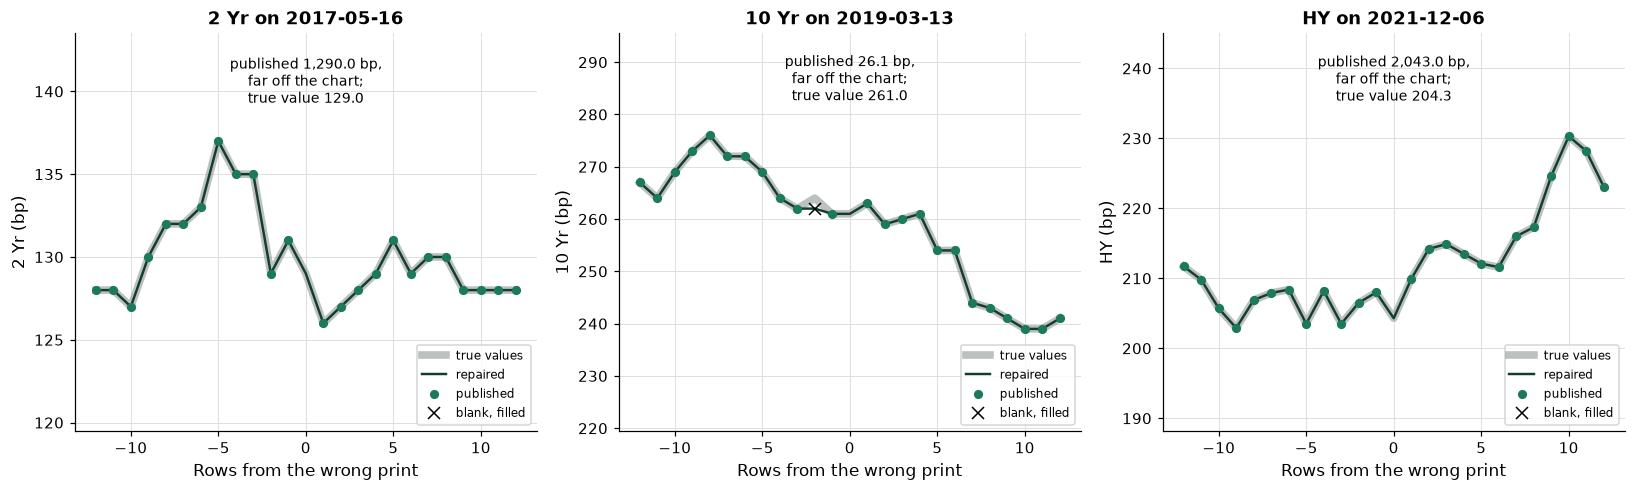

In [27]:
if answered('answer_2_4'):
    # one panel per wrong print: 12 rows each side, the true values (wide grey line), the repaired series (green line), and the published cells (dots)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    for ax, column in zip(axes, ["2 Yr", "10 Yr", "HY"]):
        date = [when for when, name in suspects if name == column][0]
        at = published.index.get_loc(date)
        rows = slice(at - 12, at + 13)
        x = np.arange(-12, 13)
        low, high = truth[column].iloc[rows].min(), truth[column].iloc[rows].max()
        pad = (high - low) * 0.5 + 1
        ax.plot(x, truth[column].iloc[rows], color=plotkit.GREY, linewidth=5, alpha=0.5, label="true values")
        ax.plot(x, repaired[column].iloc[rows], color=plotkit.GREEN_DARK, linewidth=1.6, label="repaired")
        shown = published[column].iloc[rows].where(lambda values: values.between(low - pad, high + pad))
        ax.plot(x, shown, "o", color=plotkit.GREEN, markersize=5, label="published")
        blank = published[column].iloc[rows].isna().to_numpy()
        ax.plot(x[blank], repaired[column].iloc[rows][blank], "x", color="black", markersize=8, label="blank, filled")
        ax.set_ylim(low - pad, high + pad)
        ax.annotate(f"published {published.at[date, column]:,.1f} bp,\nfar off the chart;\ntrue value {truth.at[date, column]:,.1f}",
                    xy=(0, high + pad * 0.55), ha="center", va="center", fontsize=9)
        ax.set_xlabel("Rows from the wrong print")
        ax.set_ylabel(f"{column} (bp)")
        ax.set_title(f"{column} on {date.date()}")
        ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print("not attempted yet")

* No blank is left. 7 of the 9 filled cells still differ from the true values, by up to 4.0 bp, because a carried-forward quote is yesterday's. The three wrong prints and the three blanks the second feed covered equal the true values exactly.
* How to read the figure: each panel shows 12 rows each side of a wrong print. The published dot is far off the chart, the true values (wide grey) and the repaired line (green) lie on each other, and a black cross marks a blank that the fill carried forward from the row before.
* The fill is acceptable here because the repair describes history and fits nothing. A model scored on a filled cell is scored against a quote that was never printed: 9 of 6,003 cells, 0.15 percent.

In [28]:
check('Question 2.4', answer_2_4, '31b3c9005032', places=1)

Question 2.4: correct


### 2.5 Build the two series

Q. Build the two series in bp. **levels** is a DataFrame with the columns `2s10s` (the repaired 10 Yr less the repaired 2 Yr, rounded to 2 decimals) and `HY`. **changes** is `levels.diff().dropna()`. Store a tuple (rows in `levels`, mean of the 2s10s) in **answer_2_5**, the mean to 2 decimals. The next cell, provided, draws both series with the held-out years as a closed box.

In [29]:
# the two series, in bp: the 2s10s is the 10 Yr less the 2 Yr, and the HY is the invented spread; changes are one row on the row before
levels = pd.DataFrame({"2s10s": (repaired["10 Yr"] - repaired["2 Yr"]).round(2), "HY": repaired["HY"]})
changes = levels.diff().dropna()
answer_2_5 = (len(levels), round(float(levels["2s10s"].mean()), 2))
print(f"levels: {len(levels):,} dates, 2 series; changes: {len(changes):,} rows; mean 2s10s {answer_2_5[1]:.2f} bp")

levels: 2,001 dates, 2 series; changes: 2,000 rows; mean 2s10s 69.96 bp


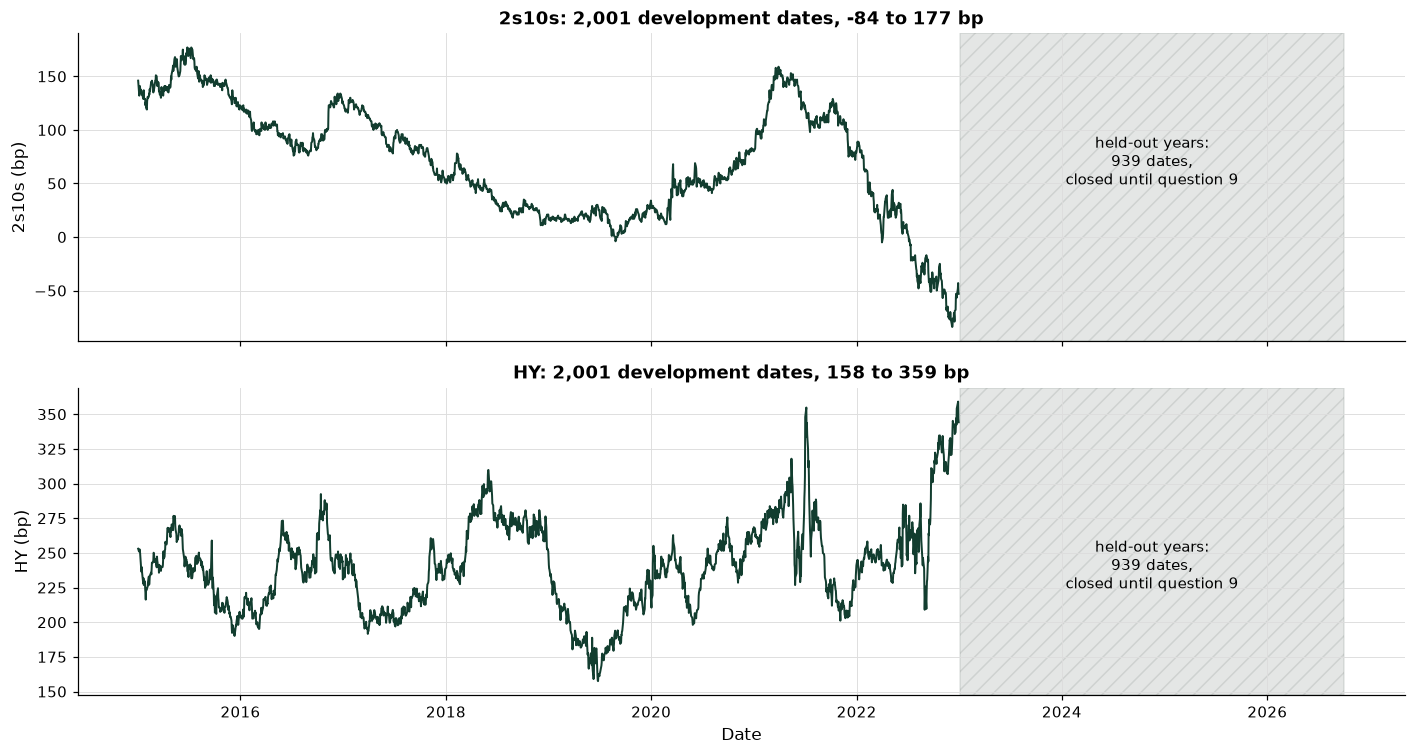

In [30]:
if answered('answer_2_5'):
    # the two repaired series over the development years; the held-out years are drawn as a closed box, with no value read
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    for ax, name in zip(axes, levels.columns):
        ax.plot(levels.index, levels[name], color=plotkit.GREEN_DARK, linewidth=1.3)
        ax.axvspan(held_out_dates[0], held_out_dates[-1], color=plotkit.GREY, alpha=0.2, hatch="//")
        middle = held_out_dates[0] + (held_out_dates[-1] - held_out_dates[0]) / 2
        ax.text(middle, levels[name].mean(), f"held-out years:\n{len(held_out_dates):,} dates,\nclosed until question 9", ha="center", va="center", fontsize=10)
        ax.set_ylabel(f"{name} (bp)")
        ax.set_title(f"{name}: {len(levels):,} development dates, {levels[name].min():,.0f} to {levels[name].max():,.0f} bp")
    axes[-1].set_xlabel("Date")
    fig.tight_layout()
    plt.show()
else:
    print("not attempted yet")

* 2,001 dates and 2,000 changes for each series. The 2s10s averaged 69.96 bp over these years, with a range of -84 to 177 bp; the invented HY ran from 158 to 359 bp.
* The hatched box is the held-out years: 939 dates, drawn with no value in it, because none has been read.

In [31]:
check('Question 2.5', answer_2_5, '00587f656f58', places=2)

Question 2.5: correct


### 2.6 Deliverable 2, committed

Q. Save the change log as `changes.csv` with LF line endings (`lineterminator="\n"`), and commit it with a message that names the deliverable.

In [32]:
# the change log as a file: LF line endings, and the old and new values with their source
log.to_csv("changes.csv", index=False, date_format="%Y-%m-%d", lineterminator="\n")
print((work / "changes.csv").read_text(encoding="utf-8"))

date,column,old,new,source
2017-05-16,2 Yr,1290.0,129.0,second feed
2015-09-16,2 Yr,,82.0,second feed
2019-03-13,10 Yr,26.1,261.0,second feed
2015-10-06,10 Yr,,205.0,second feed
2021-12-06,HY,2043.0,204.3,second feed
2016-01-20,HY,,217.5,second feed



In [33]:
!git -C "{work}" add changes.csv
!git -C "{work}" commit -q -m "Deliverable 2: the change log of the repair"
!git -C "{work}" log --oneline

e13ad15 Deliverable 2: the change log of the repair
a5f78ee Deliverable 1: the module, every test passing


## 3 Stationarity

**Deliverable 3.** Day 3's two tests, on the levels and on the changes of both series. The null hypotheses point opposite ways: ADF's is a unit root, KPSS's is stationarity.

### 3.1 ADF and KPSS

Q. Test the levels and the changes of both series with `tskit.adf_summary` and `tskit.kpss_summary`. Keep the results in **stationarity**, a DataFrame indexed by (series, form) with the columns `ADF p-value`, `KPSS p-value`, `ADF reads stationary` (the ADF p-value is below 0.05) and `KPSS reads stationary` (the KPSS p-value is at least 0.05). Store the four ADF p-values, in the order 2s10s levels, 2s10s changes, HY levels, HY changes, as a tuple in **answer_3_1**, to 4 decimals. The next cell, provided, shows the table.

In [34]:
# ADF (null: a unit root) and KPSS (null: stationary) on the levels and on the changes of both series
rows = []
for name in levels.columns:
    for form, series in (("levels", levels[name]), ("changes", changes[name])):
        adf, kpss = tskit.adf_summary(series), tskit.kpss_summary(series)
        rows.append({"series": name, "form": form, "ADF p-value": adf["p_value"], "KPSS p-value": kpss["p_value"],
                     "ADF reads stationary": adf["p_value"] < 0.05, "KPSS reads stationary": kpss["p_value"] >= 0.05})
stationarity = pd.DataFrame(rows).set_index(["series", "form"])
print(stationarity.round(4).to_string())
answer_3_1 = tuple(float(stationarity.loc[(name, form), "ADF p-value"]) for name in levels.columns for form in ("levels", "changes"))

                ADF p-value  KPSS p-value  ADF reads stationary  KPSS reads stationary
series form                                                                           
2s10s  levels        0.7900          0.01                 False                  False
       changes       0.0000          0.10                  True                   True
HY     levels        0.0791          0.01                 False                  False
       changes       0.0000          0.10                  True                   True


In [35]:
if answered('answer_3_1'):
    display(plotkit.styled(stationarity[["ADF p-value", "KPSS p-value"]], [], "ADF and KPSS p-values on the levels and the changes of both series", fmt="{:.4f}"))
else:
    print("not attempted yet")

<styled table: ADF and KPSS p-values on the levels and the changes of both series>

* **Levels.** The ADF p-value was 0.7900 for the 2s10s and 0.0791 for the HY: neither is below 0.05, so a unit root is not rejected. The HY's is the closer one. KPSS rejected stationarity for both.
* **Changes.** The ADF p-value was 0.0000 and 0.0000: a unit root is rejected, and KPSS does not reject stationarity.

In [36]:
check('Question 3.1', answer_3_1, '9586d300d6a8', places=4)

Question 3.1: correct


### 3.2 When the tests agree

Q. For how many of the two series do both tests read the **levels** as stationary (ADF rejects the unit root, and KPSS does not reject stationarity), and for how many the **changes**? Store a tuple (levels, changes) in **answer_3_2**.

In [37]:
# both tests read stationary: count the series where they agree, for levels and for changes
agree = stationarity["ADF reads stationary"] & stationarity["KPSS reads stationary"]
answer_3_2 = (int(agree.xs("levels", level="form").sum()), int(agree.xs("changes", level="form").sum()))
print(f"both tests read stationary: levels {answer_3_2[0]} of 2 series, changes {answer_3_2[1]} of 2 series")

both tests read stationary: levels 0 of 2 series, changes 2 of 2 series


**The decision the capstone expects.** A series that ADF cannot read as stationary and KPSS rejects is read as a unit root: it is differenced before a model that assumes a constant mean is fitted. Both tests reading the changes as stationary means the models of the level of a change are fitted on the changes. A change's miss is the level's miss, so scoring a model of the changes against the changes, in bp, scores it against the level too.

* Levels: 0 of 2 series. Changes: 2 of 2. The tests agree on the changes of both series and on no levels, so the models below are fitted on the changes (the smoothing and the baselines work on the levels, and are scored on the same miss).

In [38]:
check('Question 3.2', answer_3_2, 'e2b0910c600d')

Question 3.2: correct


## 4 Memory: the ACF

**Deliverable 4.** Day 4's questions: does a change remember the changes before it, and does the size of a change?

### 4.1 Lag one

Q. What is the lag-1 autocorrelation of each series' daily changes, from `tskit.acf_by_hand`? Store a tuple (2s10s, HY) in **answer_4_1**, to 4 decimals.

### 4.2 The band

Q. The 95 percent band is 1.96 divided by the square root of the number of changes. For each series, count how many of the first 40 autocorrelations (statsmodels' `acf` with `nlags=40`, lags 1 to 40, `result_object=False`) lie outside it, for the changes and for the squared changes. Store the counts in the order 2s10s changes, HY changes, 2s10s squares, HY squares as a tuple in **answer_4_2**. The next cell, provided, draws them.

In [39]:
# the first 40 autocorrelations of the changes and of the squared changes, and the band 1.96 / sqrt(n)
band = 1.96 / np.sqrt(len(changes))
acf_values = {}
for name in changes.columns:
    acf_values[(name, "change")] = acf(changes[name], nlags=40, result_object=False)[1:]
    acf_values[(name, "squared change")] = acf(changes[name] ** 2, nlags=40, result_object=False)[1:]
lag_one = tuple(tskit.acf_by_hand(changes[name], 1) for name in changes.columns)
outside = {key: int((np.abs(values) > band).sum()) for key, values in acf_values.items()}
print(f"band: plus and minus {band:.4f}")
print(f"lag-1 autocorrelation of the changes: 2s10s {lag_one[0]:.4f}, HY {lag_one[1]:.4f}")
for key, count in outside.items():
    print(f"{key[0]}, {key[1]}: {count} of 40 bars outside the band")
answer_4_1 = lag_one
answer_4_2 = (outside[("2s10s", "change")], outside[("HY", "change")], outside[("2s10s", "squared change")], outside[("HY", "squared change")])

band: plus and minus 0.0438
lag-1 autocorrelation of the changes: 2s10s -0.0237, HY 0.0099
2s10s, change: 4 of 40 bars outside the band
2s10s, squared change: 36 of 40 bars outside the band
HY, change: 6 of 40 bars outside the band
HY, squared change: 36 of 40 bars outside the band


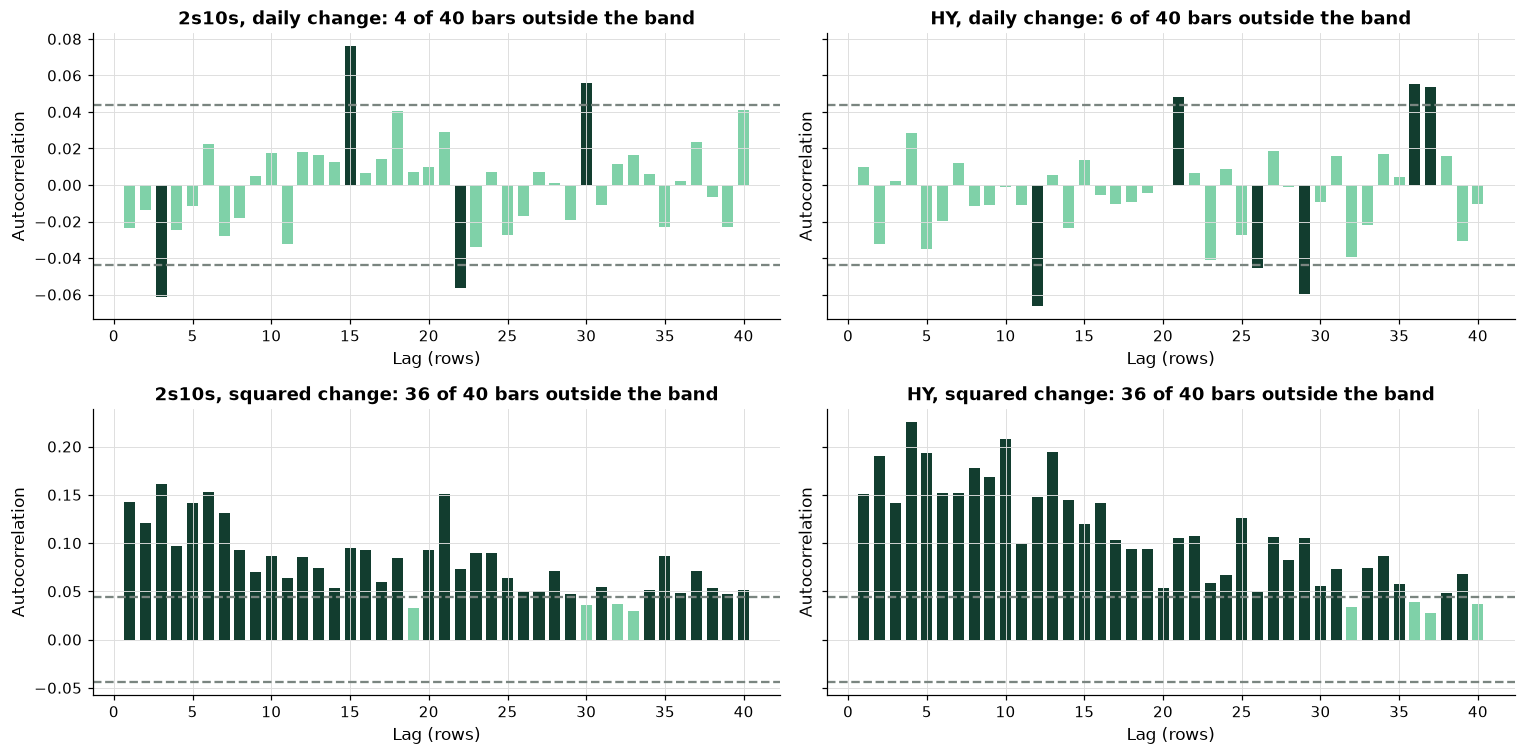

In [40]:
if answered('answer_4_2'):
    # the first 40 autocorrelations of the changes (top) and of the squared changes (bottom), with the band 1.96 / sqrt(n)
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey="row")
    band = 1.96 / np.sqrt(len(changes))
    for row, (label, transform) in enumerate([("daily change", lambda x: x), ("squared change", lambda x: x ** 2)]):
        for column, name in enumerate(changes.columns):
            ax = axes[row, column]
            values = acf(transform(changes[name]), nlags=40, result_object=False)[1:]
            lags = np.arange(1, 41)
            ax.bar(lags, values, color=np.where(np.abs(values) > band, plotkit.GREEN_DARK, plotkit.GREEN_LIGHT), width=0.7)
            ax.axhline(band, color=plotkit.GREY, linestyle="--")
            ax.axhline(-band, color=plotkit.GREY, linestyle="--")
            ax.set_title(f"{name}, {label}: {int((np.abs(values) > band).sum())} of 40 bars outside the band")
            ax.set_xlabel("Lag (rows)")
            ax.set_ylabel("Autocorrelation")
    fig.tight_layout()
    plt.show()
else:
    print("not attempted yet")

* **The level of a change has almost no memory.** The lag-1 autocorrelation was -0.0237 for the 2s10s and 0.0099 for the HY, against a band of plus and minus 0.0438. 4 and 6 of 40 bars lie outside the band, which is a few more than the 1.9 bars of 40 that white noise averages by chance (day 4), and none is large.
* **The size of a change does.** 36 and 36 of 40 bars of the squared changes lie outside the band, a long run of positive bars: big changes followed big changes. That is volatility clustering, and section 7 models it.

In [41]:
check('Question 4.1', answer_4_1, '230978dd5ae8', places=4)
check('Question 4.2', answer_4_2, '7cd2c623200f')

Question 4.1: correct
Question 4.2: correct


### 4.3 Ljung-Box

Q. Run the Ljung-Box test at 10 lags (`acorr_ljungbox(..., lags=[10], return_df=True)`, the `lb_pvalue` column) on the changes and on the squared changes of both series. Its null hypothesis is no autocorrelation up to lag 10. For how many of the four does it reject at 5 percent? Store the count in **answer_4_3**.

In [42]:
# Ljung-Box at 10 lags: the null is no autocorrelation up to lag 10, so a small p-value rejects it
ljung = {}
for name in changes.columns:
    ljung[(name, "change")] = float(acorr_ljungbox(changes[name], lags=[10], return_df=True)["lb_pvalue"].iloc[0])
    ljung[(name, "squared change")] = float(acorr_ljungbox(changes[name] ** 2, lags=[10], return_df=True)["lb_pvalue"].iloc[0])
for key, p_value in ljung.items():
    print(f"{key[0]}, {key[1]}: Ljung-Box p-value at 10 lags {p_value:.4g}")
answer_4_3 = sum(p_value < 0.05 for p_value in ljung.values())
print(f"rejected at 5 percent: {answer_4_3} of {len(ljung)}")

2s10s, change: Ljung-Box p-value at 10 lags 0.1545
2s10s, squared change: Ljung-Box p-value at 10 lags 1.344e-59
HY, change: Ljung-Box p-value at 10 lags 0.6288
HY, squared change: Ljung-Box p-value at 10 lags 7.865e-130
rejected at 5 percent: 2 of 4


* 2 of 4: both squared series (p-values of 1.3e-59 and 7.9e-130) and neither series of changes (p-values of 0.15 and 0.63). The test agrees with the bars.

In [43]:
check('Question 4.3', answer_4_3, '560eb9bb2f9b')

Question 4.3: correct


## 5 The Folds and the Baselines

**Deliverable 5.** Day 2's five walk-forward folds, and the three baselines every later model is scored against.

### 5.1 The folds

Q. Make day 2's five folds on the levels with `mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)` and keep them in **level_splits**. Make the same folds for the changes in **splits**: the changes start one row later, so each fold's positions shift down by one (`train[1:] - 1` and `test - 1`). Check each level fold with `mlkit.assert_past_only` and print it. Store a tuple (folds, training dates in fold 1, test dates in a fold) in **answer_5_1**.

In [44]:
# day 2's five folds on the levels; the changes start one row later, so each fold's positions shift down by one
level_splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
splits = [(train[1:] - 1, test - 1) for train, test in level_splits]
for number, (train, test) in enumerate(level_splits, start=1):
    mlkit.assert_past_only(levels.index[train], levels.index[test])
    print(f"fold {number}: fit on {len(train)} dates to {levels.index[train[-1]].date()}, "
          f"score {len(test)} from {levels.index[test[0]].date()} to {levels.index[test[-1]].date()}")
answer_5_1 = (len(level_splits), len(level_splits[0][0]), len(level_splits[0][1]))

fold 1: fit on 504 dates to 2017-01-05, score 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 756 dates to 2018-01-08, score 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1008 dates to 2019-01-11, score 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1260 dates to 2020-01-15, score 252 from 2020-01-16 to 2021-01-19
fold 5: fit on 1512 dates to 2021-01-19, score 252 from 2021-01-20 to 2022-01-19


* Five folds. Fold 1 fits on 504 dates to 2017-01-05 and scores 252 from 2017-01-06 to 2018-01-08; fold 5 scores 2021-01-20 to 2022-01-19. Every later model uses these folds, and none of them touches a held-out date.

In [45]:
check('Question 5.1', answer_5_1, 'ade91bc473c2')

Question 5.1: correct


### 5.2 The last value, the drift, and the training mean

Q. Score the three baselines on the levels with `tskit.walk_forward_score` and `tskit.naive_values(history, kind, n_train=n_train)` (kinds `last`, `drift`, `mean`). Keep each model's five fold MAEs in **dev_mae**: a dict with one DataFrame per series (index `fold`, 1 to 5), with the columns `last value`, `drift`, and `training mean` for now; later models add columns. Store the last value's mean MAE for each series (2s10s, HY) in **answer_5_2**, and the drift's in **answer_5_3**, both to 4 decimals.

In [46]:
# one table of five fold MAEs (bp) per series: the models go in as columns. First the three baselines, on the levels
dev_mae = {name: pd.DataFrame(index=pd.RangeIndex(1, 6, name="fold")) for name in levels.columns}
for name in levels.columns:
    for kind, label in (("last", "last value"), ("drift", "drift"), ("mean", "training mean")):
        scores, _ = tskit.walk_forward_score(levels[name], lambda history, n_train, kind=kind: tskit.naive_values(history, kind, n_train=n_train).to_numpy(), level_splits)
        dev_mae[name][label] = scores["mae"].to_numpy()
    print(f"{name}: " + ", ".join(f"{label} {dev_mae[name][label].mean():.4f}" for label in dev_mae[name].columns) + " bp")
answer_5_2 = tuple(dev_mae[name]["last value"].mean() for name in levels.columns)
answer_5_3 = tuple(dev_mae[name]["drift"].mean() for name in levels.columns)

2s10s: last value 2.1595, drift 2.1728, training mean 50.6111 bp
HY: last value 3.5002, drift 3.4999, training mean 29.9154 bp


* **The last value carried forward missed by 2.1595 bp on average for the 2s10s and 3.5002 bp for the HY**: the size of the average daily change, since carrying yesterday's value forward misses by the day's change. Day 2 found 2.1548 and 3.5018 on the unplanted file; the repaired series moves them in the third decimal, because 9 cells are carried-forward quotes.
* The drift: 2.1728 and 3.4999 bp. The training mean: 50.6111 and 29.9154 bp, a model that ignores where the series is now.
* The last value's own MAE ranged by fold from 1.65 to 2.81 bp for the 2s10s and from 2.80 to 5.11 bp for the HY: the size of the days differed by fold far more than the models below differ from each other.

In [47]:
check('Question 5.2', answer_5_2, '64027cb93ff1', places=4)
check('Question 5.3', answer_5_3, 'e134e1c81876', places=4)

Question 5.2: correct
Question 5.3: correct


## 6 Models of the Level

**Deliverable 6.** ARIMA, exponential smoothing, and LightGBM on lags, each scored on the same five folds and added to `dev_mae`.

### 6.1 How many terms

Q. Fit `tskit.arima_grid` (`max_p=2`, `max_q=2`) to the 2s10s changes of the first fold's training rows (`changes["2s10s"].iloc[splits[0][0]]`). Store the (p, q) with the lowest BIC in **answer_6_1**.

In [48]:
# the BIC of ARIMA(p, 0, q) for p and q up to 2, on the first fold's training changes of the 2s10s (day 5's grid)
first_train = changes["2s10s"].iloc[splits[0][0]].to_numpy()
grid = tskit.arima_grid(first_train, max_p=2, max_q=2)
best = grid.loc[grid["bic"].idxmin()]
answer_6_1 = (int(best["p"]), int(best["q"]))
print(grid.round(1).to_string(index=False))
print(f"lowest BIC at (p, q) = {answer_6_1}; fits that did not converge: {int((~grid['converged']).sum())} of {len(grid)}")

 p  q    aic    bic  converged
 0  0 2610.5 2618.9       True
 0  1 2609.4 2622.0       True
 0  2 2606.1 2623.0       True
 1  0 2610.0 2622.7       True
 1  1 2608.3 2625.2       True
 1  2 2607.9 2629.0       True
 2  0 2606.2 2623.1       True
 2  1 2608.2 2629.3       True
 2  2 2609.9 2635.2       True
lowest BIC at (p, q) = (0, 0); fits that did not converge: 0 of 9


* The lowest BIC was at (p, q) = (0, 0): no terms at all. BIC charges more per parameter than AIC, and it found nothing in the changes worth a parameter, which agrees with section 4. AR(1) and ARMA(1,1) are scored anyway, so the table shows what the terms cost.

In [49]:
check('Question 6.1', answer_6_1, '3736b71e8d86')

Question 6.1: correct


### 6.2 ARIMA

Q. Score AR(1) and ARMA(1,1) on the changes with `tskit.walk_forward_arima` and add them to `dev_mae` as the columns `AR(1)` and `ARMA(1,1)`. Store the ARMA(1,1) mean MAE for each series (2s10s, HY) in **answer_6_2**, to 4 decimals.

In [50]:
# AR(1) and ARMA(1,1) on the changes, scored on the changes' folds: a change's miss is the level's miss
for name in changes.columns:
    for order, label in (((1, 0, 0), "AR(1)"), ((1, 0, 1), "ARMA(1,1)")):
        scores, _ = tskit.walk_forward_arima(changes[name], order, splits)
        dev_mae[name][label] = scores["mae"].to_numpy()
    print(f"{name}: AR(1) {dev_mae[name]['AR(1)'].mean():.4f}, ARMA(1,1) {dev_mae[name]['ARMA(1,1)'].mean():.4f}, last value {dev_mae[name]['last value'].mean():.4f} bp")
answer_6_2 = tuple(dev_mae[name]["ARMA(1,1)"].mean() for name in changes.columns)

2s10s: AR(1) 2.1734, ARMA(1,1) 2.1750, last value 2.1595 bp


HY: AR(1) 3.5110, ARMA(1,1) 3.5126, last value 3.5002 bp


* ARMA(1,1): 2.1750 bp for the 2s10s and 3.5126 bp for the HY, against the last value's 2.1595 and 3.5002. AR(1) was 2.1734 and 3.5110. Each fold fits once on its training rows and runs through the fold's rows with the parameters fixed (`fit_arima` raises if the optimiser did not converge).

In [51]:
check('Question 6.2', answer_6_2, 'dcdf3a857ec5', places=4)

Question 6.2: correct


### 6.3 Exponential smoothing

Q. Score simple exponential smoothing and the damped trend on the **levels'** folds with `tskit.walk_forward_smoothing` (`trend="add", damped=True` for the second). Add them as `simple smoothing` and `damped trend`. Store simple smoothing's mean MAE for each series in **answer_6_3**, to 4 decimals.

In [52]:
# simple exponential smoothing and the damped trend, fitted on each fold's training levels
for name in levels.columns:
    scores, _ = tskit.walk_forward_smoothing(levels[name], level_splits)
    dev_mae[name]["simple smoothing"] = scores["mae"].to_numpy()
    scores, _ = tskit.walk_forward_smoothing(levels[name], level_splits, trend="add", damped=True)
    dev_mae[name]["damped trend"] = scores["mae"].to_numpy()
    print(f"{name}: simple smoothing {dev_mae[name]['simple smoothing'].mean():.4f}, damped trend {dev_mae[name]['damped trend'].mean():.4f} bp")
answer_6_3 = tuple(dev_mae[name]["simple smoothing"].mean() for name in levels.columns)

2s10s: simple smoothing 2.1738, damped trend 2.1736 bp


HY: simple smoothing 3.5124, damped trend 3.5129 bp


* Simple smoothing: 2.1738 and 3.5124 bp. Damped trend: 2.1736 and 3.5129. A smoothing that gives the newest value all its weight is the last value, and on these folds the fitted weights sat close to it.

In [53]:
check('Question 6.3', answer_6_3, '244f7d06d8e1', places=4)

Question 6.3: correct


### 6.4 Lag features, with the proof

Q. Build the lag features for each series with `tskit.lag_features(changes, name, [1, 2, 5], [5, 20])`, keep them in **features** (a dict by series), and prove with `tskit.assert_features_past_only` at positions 300, 900, and 1500 that no feature uses its own row. Store the number of feature columns of one series in **answer_6_4**.

### 6.5 LightGBM

Q. Score LightGBM on those features with `tskit.walk_forward_lgbm`, with its defaults (column `LightGBM defaults`) and with day 8's settings (column `LightGBM tuned`): `tuned = dict(objective="huber", learning_rate=0.01, n_estimators=25, num_leaves=4, min_child_samples=5)`. Store the tuned mean MAE for each series in **answer_6_5**, to 4 decimals. The two cells after it, provided, show every model's scores and draw them.

In [54]:
# lag features: lags 1, 2, and 5, windows of 5 and 20, the other series' lag 1, the weekday and the month; every one built from earlier rows
lags, windows = [1, 2, 5], [5, 20]
tuned = dict(objective="huber", learning_rate=0.01, n_estimators=25, num_leaves=4, min_child_samples=5)   # day 8's choice on the 10 Yr
features = {}
for name in changes.columns:
    features[name] = tskit.lag_features(changes, name, lags, windows)
    # the proof: change every row from a position on, and no feature up to that position may move
    tskit.assert_features_past_only(lambda frame: tskit.lag_features(frame, name, lags, windows), changes, [300, 900, 1500])
    scores, _ = tskit.walk_forward_lgbm(features[name], changes[name], splits)
    dev_mae[name]["LightGBM defaults"] = scores["mae"].to_numpy()
    scores, _ = tskit.walk_forward_lgbm(features[name], changes[name], splits, **tuned)
    dev_mae[name]["LightGBM tuned"] = scores["mae"].to_numpy()
    print(f"{name}: {features[name].shape[1]} features; LightGBM defaults {dev_mae[name]['LightGBM defaults'].mean():.4f}, tuned {dev_mae[name]['LightGBM tuned'].mean():.4f} bp")
answer_6_4 = features["2s10s"].shape[1]
answer_6_5 = tuple(dev_mae[name]["LightGBM tuned"].mean() for name in changes.columns)

2s10s: 12 features; LightGBM defaults 2.4994, tuned 2.1686 bp


HY: 12 features; LightGBM defaults 3.7746, tuned 3.5014 bp


* 12 features: 3 lags, a mean, a standard deviation, and a mean absolute value for each of 2 windows, the other series' lag 1, the weekday, and the month. The proof passed at all three positions.
* LightGBM with its defaults missed by 2.4994 and 3.7746 bp, well above the last value. With day 8's settings, which were chosen on the 10 Yr's folds and not touched here, it missed by 2.1686 and 3.5014 bp.

In [55]:
check('Question 6.4', answer_6_4, '7c333d91cc2b')
check('Question 6.5', answer_6_5, '82ba4553fee2', places=4)

Question 6.4: correct
Question 6.5: correct


In [56]:
if answered('answer_6_5'):
    # every model's development scores, one table for each series: the lowest value in each column is marked
    dev_table = {}
    for name in levels.columns:
        frame = dev_mae[name]
        dev_table[name] = pd.DataFrame({"mean MAE (bp)": frame.mean(), "MASE": frame.mean() / frame["last value"].mean(),
                                        "folds below the last value": frame.lt(frame["last value"], axis=0).sum()})
        display(plotkit.styled(dev_table[name], ["mean MAE (bp)", "MASE"], f"{name}: five-fold development scores against the last value carried forward", higher_is_better=False, fmt="{:.4f}"))
else:
    print("not attempted yet")

,mean MAE (bp),MASE,folds below the last value
last value,2.1595,1.0000,0
drift,2.1728,1.0062,0
training mean,50.6111,23.4362,0
AR(1),2.1734,1.0064,0
"ARMA(1,1)",2.1750,1.0071,1
simple smoothing,2.1738,1.0066,1
damped trend,2.1736,1.0065,1
LightGBM defaults,2.4994,1.1574,0
LightGBM tuned,2.1686,1.0042,0


,mean MAE (bp),MASE,folds below the last value
last value,3.5002,1.0000,0
drift,3.4999,0.9999,2
training mean,29.9154,8.5467,0
AR(1),3.5110,1.0031,2
"ARMA(1,1)",3.5126,1.0035,2
simple smoothing,3.5124,1.0035,2
damped trend,3.5129,1.0036,2
LightGBM defaults,3.7746,1.0784,0
LightGBM tuned,3.5014,1.0003,3


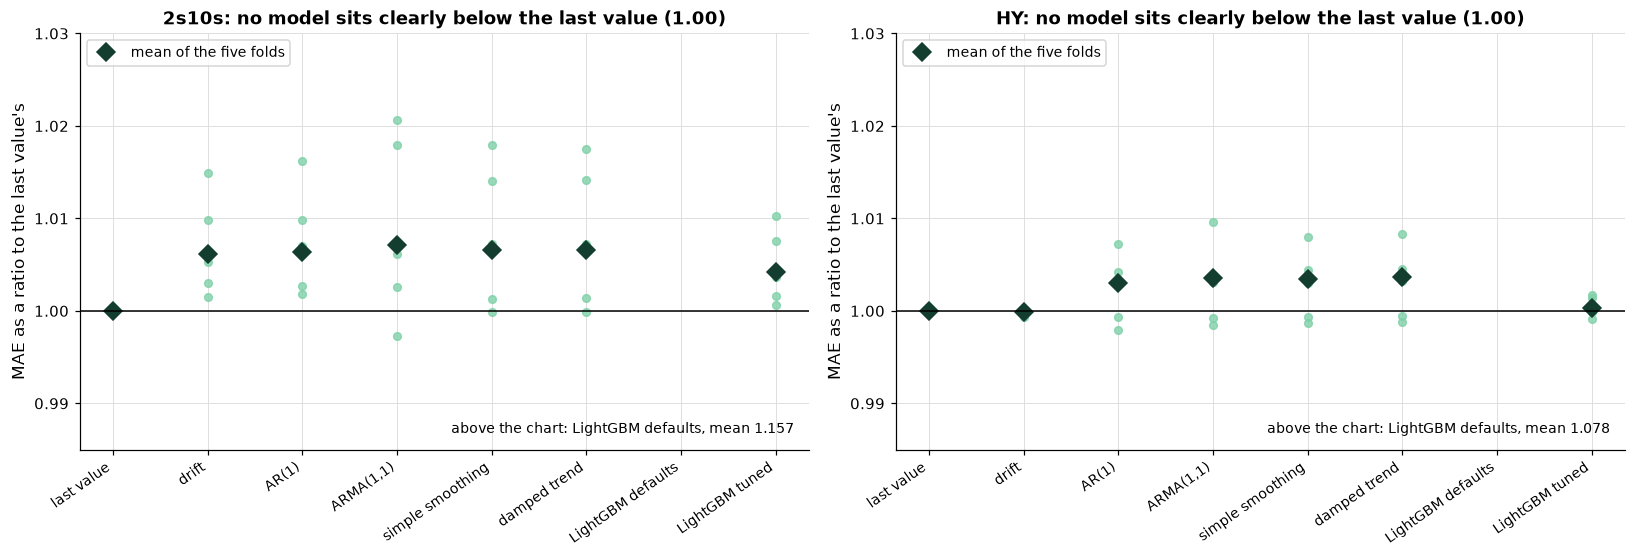

In [57]:
if answered('answer_6_5'):
    # each model's MAE as a ratio to the last value's, fold by fold (dots) and on average (diamond); the training mean, at about 23 and 9, is not drawn
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
    for ax, name in zip(axes, levels.columns):
        frame = dev_mae[name].drop(columns="training mean")
        by_fold = frame.div(frame["last value"], axis=0)
        positions = np.arange(frame.shape[1])
        for fold in by_fold.index:
            ax.plot(positions, by_fold.loc[fold], "o", color=plotkit.GREEN_LIGHT, markersize=5, alpha=0.8)
        ax.plot(positions, frame.mean() / frame["last value"].mean(), "D", color=plotkit.GREEN_DARK, markersize=8, label="mean of the five folds")
        ax.axhline(1, color="black", linewidth=1)
        ax.set_xticks(positions, list(frame.columns), rotation=35, ha="right", fontsize=9)
        ax.set_ylabel("MAE as a ratio to the last value's")
        # zoom on the cluster at 1.0; a model above the chart is named in the corner
        ax.set_ylim(min(0.985, by_fold.min().min() - 0.005), 1.03)
        above = [model for model in frame.columns if (by_fold[model] > 1.03).any()]
        if above:
            ax.annotate(f"above the chart: {', '.join(above)}, mean {(frame[above[0]].mean() / frame['last value'].mean()):.3f}",
                        xy=(0.98, 0.04), xycoords="axes fraction", ha="right", fontsize=9)
        ax.set_title(f"{name}: no model sits clearly below the last value (1.00)")
        ax.legend(loc="upper left", fontsize=9)
    fig.tight_layout()
    plt.show()
else:
    print("not attempted yet")

* **No model for the 2s10s was closer than the last value on the five-fold mean**, and for the HY only the drift was, by 0.0003 bp and in 2 folds of 5. Every model except LightGBM with its defaults sat within 0.7 percent of the last value's mean (MASE of 1.0 is the last value); LightGBM with its defaults was 15.7 and 7.8 percent further.
* How to read the figure: each dot is a model's MAE in one fold as a ratio to the last value's in the same fold, and each diamond is the mean. The dots of one model spread about as wide as the diamonds of different models, and every dot lies close to 1.00: a gap between two diamonds is no larger than the gap between two folds of the same model. LightGBM with its defaults sits above the chart (its mean is named in the corner).

## 7 Volatility: the Size of a Change

**Deliverable 7.** Section 4 found memory in the squared changes. GARCH(1,1) describes it, and two simpler rules are the yardsticks.

### 7.1 GARCH(1,1) on the development years

Q. Fit `tskit.fit_garch` to all of each series' development changes (`.to_numpy()`), take alpha and beta from `params[2:4]`, and keep a DataFrame **garch_table** indexed by series with the columns `alpha`, `beta`, `persistence`, and `half-life (rows)` (`tskit.garch_half_life`). Store the persistence for each series (2s10s, HY) in **answer_7_1**, to 3 decimals.

In [58]:
# GARCH(1,1) on all the development changes: alpha, beta, persistence, and the half-life of a shock
garch_rows = []
for name in changes.columns:
    fitted = tskit.fit_garch(changes[name].to_numpy())
    alpha, beta = (float(v) for v in np.asarray(fitted.params)[2:4])
    garch_rows.append({"series": name, "alpha": alpha, "beta": beta, "persistence": alpha + beta,
                       "half-life (rows)": tskit.garch_half_life(alpha, beta)})
garch_table = pd.DataFrame(garch_rows).set_index("series")
print(garch_table.round(3).to_string())
answer_7_1 = tuple(float(v) for v in garch_table["persistence"])

        alpha   beta  persistence  half-life (rows)
series                                             
2s10s   0.041  0.952        0.994           113.792
HY      0.129  0.837        0.966            20.185


* **2s10s:** alpha 0.041, beta 0.952, persistence 0.994: a shock to the variance halved in 114 rows. **HY:** alpha 0.129, beta 0.837, persistence 0.966, a half-life of 20 rows. This fit uses all the development years and describes them; the walk-forward scoring below refits on each fold.

In [59]:
check('Question 7.1', answer_7_1, '81bb289d6e59', places=3)

Question 7.1: correct


### 7.2 Three values for the size

Q. The size of a change is its absolute value. Score three values for it on the changes' folds: a **constant size** (the training mean of the sizes, held fixed), the **average of the last 20 sizes** (`rolling(20).mean().shift(1)`), and `tskit.walk_forward_garch`. Use `tskit.walk_forward_score` on `changes[name].abs()` for the first two. Keep the five fold MAEs in **dev_size** (a dict of DataFrames with the columns `constant size`, `20-row average`, `GARCH(1,1)`) and the GARCH volatility in **garch_volatility** (a dict of Series). Store the GARCH mean MAE as a ratio to the constant's, for each series, in **answer_7_2**, to 4 decimals. The next cell, provided, draws fold 5.

In [60]:
# the size of a change is its absolute value: a constant size, the average of the last 20 sizes, and GARCH(1,1), on the changes' folds
dev_size = {name: pd.DataFrame(index=pd.RangeIndex(1, 6, name="fold")) for name in changes.columns}
garch_volatility = {}
for name in changes.columns:
    size = changes[name].abs()
    scores, _ = tskit.walk_forward_score(size, lambda history, n_train: np.full(len(history) - n_train, history.iloc[:n_train].mean()), splits)
    dev_size[name]["constant size"] = scores["mae"].to_numpy()
    scores, _ = tskit.walk_forward_score(size, lambda history, n_train: history.rolling(20).mean().shift(1).iloc[n_train:].to_numpy(), splits)
    dev_size[name]["20-row average"] = scores["mae"].to_numpy()
    scores, garch_volatility[name] = tskit.walk_forward_garch(changes[name], splits)
    dev_size[name]["GARCH(1,1)"] = scores["mae"].to_numpy()
size_table = {}
for name in changes.columns:
    frame = dev_size[name]
    size_table[name] = pd.DataFrame({"mean MAE (bp)": frame.mean(), "ratio to the constant": frame.mean() / frame["constant size"].mean(),
                                     "folds below the constant": frame.lt(frame["constant size"], axis=0).sum()})
    print(name)
    print(size_table[name].round(4).to_string())
answer_7_2 = tuple(dev_size[name]["GARCH(1,1)"].mean() / dev_size[name]["constant size"].mean() for name in changes.columns)

2s10s
                mean MAE (bp)  ratio to the constant  folds below the constant
constant size          1.4974                 1.0000                         0
20-row average         1.4560                 0.9724                         3
GARCH(1,1)             1.4595                 0.9747                         3
HY
                mean MAE (bp)  ratio to the constant  folds below the constant
constant size          2.1832                 1.0000                         0
20-row average         2.1256                 0.9736                         3
GARCH(1,1)             2.0814                 0.9534                         3


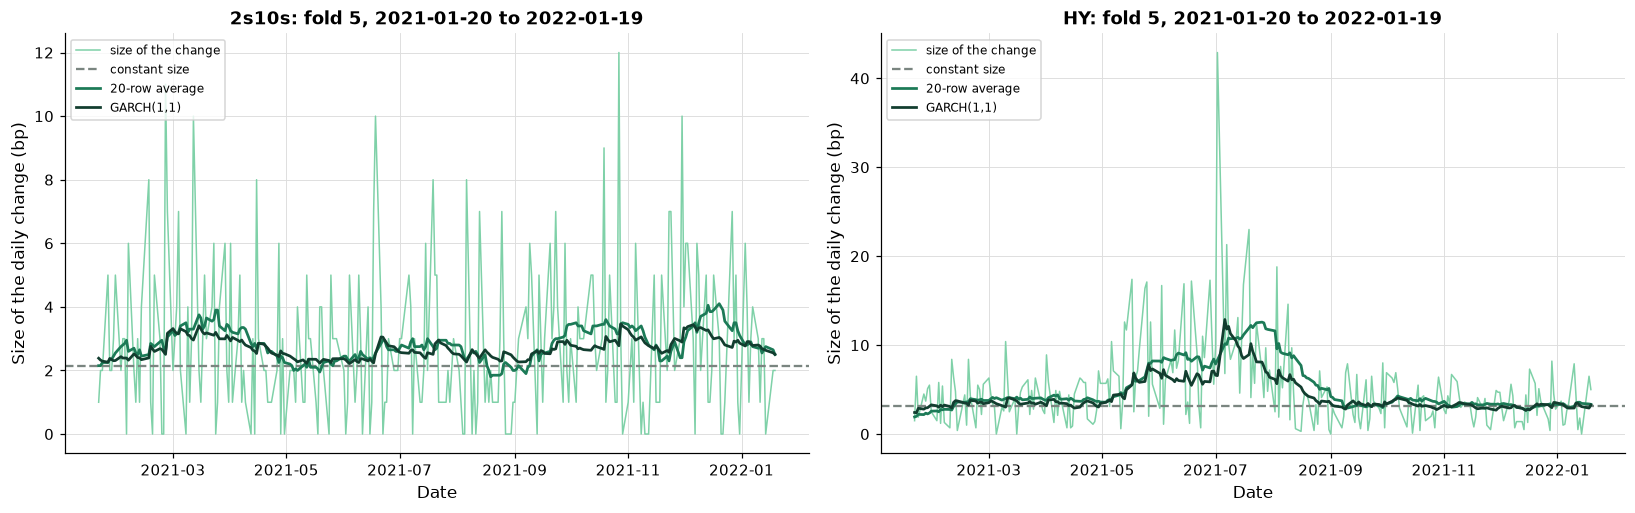

In [61]:
if answered('answer_7_2'):
    # the last fold's test dates: the size of each change, and three values for it: a constant, the average of the last 20 sizes, and GARCH(1,1)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    for ax, name in zip(axes, changes.columns):
        train, test = splits[-1]
        size = changes[name].abs()
        dates = changes.index[test]
        ax.plot(dates, size.iloc[test], color=plotkit.GREEN_LIGHT, linewidth=1, label="size of the change")
        ax.axhline(size.iloc[train].mean(), color=plotkit.GREY, linestyle="--", label="constant size")
        ax.plot(dates, size.rolling(20).mean().shift(1).iloc[test], color=plotkit.GREEN, linewidth=1.8, label="20-row average")
        ax.plot(dates, garch_volatility[name].iloc[test] * tskit.ABS_SCALE, color=plotkit.GREEN_DARK, linewidth=1.8, label="GARCH(1,1)")
        ax.set_xlabel("Date")
        ax.set_ylabel("Size of the daily change (bp)")
        ax.set_title(f"{name}: fold 5, {dates[0].date()} to {dates[-1].date()}")
        ax.legend(loc="upper left", fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print("not attempted yet")

* **GARCH(1,1) scored 0.9747 of the constant's MAE for the 2s10s and 0.9534 for the HY**, lower in 3 of 5 folds each. The 20-row average scored 0.9724 and 0.9736.
* How to read the figure: the thin light line is the size of each change in fold 5, the dashed line is the constant, and the two bold lines follow the clusters. Unlike the level of the change, the size had something to find, and the gain was a few percent, not a landslide.

In [62]:
check('Question 7.2', answer_7_2, 'c9d0e9c26473', places=4)

Question 7.2: correct


## 8 The Choice

**Deliverable 8.** A choice made after seeing the held-out scores is not a choice. Write the rule as a function and test it, apply it to the development folds, write the result down, and commit it, all before section 9.

### 8.1 The rule, as a tested function

Q. Add `choose_model(fold_mae, baseline, min_folds=3)` to `tskit.py`, docstring first. `fold_mae` is a DataFrame with one row per fold and one column per model (lower is better); it returns the name of the chosen column. A model replaces the baseline only if its mean over the folds is lower than the baseline's **and** it is lower in at least `min_folds` folds; among those that qualify the lowest mean wins, a tie going to the column that comes first; with none, the baseline stays. It raises `ValueError` for a baseline that is not a column, a `min_folds` outside 1 to the number of folds, and a NaN. Add `test_choose_model_keeps_the_baseline_unless_a_model_wins_on_the_mean_and_on_enough_folds` to `test_tskit.py`: one model lower in 3 folds but higher on the mean, one lower in 3 folds and lower on the mean, one lower in only 2 folds with the lowest mean (it wins only with `min_folds=2`), and the three refusals. Run the cells, reload the module, run pytest, and store the number of tests that passed in **answer_8_1**.

In [63]:
%%writefile -a tskit.py


def choose_model(fold_mae: pd.DataFrame, baseline: str, min_folds: int = 3) -> str:
    """The name of the model the development folds choose, with the baseline kept unless a model clearly beats it.

    Inputs: fold_mae, a DataFrame with one row per fold and one column per model, each cell the model's error on that fold
    (MAE in bp: lower is better); baseline, the name of the column that is kept unless a model replaces it; min_folds, how
    many folds a model must be lower than the baseline in (3 of 5 is a majority).
    A model replaces the baseline only if its mean over the folds is lower than the baseline's AND it is lower than the
    baseline in at least min_folds folds. Among the models that qualify, the lowest mean wins; a tie goes to the column that
    comes first. With no model that qualifies, the baseline is chosen.
    Output: the chosen column name. Only the development folds go in: a held-out score is never an input.
    Raises ValueError for a baseline that is not a column, a min_folds outside 1 to the number of folds, or a NaN.
    """
    if baseline not in fold_mae.columns:
        raise ValueError(f"baseline {baseline!r} is not a column: {list(fold_mae.columns)}")
    if not 1 <= min_folds <= len(fold_mae):
        raise ValueError(f"min_folds must be from 1 to {len(fold_mae)}, not {min_folds}")
    if fold_mae.isna().any().any():
        raise ValueError("fold_mae has a NaN: score every model on every fold first")
    means = fold_mae.mean()
    below = fold_mae.lt(fold_mae[baseline], axis=0).sum()
    qualify = [name for name in fold_mae.columns if name != baseline and means[name] < means[baseline] and below[name] >= min_folds]
    return min(qualify, key=lambda name: means[name]) if qualify else baseline

Appending to tskit.py


In [64]:
%%writefile -a test_tskit.py


def test_choose_model_keeps_the_baseline_unless_a_model_wins_on_the_mean_and_on_enough_folds():
    folds = pd.DataFrame({"last": [2.0] * 5,
                          "lower in 3 folds, higher mean": [1.9, 1.9, 1.9, 2.5, 2.5],
                          "lower in 3 folds, lower mean": [1.8, 1.8, 1.8, 2.1, 2.1],
                          "lower in 2 folds, lowest mean": [1.0, 1.0, 2.1, 2.1, 2.1]})
    # only the third model is lower on the mean and in a majority of folds
    assert tskit.choose_model(folds, "last") == "lower in 3 folds, lower mean"
    # asking for 2 folds lets the fourth model in, and it has the lowest mean
    assert tskit.choose_model(folds, "last", min_folds=2) == "lower in 2 folds, lowest mean"
    # without the winners the baseline stays
    assert tskit.choose_model(folds[["last", "lower in 3 folds, higher mean"]], "last") == "last"
    with pytest.raises(ValueError, match="not a column"):
        tskit.choose_model(folds, "missing")
    with pytest.raises(ValueError, match="min_folds"):
        tskit.choose_model(folds, "last", min_folds=6)
    with pytest.raises(ValueError, match="NaN"):
        tskit.choose_model(folds.assign(last=[2.0, 2.0, np.nan, 2.0, 2.0]), "last")

Appending to test_tskit.py


In [65]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print("choose_model written" if hasattr(tskit, "choose_model") else "choose_model not written yet")

choose_model written


In [66]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................................................                     [100%]
52 passed in 5.98s



In [67]:
answer_8_1 = int(re.search(r"(\d+) passed", result.stdout).group(1))
print(f"Tests passed: {answer_8_1}")

Tests passed: 52


* `52 passed`: the 51 tests of days 1 to 9 and the one new test. The function takes the fold table and nothing else, so no held-out score can reach it.

In [68]:
check('Question 8.1', answer_8_1, 'a21ad0eb8cc1')

Question 8.1: correct


In [69]:
!git -C "{work}" add tskit.py test_tskit.py
!git -C "{work}" commit -q -m "Deliverable 8: choose_model and its test"
!git -C "{work}" log --oneline

90bbe44 Deliverable 8: choose_model and its test


e13ad15 Deliverable 2: the change log of the repair
a5f78ee Deliverable 1: the module, every test passing


### 8.2 Apply the rule

Q. Apply `choose_model` to the development folds: for the level of the change, `dev_mae[name]` with the baseline `last value`; for its size, `dev_size[name]` with the baseline `constant size`. Keep the choices in **level_choice** and **size_choice** (dicts by series). Store a tuple (level 2s10s, level HY, size 2s10s, size HY) of model names, spelled as in the columns, in **answer_8_2**.

In [70]:
# the rule, applied to the development folds only: the level of the change (baseline: the last value) and its size (baseline: a constant)
level_choice = {name: tskit.choose_model(dev_mae[name], "last value") for name in levels.columns}
size_choice = {name: tskit.choose_model(dev_size[name], "constant size") for name in changes.columns}
for name in levels.columns:
    print(f"{name}: level -> {level_choice[name]}; size -> {size_choice[name]}")
answer_8_2 = (level_choice["2s10s"], level_choice["HY"], size_choice["2s10s"], size_choice["HY"])

2s10s: level -> last value; size -> 20-row average
HY: level -> last value; size -> GARCH(1,1)


**The decision the capstone expects.** The last value for the level of both series, and for the size the model that cleared the rule: the 20-row average for the 2s10s and GARCH(1,1) for the HY. The rule keeps a baseline unless a model is lower on the mean and in a majority of folds. A model that wins the mean through one fold, or beats the baseline in three folds by less than it loses the other two, has not shown anything the next stretch of dates can be held to. Writing the rule first, as a tested function, is what keeps the choice from following the scores.

* Level: the last value for the 2s10s, and the last value for the HY. The closest rival for the HY, the drift, was lower on the mean by 0.0003 bp and in 2 of 5 folds, so it did not clear the rule. Size: the 20-row average for the 2s10s and GARCH(1,1) for the HY, each lower than the constant in 3 of 5 folds with a lower mean.

In [71]:
check('Question 8.2', answer_8_2, 'c4ab9f0b3ad3')

Question 8.2: correct


### 8.3 Deliverable 8: the choice, committed

Q. Write your choice in a markdown cell below: the model for the level of each series and the model for its size, and your reasons in full, from the development folds only. Then write it to `choice.md` and commit it. **`open_held_out_rows()` stops before the first use unless `choice.md` has been committed.** There is no check: the expected answer is whatever the numbers support.

In [72]:
%%writefile choice.md
# The choice, made on the development years

Written and committed before the held-out years were opened.

**The rule.** A model replaces the baseline only if its mean over the five development folds is lower than the baseline's and it is lower than the baseline in at least 3 of the 5 folds. Among the models that qualify, the lowest mean wins. The baseline for the level of a change is the last value carried forward, and for its size a constant size. The rule was written as `choose_model` and tested before any model was scored.

**The level of the change.** For the 2s10s the choice is the last value carried forward: the lowest mean among the other models was 2.1686 bp against its 2.1595 bp. For the HY the choice is the last value carried forward too: the drift's mean was 3.4999 bp against 3.5002 bp, but it was lower in only 2 of 5 folds.

**The size of the change.** For the 2s10s the choice is the average of the last 20 sizes (0.9724 of the constant's MAE, lower in 3 of 5 folds). For the HY the choice is GARCH(1,1) (0.9534 of the constant's MAE, lower in 3 of 5 folds).

**What this does not settle.** The development folds chose these models. They say nothing yet about years the folds did not include.

Writing choice.md


In [73]:
!git -C "{work}" add choice.md
!git -C "{work}" commit -q -m "Deliverable 8: the choice, made on the development years"
!git -C "{work}" log --oneline

96b1b90 Deliverable 8: the choice, made on the development years
90bbe44 Deliverable 8: choose_model and its test
e13ad15 Deliverable 2: the change log of the repair
a5f78ee Deliverable 1: the module, every test passing


* The choice is on the record, dated by Git, before any held-out row is read. The tskit change was committed just before it, in question 8.1.

## 9 The Held-Out Years, Opened Once

**Deliverable 9.** Everything so far used the development years. Now the 939 held-out dates are opened, once, and each model you scored is scored once more, with the same functions and the same settings, on rows no choice has seen. Nothing is refitted to improve a score, and nothing chosen so far is changed after this section.

### 9.1 Open the held-out years

Q. Use `open_held_out_rows()` once. It reads the held-out levels (2s10s and HY, bp) from the files; it stops if `choice.md` is not committed, and stops the second time it is used. Join the rows to `levels` in **full** and make **full_changes** (`full.diff().dropna()`). Make one fold of each kind in **level_split** and **change_split**: fit on every development date, test on every held-out date. The change fold starts one row earlier, as in question 5.1: `n_dev = len(levels)`, then `np.arange(n_dev - 1)` and `np.arange(n_dev - 1, len(full) - 1)`. Store a tuple (held-out rows, the last held-out date as text `YYYY-MM-DD`) in **answer_9_1**.

In [74]:
# open the held-out years ONCE (the function stops if it is used a second time), and join them to the development levels
held_out = open_held_out_rows()
full = pd.concat([levels, held_out])
full_changes = full.diff().dropna()
n_dev = len(levels)
# one fold of each kind: fit on every development date, then run through every held-out date with the fit held fixed
level_split = [(np.arange(n_dev), np.arange(n_dev, len(full)))]
change_split = [(np.arange(n_dev - 1), np.arange(n_dev - 1, len(full) - 1))]
print(f"held-out rows: {len(held_out):,}, {held_out.index[0].date()} to {held_out.index[-1].date()}; blank cells: {int(held_out.isna().sum().sum())}")
answer_9_1 = (len(held_out), str(held_out.index[-1].date()))

held-out rows: 939, 2023-01-03 to 2026-10-02; blank cells: 0


* 939 held-out dates, 2023-01-03 to 2026-10-02, and no blank cell. The guard let the first use through because `choice.md` was committed; a second use would have stopped.
* Each model below is fitted once, on all 2,001 development dates, and then run through the 939 held-out dates with its coefficients held fixed. The development folds refitted every 252 dates, so this is a different exercise from the folds, and a harder one for a model whose coefficients drift.

In [75]:
check('Question 9.1', answer_9_1, 'da2a5ba306e0')

Question 9.1: correct


### 9.2 Score every model once

Q. Score the baselines, AR(1), ARMA(1,1), simple smoothing, the damped trend, and LightGBM with its defaults and with `tuned`, each once, with the functions of sections 5 and 6 and `level_split` or `change_split` in place of the folds. Build the held-out lag features from `full_changes` (`lags` and `windows` as before). Keep each model's MAE in **held_mae**: a dict with one Series per series, indexed by the model names of `dev_mae`. Store the held-out MAE of the model your rule chose for each series (2s10s, HY) in **answer_9_2**, to 4 decimals.

### 9.3 How many models were below the last value

Q. How many of the eight other models had a held-out MAE below the last value's, for each series? A gap of less than a millionth of a bp is a tie, not a win (`held_mae[name]["last value"] - 1e-6`). Store a tuple (2s10s, HY) in **answer_9_3**.

In [76]:
# every model of the development table, scored ONCE on the held-out years: fitted on the development dates, then run through the held-out dates
held_mae = {name: {} for name in full.columns}
for name in full.columns:
    level, change = full[name], full_changes[name]
    for kind, label in (("last", "last value"), ("drift", "drift"), ("mean", "training mean")):
        scores, _ = tskit.walk_forward_score(level, lambda history, n_train, kind=kind: tskit.naive_values(history, kind, n_train=n_train).to_numpy(), level_split)
        held_mae[name][label] = float(scores["mae"].iloc[0])
    for order, label in (((1, 0, 0), "AR(1)"), ((1, 0, 1), "ARMA(1,1)")):
        held_mae[name][label] = float(tskit.walk_forward_arima(change, order, change_split)[0]["mae"].iloc[0])
    held_mae[name]["simple smoothing"] = float(tskit.walk_forward_smoothing(level, level_split)[0]["mae"].iloc[0])
    held_mae[name]["damped trend"] = float(tskit.walk_forward_smoothing(level, level_split, trend="add", damped=True)[0]["mae"].iloc[0])
    held_features = tskit.lag_features(full_changes, name, lags, windows)
    held_mae[name]["LightGBM defaults"] = float(tskit.walk_forward_lgbm(held_features, change, change_split)[0]["mae"].iloc[0])
    held_mae[name]["LightGBM tuned"] = float(tskit.walk_forward_lgbm(held_features, change, change_split, **tuned)[0]["mae"].iloc[0])
held_mae = {name: pd.Series(values) for name, values in held_mae.items()}
print(pd.DataFrame(held_mae).round(4).to_string())
answer_9_2 = (held_mae["2s10s"][level_choice["2s10s"]], held_mae["HY"][level_choice["HY"]])
# a gap of less than a millionth of a bp is a tie, not a win (a smoothing fitted with a weight of 1 repeats the last value)
answer_9_3 = tuple(int((held_mae[name].drop("last value") < held_mae[name]["last value"] - 1e-6).sum()) for name in full.columns)
print(f"chosen model's held-out MAE: 2s10s {answer_9_2[0]:.4f} bp, HY {answer_9_2[1]:.4f} bp")
print(f"models of {len(held_mae['HY']) - 1} with a held-out MAE below the last value's: 2s10s {answer_9_3[0]}, HY {answer_9_3[1]}")

                     2s10s       HY
last value          2.9542   3.9820
drift               2.9638   3.9794
training mean      68.3821  46.7385
AR(1)               2.9560   3.9789
ARMA(1,1)           2.9507   3.9797
simple smoothing    2.9523   3.9820
damped trend        2.9541   3.9820
LightGBM defaults   3.1478   4.3720
LightGBM tuned      2.9609   3.9787
chosen model's held-out MAE: 2s10s 2.9542 bp, HY 3.9820 bp
models of 8 with a held-out MAE below the last value's: 2s10s 3, HY 4


* **The model the development folds chose, the last value carried forward, missed by 2.9542 bp for the 2s10s and 3.9820 bp for the HY** over the held-out years.
* 3 of the eight other models scored below the last value for the 2s10s (ARMA(1,1) by 0.0035 bp, simple smoothing by 0.0019 bp, damped trend by 0.0001 bp), and 4 for the HY (drift by 0.0026 bp, AR(1) by 0.0031 bp, ARMA(1,1) by 0.0023 bp, LightGBM tuned by 0.0033 bp). Those gaps are in the third decimal: about 0.12 and 0.08 percent of the MAE. Simple smoothing and the damped trend for the HY equal the last value, because their fitted weight was 1.
* LightGBM with its defaults was 0.19 bp further than the last value for the 2s10s and 0.39 bp for the HY, and the training mean was 65.4 and 42.8 bp further.
* **Nothing here changes the choice.** A model that scored 0.003 bp lower on the held-out years was not picked by the rule, and picking it now, after seeing its held-out score, would be the leak this section exists to prevent. The honest reading is that the last value and its close neighbours were indistinguishable on the held-out years, as they were on the development folds.

In [77]:
check('Question 9.2', answer_9_2, '91202e7bd68f', places=4)
check('Question 9.3', answer_9_3, '3938a9dcbd16')

Question 9.2: correct
Question 9.3: correct


### 9.4 The size of the change, once

Q. Score the three size rules on the held-out years the same way: the constant size (the mean size of the development changes, held fixed), the 20-row average, and `tskit.walk_forward_garch`, each with `change_split`. Keep the MAEs in **held_size** (a dict of Series, indexed by the three rule names). Store the held-out MAE of the rule your choice picked as a ratio to the constant's, for each series (2s10s, HY), in **answer_9_4**, to 4 decimals.

In [78]:
# the size models, scored once on the held-out years in the same way: the constant is the development mean size, held fixed
held_size = {name: {} for name in full.columns}
for name in full.columns:
    size = full_changes[name].abs()
    held_size[name]["constant size"] = float(tskit.walk_forward_score(size, lambda history, n_train: np.full(len(history) - n_train, history.iloc[:n_train].mean()), change_split)[0]["mae"].iloc[0])
    held_size[name]["20-row average"] = float(tskit.walk_forward_score(size, lambda history, n_train: history.rolling(20).mean().shift(1).iloc[n_train:].to_numpy(), change_split)[0]["mae"].iloc[0])
    held_size[name]["GARCH(1,1)"] = float(tskit.walk_forward_garch(full_changes[name], change_split)[0]["mae"].iloc[0])
held_size = {name: pd.Series(values) for name, values in held_size.items()}
print(pd.DataFrame(held_size).round(4).to_string())
answer_9_4 = tuple(held_size[name][size_choice[name]] / held_size[name]["constant size"] for name in full.columns)
print(f"chosen size model against the constant on the held-out years: 2s10s {answer_9_4[0]:.4f}, HY {answer_9_4[1]:.4f}")

                 2s10s      HY
constant size   1.9317  2.6306
20-row average  1.9643  2.6458
GARCH(1,1)      1.9537  2.6358
chosen size model against the constant on the held-out years: 2s10s 1.0169, HY 1.0020


* **The rules chosen on the development folds scored 1.0169 of the constant's MAE for the 2s10s and 1.0020 for the HY**: above 1.0 in both, where the development folds had them at 0.9724 and 0.9534. The constant was the lowest of the three rules in both series.
* The development gain in the size of a change did not carry to the held-out years. One reading, said as a reading: the constant is the development mean size, and the held-out years had a different mix of calm and busy stretches, so a rule fitted on the development folds chased moves that did not repeat. Another run of the folds could say otherwise, and this notebook does not claim to know.

In [79]:
check('Question 9.4', answer_9_4, '7fe7570fc46a', places=4)

Question 9.4: correct


## 10 What the Models Show, and Where They Fail

### 10.1 The summary table

Q. Build one summary table for each series: **summary** (a dict by series) with a row for each model and the columns `development MAE (bp)`, `development MASE` (the mean MAE divided by the last value's), `held-out MAE (bp)`, `held-out MASE`, `held-out gap to the last value (bp)`, and `chosen` (the text `chosen` for the model your rule picked). Build **size_summary** the same way for the three size rules, with the ratios to the constant. Store the lowest held-out MASE for each series (2s10s, HY) in **answer_10_1**, to 4 decimals. The next cells, provided, show the tables and draw the closing picture.

In [80]:
# one table per series: every model's development MAE and MASE, its held-out MAE and MASE, and whether the development folds chose it
summary, size_summary = {}, {}
for name in full.columns:
    summary[name] = pd.DataFrame({
        "development MAE (bp)": dev_mae[name].mean(), "development MASE": dev_mae[name].mean() / dev_mae[name]["last value"].mean(),
        "held-out MAE (bp)": held_mae[name], "held-out MASE": held_mae[name] / held_mae[name]["last value"],
        "held-out gap to the last value (bp)": held_mae[name] - held_mae[name]["last value"]})
    summary[name]["chosen"] = np.where(summary[name].index == level_choice[name], "chosen", "")
    size_summary[name] = pd.DataFrame({
        "development MAE (bp)": dev_size[name].mean(), "development ratio": dev_size[name].mean() / dev_size[name]["constant size"].mean(),
        "held-out MAE (bp)": held_size[name], "held-out ratio": held_size[name] / held_size[name]["constant size"]})
    size_summary[name]["chosen"] = np.where(size_summary[name].index == size_choice[name], "chosen", "")
answer_10_1 = tuple(float(summary[name]["held-out MASE"].min()) for name in full.columns)
print(f"lowest held-out MASE: 2s10s {answer_10_1[0]:.4f}, HY {answer_10_1[1]:.4f}")

lowest held-out MASE: 2s10s 0.9988, HY 0.9992


In [81]:
if answered('answer_10_1'):
    # the summary tables you built, shown: the lowest value in each column of the four scores is marked
    for name in full.columns:
        display(plotkit.styled(summary[name], ["development MAE (bp)", "development MASE", "held-out MAE (bp)", "held-out MASE"], f"{name}: every model against the last value carried forward", higher_is_better=False, fmt="{:.4f}"))
    for name in full.columns:
        display(plotkit.styled(size_summary[name], ["development MAE (bp)", "development ratio", "held-out MAE (bp)", "held-out ratio"], f"{name}: the size of a change against a constant size", higher_is_better=False, fmt="{:.4f}"))
else:
    print("not attempted yet")

,development MAE (bp),development MASE,held-out MAE (bp),held-out MASE,held-out gap to the last value (bp),chosen
last value,2.1595,1.0000,2.9542,1.0000,0.0000,chosen
drift,2.1728,1.0062,2.9638,1.0033,0.0096,
training mean,50.6111,23.4362,68.3821,23.1474,65.4279,
AR(1),2.1734,1.0064,2.9560,1.0006,0.0018,
"ARMA(1,1)",2.1750,1.0071,2.9507,0.9988,-0.0035,
simple smoothing,2.1738,1.0066,2.9523,0.9993,-0.0019,
damped trend,2.1736,1.0065,2.9541,1.0000,-0.0001,
LightGBM defaults,2.4994,1.1574,3.1478,1.0655,0.1936,
LightGBM tuned,2.1686,1.0042,2.9609,1.0023,0.0067,


,development MAE (bp),development MASE,held-out MAE (bp),held-out MASE,held-out gap to the last value (bp),chosen
last value,3.5002,1.0000,3.9820,1.0000,0.0000,chosen
drift,3.4999,0.9999,3.9794,0.9994,-0.0026,
training mean,29.9154,8.5467,46.7385,11.7374,42.7565,
AR(1),3.5110,1.0031,3.9789,0.9992,-0.0031,
"ARMA(1,1)",3.5126,1.0035,3.9797,0.9994,-0.0023,
simple smoothing,3.5124,1.0035,3.9820,1.0000,0.0000,
damped trend,3.5129,1.0036,3.9820,1.0000,0.0000,
LightGBM defaults,3.7746,1.0784,4.3720,1.0979,0.3900,
LightGBM tuned,3.5014,1.0003,3.9787,0.9992,-0.0033,


,development MAE (bp),development ratio,held-out MAE (bp),held-out ratio,chosen
constant size,1.4974,1.0000,1.9317,1.0000,
20-row average,1.4560,0.9724,1.9643,1.0169,chosen
"GARCH(1,1)",1.4595,0.9747,1.9537,1.0114,


,development MAE (bp),development ratio,held-out MAE (bp),held-out ratio,chosen
constant size,2.1832,1.0000,2.6306,1.0000,
20-row average,2.1256,0.9736,2.6458,1.0058,
"GARCH(1,1)",2.0814,0.9534,2.6358,1.0020,chosen


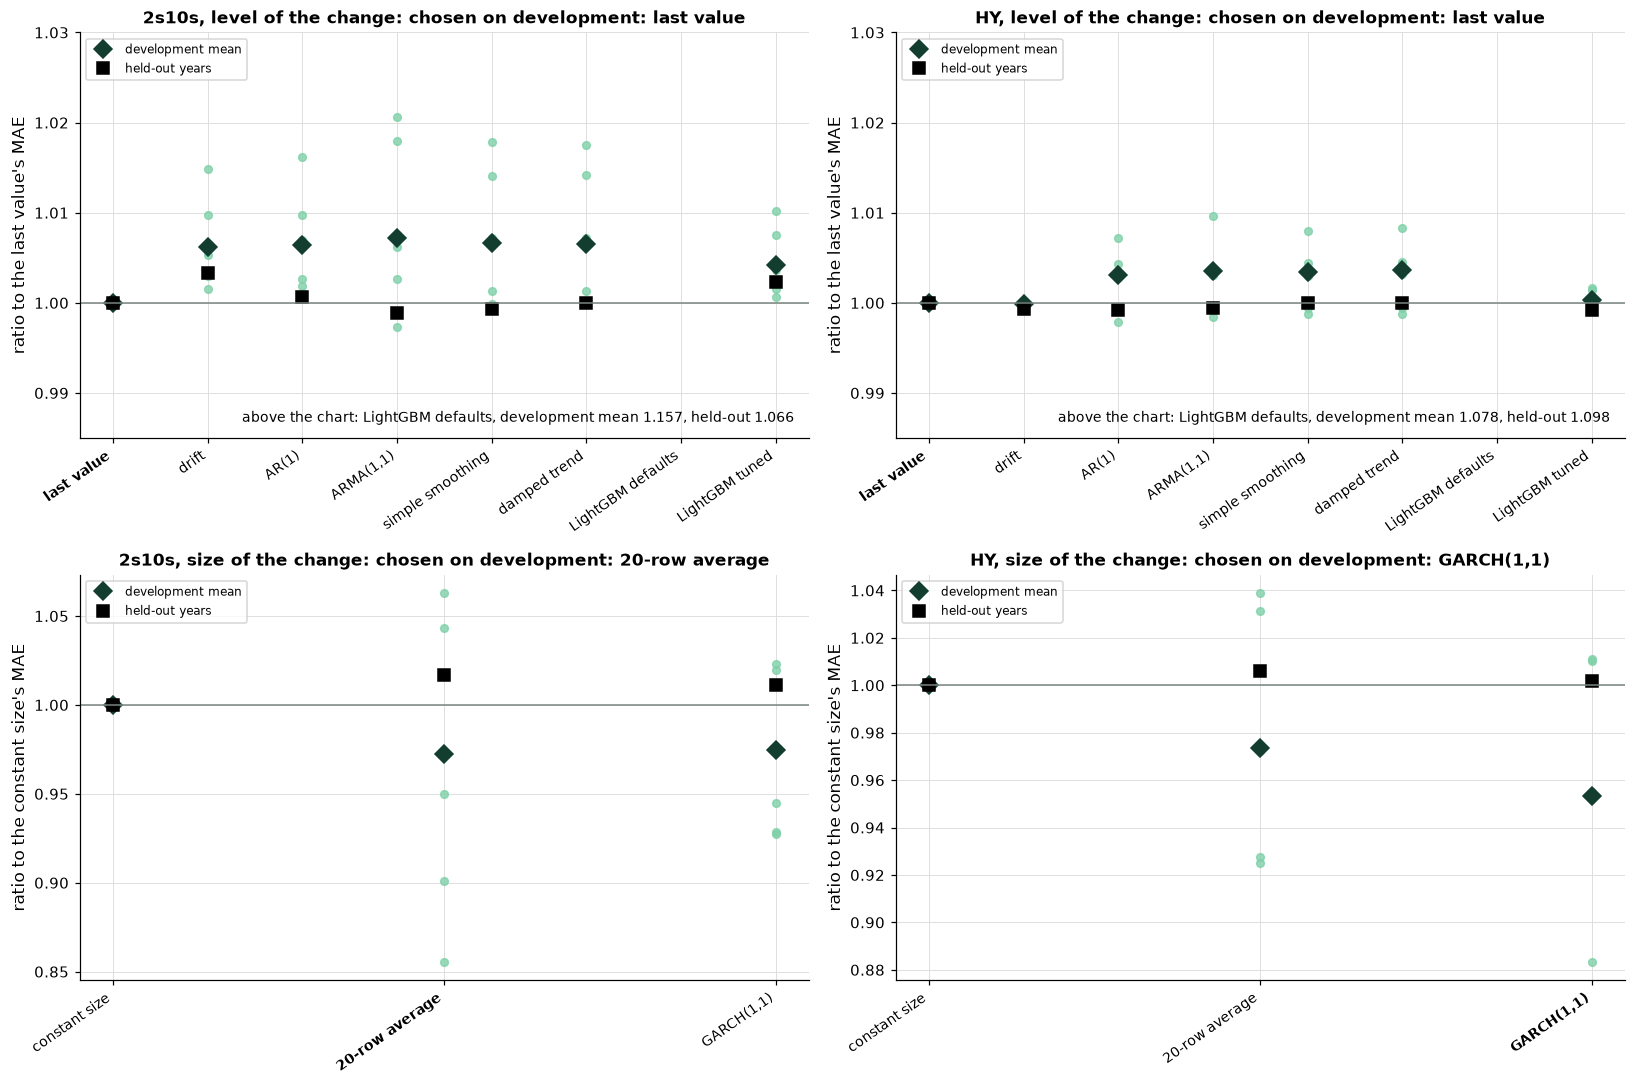

In [82]:
if answered('answer_10_1'):
    # the closing picture. Top: the level of the change, each model's MAE as a ratio to the last value's. Bottom: the size of the change, each
    # rule's MAE as a ratio to a constant size. Dots are the development folds, diamonds their mean, squares the held-out years, opened once.
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    for column, name in enumerate(full.columns):
        for row, (dev, held, base, choice, title) in enumerate([
                (dev_mae[name].drop(columns="training mean"), held_mae[name].drop("training mean"), "last value", level_choice[name], "level of the change"),
                (dev_size[name], held_size[name], "constant size", size_choice[name], "size of the change")]):
            ax = axes[row, column]
            by_fold = dev.div(dev[base], axis=0)
            positions = np.arange(dev.shape[1])
            for fold in by_fold.index:
                ax.plot(positions, by_fold.loc[fold], "o", color=plotkit.GREEN_LIGHT, markersize=5, alpha=0.8)
            ax.plot(positions, dev.mean() / dev[base].mean(), "D", color=plotkit.GREEN_DARK, markersize=8, label="development mean")
            ax.plot(positions, held / held[base], "s", color="black", markersize=8, label="held-out years")
            ax.axhline(1, color=plotkit.GREY, linewidth=1)
            ax.set_xticks(positions, list(dev.columns), rotation=35, ha="right", fontsize=9)
            ax.get_xticklabels()[list(dev.columns).index(choice)].set_fontweight("bold")
            ax.set_ylabel(f"ratio to the {base}'s MAE")
            if row == 0:
                # the level of the change: zoom on the cluster at 1.0, and name any model above the chart
                ax.set_ylim(min(0.985, by_fold.min().min() - 0.005), 1.03)
                above = [model for model in dev.columns if (by_fold[model] > 1.03).any()]
                if above:
                    ax.annotate(f"above the chart: {above[0]}, development mean {(dev[above[0]].mean() / dev[base].mean()):.3f}, held-out {(held[above[0]] / held[base]):.3f}",
                                xy=(0.98, 0.04), xycoords="axes fraction", ha="right", fontsize=9)
            ax.set_title(f"{name}, {title}: chosen on development: {choice}", fontsize=11)
            ax.legend(loc="upper left", fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print("not attempted yet")

* **The lowest held-out MASE was 0.9988 for the 2s10s (ARMA(1,1)) and 0.9992 for the HY (LightGBM tuned)**: 0.12 and 0.08 percent below the last value, with the last value at exactly 1.0. Every model except LightGBM with its defaults and the training mean sat within 0.33 percent of it.
* How to read the closing picture. Top row: the level of the change. The light dots are the five development folds, each model's MAE as a ratio to the last value's in that fold; the diamond is their mean; the black square is the held-out years. The squares sit near the diamonds, at about 1.0 and inside the spread of the dots, so the held-out years told the same story as the development folds: no model for the level of the change was reliably closer than carrying the value forward. Bottom row: the size of the change. The development diamonds sit below 1.0 for the 20-row average and GARCH, with the dots on both sides of 1.0 (3 folds of 5 below), and the squares sit above 1.0: the development gain did not carry over.
* **The plain finding.** Nothing fitted on past changes of the 2s10s or the HY scored meaningfully closer to the held-out values than the last value carried forward. The size of a change was another matter on the development folds, with a few percent of gain, and that gain was gone on the held-out years.

In [83]:
check('Question 10.1', answer_10_1, '272af77108d7', places=4)

Question 10.1: correct


### 10.2 Deliverable 10: the results file

Q. Save the summary tables of the level of the change as `results.csv` (one table with the series and the model as the index, the `chosen` column left out, rounded to 4 decimals, LF line endings), and commit it with a message that names the deliverable.

In [84]:
# one file: the series and the model as the index, every score to 4 decimals, LF line endings
results = pd.concat({name: summary[name].drop(columns="chosen") for name in summary}, names=["series", "model"])
results.round(4).to_csv("results.csv", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8").splitlines()[0])
print(f"{len(results)} rows")

series,model,development MAE (bp),development MASE,held-out MAE (bp),held-out MASE,held-out gap to the last value (bp)
18 rows


In [85]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Deliverable 10: the models against the last value"
!git -C "{work}" log --oneline

393d831 Deliverable 10: the models against the last value
96b1b90 Deliverable 8: the choice, made on the development years
90bbe44 Deliverable 8: choose_model and its test
e13ad15 Deliverable 2: the change log of the repair
a5f78ee Deliverable 1: the module, every test passing


### 10.3 Deliverable 10: the written description

Q. Write "What the models show, and where they fail" in the cell below, in 300 to 500 words of markdown, and run it: it writes `description.md`. Then run the cell after it, which checks your page with `mlkit.assert_descriptive` and displays it. Commit it. Cover:

1. **The data.** The two series, their source and licence, and what was planted and repaired.
2. **What was compared,** how the models were scored, and the rule that chose between them.
3. **What the development years showed** and **what the held-out years showed,** with the numbers, side by side.
4. **Where the models failed.** Which results did not carry over, and why the two exercises differ.
5. **What the data cannot support,** and what was not tested.

The rule, once more: **describe, never forecast.** `assert_descriptive` stops on words that look forward or give advice, such as "will", "should", and "expect"; a sentence that needs one is rewritten. The word list is a reminder, not a proof. There is no check cell for this question.

In [86]:
%%writefile description.md
# What the models show, and where they fail

**The data.** Two daily series in bp, 2,940 dates from 2015-01-02 to 2026-10-02: the 2s10s slope, the 10 Yr less the 2 Yr yield from the U.S. Treasury's public file, and an invented HY spread, Course 3's synthetic series, which is not ICE, Moody's, or any index. Twelve blank cells and three wrong prints were planted in the development years. A second feed corrected six cells and a forward fill repaired nine, leaving seven cells within 4.0 bp of the true values.

**What was compared.** On five walk-forward folds of the development years: the last value carried forward, the drift, the training mean, AR(1) and ARMA(1,1) on the changes, simple and damped exponential smoothing, and LightGBM on lagged changes with its defaults and with day 8's settings. For the size of a change: a constant, the average of the last 20 sizes, and GARCH(1,1). A rule written first picked a model only if its mean was lower than the baseline's and it was lower in at least 3 of 5 folds.

**What the development years showed.** No model for the level of the change cleared that rule, so the last value was kept for both series. Every model except LightGBM with its defaults sat within 0.7 percent of the last value, while the last value's own fold MAE ranged by 1.2 bp for the 2s10s and 2.3 bp for the HY. The size of a change was different: the squared changes were autocorrelated, and the 20-row average (2.8 percent closer than a constant) and GARCH(1,1) (4.7 percent closer) were chosen.

**What the held-out years showed.** The last value's MAE was 2.9542 bp for the 2s10s and 3.9820 bp for the HY. Three models for the 2s10s and four for the HY scored below it, by at most 0.0035 and 0.0033 bp: a gap in the third decimal, a tiny share of the fold-to-fold spread above. LightGBM with its defaults sat 0.19 and 0.39 bp further away. The size rules chosen on development scored 1.7 percent (2s10s) and 0.2 percent (HY) further from the held-out sizes than the constant, which scored lowest: the development gain did not carry over.

**Where the models failed.** Nothing fitted on past changes found the level of a change, and the size gain of the development years was gone in the held-out years. Each model was fitted once, on all the development dates, and run through 939 held-out dates with its coefficients held fixed; the development folds refitted every 252 dates, so the two exercises differ.

**What the data cannot support.** One stretch of 939 dates; two series, one of them invented; no refit inside the held-out years; no other models, windows, or lags. Nothing here is a view on rates or spreads.

Writing description.md


In [87]:
# check the page against the course's word list (it raises ValueError naming any word found), then show it
page_text = Path("description.md").read_text(encoding="utf-8")
mlkit.assert_descriptive(page_text)
n_words = len(page_text.split("\n", 1)[1].split())
print(f"No word from the list. {n_words} words after the title. Read it once more for meaning: the list is a reminder.")
display(Markdown(page_text))

No word from the list. 457 words after the title. Read it once more for meaning: the list is a reminder.


# What the models show, and where they fail

**The data.** Two daily series in bp, 2,940 dates from 2015-01-02 to 2026-10-02: the 2s10s slope, the 10 Yr less the 2 Yr yield from the U.S. Treasury's public file, and an invented HY spread, Course 3's synthetic series, which is not ICE, Moody's, or any index. Twelve blank cells and three wrong prints were planted in the development years. A second feed corrected six cells and a forward fill repaired nine, leaving seven cells within 4.0 bp of the true values.

**What was compared.** On five walk-forward folds of the development years: the last value carried forward, the drift, the training mean, AR(1) and ARMA(1,1) on the changes, simple and damped exponential smoothing, and LightGBM on lagged changes with its defaults and with day 8's settings. For the size of a change: a constant, the average of the last 20 sizes, and GARCH(1,1). A rule written first picked a model only if its mean was lower than the baseline's and it was lower in at least 3 of 5 folds.

**What the development years showed.** No model for the level of the change cleared that rule, so the last value was kept for both series. Every model except LightGBM with its defaults sat within 0.7 percent of the last value, while the last value's own fold MAE ranged by 1.2 bp for the 2s10s and 2.3 bp for the HY. The size of a change was different: the squared changes were autocorrelated, and the 20-row average (2.8 percent closer than a constant) and GARCH(1,1) (4.7 percent closer) were chosen.

**What the held-out years showed.** The last value's MAE was 2.9542 bp for the 2s10s and 3.9820 bp for the HY. Three models for the 2s10s and four for the HY scored below it, by at most 0.0035 and 0.0033 bp: a gap in the third decimal, a tiny share of the fold-to-fold spread above. LightGBM with its defaults sat 0.19 and 0.39 bp further away. The size rules chosen on development scored 1.7 percent (2s10s) and 0.2 percent (HY) further from the held-out sizes than the constant, which scored lowest: the development gain did not carry over.

**Where the models failed.** Nothing fitted on past changes found the level of a change, and the size gain of the development years was gone in the held-out years. Each model was fitted once, on all the development dates, and run through 939 held-out dates with its coefficients held fixed; the development folds refitted every 252 dates, so the two exercises differ.

**What the data cannot support.** One stretch of 939 dates; two series, one of them invented; no refit inside the held-out years; no other models, windows, or lags. Nothing here is a view on rates or spreads.


In [88]:
!git -C "{work}" add description.md
!git -C "{work}" commit -q -m "Deliverable 10: what the models show, and where they fail"
!git -C "{work}" log --oneline

62bc523 Deliverable 10: what the models show, and where they fail
393d831 Deliverable 10: the models against the last value
96b1b90 Deliverable 8: the choice, made on the development years
90bbe44 Deliverable 8: choose_model and its test
e13ad15 Deliverable 2: the change log of the repair
a5f78ee Deliverable 1: the module, every test passing


### 10.4 Deliverable 11: the AI-use log

Q. Fill in the log in the cell below, one row for each time you asked an AI assistant for help with the capstone: what you asked, what you accepted or rejected, and how you checked it. If you used none, write `none used` in the first row. Run the cell: it writes `ai_use_log.md` in the work folder. Then commit it.

What never goes into an AI tool, or into a cloud notebook such as Colab: client names, positions, anything from your employer, and licensed data. This course's data is public or invented, but the habit is the same: describe the columns and the task, and keep the rows out. Your firm's policy comes before anything said here. There is no check cell for this question.

In [89]:
%%writefile ai_use_log.md
# AI-use log

An example of a filled-in log, written for this course to show the level of detail to aim for.

| What I asked | What I accepted or rejected | How I checked it |
| --- | --- | --- |
| A function for the MASE column of my summary table | Accepted the idea of dividing each model's MAE by one baseline's. Rejected the first version, which divided by the smallest MAE in the table | Wrote a test from the docstring: the last value carried forward must score exactly 1.0 |
| Why my ARMA(1,1) fit stopped with a convergence error | Accepted that mixed orders can have a flat likelihood. Rejected a suggestion to silence the warning | Read the BIC grid and kept AR(1) and ARMA(1,1) with `fit_arima`, which raises |
| A sentence for my description saying a model "will keep its gain" | Rejected it: the description says what the models did on these dates, and `assert_descriptive` stops on "will" | Rewrote it in the past tense and ran the check cell |

No row of a file went into the assistant. Each question described the columns and the task.

Writing ai_use_log.md


In [90]:
!git -C "{work}" add ai_use_log.md
!git -C "{work}" commit -q -m "Deliverable 11: the AI-use log"
!git -C "{work}" log --oneline

de50250 Deliverable 11: the AI-use log
62bc523 Deliverable 10: what the models show, and where they fail
393d831 Deliverable 10: the models against the last value
96b1b90 Deliverable 8: the choice, made on the development years
90bbe44 Deliverable 8: choose_model and its test
e13ad15 Deliverable 2: the change log of the repair
a5f78ee Deliverable 1: the module, every test passing


## Excel Side by Side

**Excel does the arithmetic around the models, and not the models.** It has no ARIMA, no exponential smoothing fitter, no GARCH, no boosted trees, and no walk-forward folds, so those stay in Python. It does the forward fill, the autocorrelation, an AR(1) by hand, the miss of the last value, the average of the last 20 sizes, and the ratios of a summary table. Every formula below was typed into desktop Excel for Windows by script (Excel 16.0 build 20430, 2026-10-21), on the 2,940 dates in bp, and its result read back. In the first workbook the dates are in A, the 2s10s in B, the HY in C, the changes in D and E, the sizes in F and G, and the average of the 20 sizes before each date in H and I; the development changes are rows 3 to 2002 and the held-out changes rows 2003 to 2941. The 2s10s results are in K1 to K7 and the HY results in L1 to L7. The second workbook is the one your own code writes below.

Q. Write the results workbook: `pd.ExcelWriter("course5b_capstone_results.xlsx")` with the sheets `development 2s10s` and `development HY` (the fold MAEs, with the `fold` index) and `held-out` (the held-out MAEs, a column for each series). Read every sheet back with `pd.read_excel(..., sheet_name=None, index_col=0)` and check it against the tables. Store a tuple (sheets, the 2s10s ARMA(1,1) mean MAE on the folds read from the file, to 4 decimals) in **answer_xl**.

In [91]:
# write the results workbook: the fold MAEs of both series, and the held-out MAEs, one sheet each; then read every sheet back
with pd.ExcelWriter("course5b_capstone_results.xlsx") as writer:
    for name in levels.columns:
        dev_mae[name].to_excel(writer, sheet_name=f"development {name}")
    pd.DataFrame(held_mae).to_excel(writer, sheet_name="held-out")
back = pd.read_excel("course5b_capstone_results.xlsx", sheet_name=None, index_col=0)
for name in levels.columns:
    # openpyxl writes each float with 16 significant digits, so a value can come back changed in its 17th
    pd.testing.assert_frame_equal(back[f"development {name}"], dev_mae[name], rtol=1e-14, atol=0, check_names=False)
pd.testing.assert_frame_equal(back["held-out"], pd.DataFrame(held_mae), rtol=1e-14, atol=0, check_names=False)
print("sheets:", ", ".join(f"{sheet} {table.shape[0]} x {table.shape[1]}" for sheet, table in back.items()))
answer_xl = (len(back), back["development 2s10s"]["ARMA(1,1)"].mean())
print(f"{answer_xl[0]} sheets; ARMA(1,1) fold mean for the 2s10s read from the file: {answer_xl[1]:.4f}")

sheets: development 2s10s 5 x 9, development HY 5 x 9, held-out 9 x 2
3 sheets; ARMA(1,1) fold mean for the 2s10s read from the file: 2.1750


* Three sheets, read back within a relative 1e-14 of the tables they came from. The workbook is ignored by Git (`*.xlsx`): it is an output, rebuilt from the notebook at any time. Open `course5b_capstone_results.xlsx` from the work folder (its name is in the setup cell's output; in File Explorer, paste `%TEMP%` into the address bar), and type the formulas below beside its tables.

In [92]:
check('Question Excel', answer_xl, 'c791d4eda25e', places=4)

Question Excel: correct


<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel (tested)</th><th align="left">Excel returned: 2s10s</th><th align="left">Excel returned: HY</th></tr>
<tr><td align="left">Blank cells in the HY's published copy</td><td align="left"><code>published["HY"].isna().sum()</code></td><td align="left"><code>=COUNTBLANK(A2:A2002)</code></td><td align="left"></td><td align="left">4</td></tr>
<tr><td align="left">Forward fill, then the sum of the filled column</td><td align="left"><code>published["HY"].ffill().sum()</code></td><td align="left"><code>=IF(A2="",B1,A2)</code> in B2, filled down; <code>=SUM(B2:B2002)</code></td><td align="left"></td><td align="left">483,100.2</td></tr>
<tr><td align="left">Lag-1 autocorrelation of the development changes</td><td align="left"><code>changes[name].autocorr(1)</code></td><td align="left"><code>=CORREL(D4:D2002,D3:D2001)</code> (changes in D, offset by one row)</td><td align="left">-0.0238</td><td align="left">0.0099</td></tr>
<tr><td align="left">An AR(1) by hand: slope and constant</td><td align="left"><code>np.polyfit(x, y, 1)</code></td><td align="left"><code>=SLOPE(D4:D2002,D3:D2001)</code> and <code>=INTERCEPT(D4:D2002,D3:D2001)</code></td><td align="left">-0.0237 and -0.0969</td><td align="left">0.0099 and 0.0462</td></tr>
<tr><td align="left">Last value's MAE on the held-out changes</td><td align="left"><code>held_change.abs().mean()</code></td><td align="left"><code>=SUMPRODUCT(ABS(D2003:D2941))/COUNT(D2003:D2941)</code></td><td align="left">2.9542</td><td align="left">3.9820</td></tr>
<tr><td align="left">The AR(1)'s MAE on them, and its ratio</td><td align="left"><code>ar1_miss.abs().mean()</code></td><td align="left"><code>=SUMPRODUCT(ABS(D2003:D2941-(K3+K2*D2002:D2940)))/COUNT(D2003:D2941)</code>, then <code>=K5/K4</code></td><td align="left">2.9556, 1.0005</td><td align="left">3.9788, 0.9992</td></tr>
<tr><td align="left">The 20-row average's MAE for the size</td><td align="left"><code>rolling(20).mean().shift(1)</code></td><td align="left"><code>=AVERAGE(F3:F22)</code> in H23, filled down; <code>=SUMPRODUCT(ABS(F2003:F2941-H2003:H2941))/COUNT(F2003:F2941)</code></td><td align="left">1.9643</td><td align="left">2.6458</td></tr>
<tr><td align="left">In the results workbook: ARMA(1,1)'s MASE on the folds, and the folds below the last value</td><td align="left"><code>frame.mean() / frame['last value'].mean()</code></td><td align="left"><code>=AVERAGE(F2:F6)/AVERAGE(B2:B6)</code>, then <code>=SUMPRODUCT(--(F2:F6&lt;B2:B6))</code></td><td align="left">1.0071, 1</td><td align="left">1.0035, 2</td></tr>
<tr><td align="left">In the results workbook: held-out MASE, and the models below the last value</td><td align="left"><code>held_mae[name] / held_mae[name]['last value']</code></td><td align="left"><code>=B6/B2</code>, then <code>=COUNTIF(B3:B10,"&lt;"&amp;(B2-0.000001))</code></td><td align="left">0.9988, 3</td><td align="left">0.9994, 4</td></tr>
</table>
<br clear="left">

**Forward fill and lags.** Put the published HY in A and `=IF(A2="",B1,A2)` in B2, filled down: when the cell is blank it takes the cell above, which is `ffill`. `COUNTBLANK` counts the four blanks. The autocorrelation is `CORREL` of the changes against the same changes one row down, which is pandas' `autocorr` (statsmodels' `acf` and `tskit.acf_by_hand` differ from it in the fourth decimal, as day 4 showed).

**An AR(1) by hand.** `SLOPE` of the change on the change before it, and `INTERCEPT`, fitted on the development rows only. The held-out miss is the change less `constant + slope x` the change on the row before, and the MAE is `SUMPRODUCT` of the absolute misses over their count. The last value's miss is the change itself. Divide one by the other and the ratio is the MASE.

**The average of the last 20 sizes.** In H23, `=AVERAGE(F3:F22)` averages the 20 sizes in rows 3 to 22; filled down, each row averages the 20 before it, the same window as `rolling(20).mean().shift(1)`.

**Your workbook.** On a development sheet, `=AVERAGE(F2:F6)/AVERAGE(B2:B6)` is the ARMA(1,1) column over the last value column, the MASE on the folds; on `held-out`, `=B6/B2` is the same ratio on the held-out years.

* **Every Excel value equals Python's:** the largest gap across the 26 quantities is 5e-15. Excel returned an AR(1) slope of -0.0237 for the 2s10s and 0.0099 for the HY, and a held-out MASE of 1.0005 and 0.9992.

In [93]:
# what the Excel formulas compute, in Python: fitted on the development changes, applied to the held-out changes, and the size rule
excel_python = {}
for name in full.columns:
    change = full_changes[name]
    dev_change, held_change = change.iloc[:n_dev - 1], change.iloc[n_dev - 1:]
    # AR(1) by hand: the change on the change one row up, as SLOPE and INTERCEPT do it
    slope, intercept = np.polyfit(dev_change.iloc[:-1], dev_change.iloc[1:], 1)
    ar1_miss = held_change - (intercept + slope * change.shift(1).iloc[n_dev - 1:])
    size = change.abs()
    rolling_miss = size.iloc[n_dev - 1:] - size.rolling(20).mean().shift(1).iloc[n_dev - 1:]
    excel_python[name] = {"lag-1 autocorrelation, development": dev_change.autocorr(1), "AR(1) slope": slope, "AR(1) constant": intercept,
                          "last value MAE, held-out (bp)": held_change.abs().mean(), "AR(1) MAE, held-out (bp)": ar1_miss.abs().mean(),
                          "20-row average of the size, MAE, held-out (bp)": rolling_miss.abs().mean()}
    excel_python[name]["AR(1) MASE, held-out"] = excel_python[name]["AR(1) MAE, held-out (bp)"] / excel_python[name]["last value MAE, held-out (bp)"]
excel_table = pd.DataFrame(excel_python)
print(excel_table.round(4).to_string())
# the forward fill of the HY's published blanks: the number of blanks, and the sum after a forward fill
filled = published["HY"].ffill()
print(f"HY published: {int(published['HY'].isna().sum())} blank cells; sum after a forward fill {filled.sum():,.1f}")

                                                 2s10s      HY
lag-1 autocorrelation, development             -0.0238  0.0099
AR(1) slope                                    -0.0237  0.0099
AR(1) constant                                 -0.0969  0.0462
last value MAE, held-out (bp)                   2.9542  3.9820
AR(1) MAE, held-out (bp)                        2.9556  3.9788
20-row average of the size, MAE, held-out (bp)  1.9643  2.6458
AR(1) MASE, held-out                            1.0005  0.9992
HY published: 4 blank cells; sum after a forward fill 483,100.2


In [94]:
# Excel's results, from the course's Excel check, beside Python's
excel_side = pd.DataFrame({
    "Excel": [-0.023755592454704055, -0.02370484509405761, 2.954206602768903, 2.955604055989096, 1.0004730384188036, 1.9643237486687966, 0.0098744896869902, 0.009874715741455717, 3.982002129925453, 3.978819228493596, 0.9992006781191961, 2.6458466453674125],
    "Python": [excel_table.loc["lag-1 autocorrelation, development", "2s10s"], excel_table.loc["AR(1) slope", "2s10s"], excel_table.loc["last value MAE, held-out (bp)", "2s10s"],
               excel_table.loc["AR(1) MAE, held-out (bp)", "2s10s"], excel_table.loc["AR(1) MASE, held-out", "2s10s"], excel_table.loc["20-row average of the size, MAE, held-out (bp)", "2s10s"],
               excel_table.loc["lag-1 autocorrelation, development", "HY"], excel_table.loc["AR(1) slope", "HY"], excel_table.loc["last value MAE, held-out (bp)", "HY"],
               excel_table.loc["AR(1) MAE, held-out (bp)", "HY"], excel_table.loc["AR(1) MASE, held-out", "HY"], excel_table.loc["20-row average of the size, MAE, held-out (bp)", "HY"]],
}, index=pd.Index(['2s10s lag-1 autocorrelation, development', '2s10s AR(1) slope', '2s10s last value MAE, held-out (bp)', '2s10s AR(1) MAE, held-out (bp)', '2s10s AR(1) MASE, held-out', '2s10s 20-row average, size MAE (bp)', 'HY lag-1 autocorrelation, development', 'HY AR(1) slope', 'HY last value MAE, held-out (bp)', 'HY AR(1) MAE, held-out (bp)', 'HY AR(1) MASE, held-out', 'HY 20-row average, size MAE (bp)'], name="Quantity"))
excel_side["equal within 1e-8"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-8
plotkit.styled(excel_side, [], "Excel beside Python: the autocorrelation, the AR(1), the held-out MAEs, and the size rule", fmt="{:.6f}")

,Excel,Python,equal within 1e-8
Quantity,,,
"2s10s lag-1 autocorrelation, development",-0.023756,-0.023756,True
2s10s AR(1) slope,-0.023705,-0.023705,True
"2s10s last value MAE, held-out (bp)",2.954207,2.954207,True
"2s10s AR(1) MAE, held-out (bp)",2.955604,2.955604,True
"2s10s AR(1) MASE, held-out",1.000473,1.000473,True
"2s10s 20-row average, size MAE (bp)",1.964324,1.964324,True
"HY lag-1 autocorrelation, development",0.009874,0.009874,True
HY AR(1) slope,0.009875,0.009875,True
"HY last value MAE, held-out (bp)",3.982002,3.982002,True


* Every quantity is equal to within 1e-8.

## Save the Day with Git

### Deliverable 11: the history

Q. Show the history with `git log --oneline`: one commit for each deliverable that writes a file. Store the number of commits in **answer_git**. Then tag the last commit `course5b`, and show the history with its names.

In [95]:
# one line per commit, newest first
!git -C "{work}" log --oneline

de50250 Deliverable 11: the AI-use log
62bc523 Deliverable 10: what the models show, and where they fail
393d831 Deliverable 10: the models against the last value
96b1b90 Deliverable 8: the choice, made on the development years
90bbe44 Deliverable 8: choose_model and its test
e13ad15 Deliverable 2: the change log of the repair
a5f78ee Deliverable 1: the module, every test passing


In [96]:
# count the commits: one line each in git log --oneline
history_log = subprocess.run(["git", "-C", str(work), "log", "--oneline"], capture_output=True, text=True, check=True).stdout
answer_git = len(history_log.strip().splitlines())
print(f"Commits: {answer_git}")

Commits: 7


In [97]:
# name the last commit, then show the names
!git -C "{work}" tag course5b
!git -C "{work}" log --oneline --decorate

de50250 (HEAD -> main, tag: course5b) Deliverable 11: the AI-use log
62bc523 Deliverable 10: what the models show, and where they fail
393d831 Deliverable 10: the models against the last value
96b1b90 Deliverable 8: the choice, made on the development years
90bbe44 Deliverable 8: choose_model and its test
e13ad15 Deliverable 2: the change log of the repair
a5f78ee Deliverable 1: the module, every test passing


* 7 commits: the module, the change log, `choose_model`, the choice, the results, the description, and the AI-use log. The choice was committed before the results, so Git's order shows it was made first. The workbook stays out, and so do the data copies.
* `course5b` names the commit that ends the course.

In [98]:
check('Question Git', answer_git, '2a4dfbe117ab')

Question Git: correct


## Bring It Home

Bring the capstone into your own `my_bondmath` folder. Open a PowerShell terminal in VS Code (Terminal, New Terminal), with the course's `.venv` active.

**Step 1.** Go to your folder and check that your module still passes.

```powershell
Set-Location "$HOME\projects\my_bondmath"
python -m pytest -q test_tskit.py
```

**Step 2.** Open `tskit.py` and paste `choose_model` at the end, without its first line, and its test at the end of `test_tskit.py`. Copy `description.md` and `choice.md` from the work folder. The setup cell printed its name, `pfi_course5b_10_` and eight more characters: put it in place of `<work folder>`.

```powershell
$work = "$env:TEMP\<work folder>"
Copy-Item "$work\description.md", "$work\choice.md" .
```

**Step 3.** Run the tests, then commit the code and the two pages, and tag the end of the course.

```powershell
python -m pytest -q test_tskit.py
git add tskit.py test_tskit.py description.md choice.md
git commit -m "Course 5B capstone: choose_model, the choice, and the description"
git tag course5b
git log --oneline --decorate -3
```

The last line of pytest says `52 passed`.

**In Colab**, download `description.md`, `choice.md`, and `course5b_capstone_results.xlsx` from the work folder under `/tmp` in the file browser.

## You Can Now

* Find every gap and wrong print in a dated table, correct from a second source with a change log, and fill what is left by a rule that never looks ahead.
* Test two series for stationarity, read the memory of their changes and of their squares, and say which model families that leaves open.
* Score the baselines, ARIMA, exponential smoothing, LightGBM on lags, and GARCH walk-forward against the last value carried forward, in bp.
* Write a choice rule as a tested function, choose on the development years only, and commit the choice before the held-out years open.
* Open the held-out years once, score every model once, and write the plain result: no model for the level of the change was meaningfully closer than the last value, and the development gain in the size of a change did not carry over.
* Write a results workbook that Excel can check, and a description with no forecast, no cause, and no advice.

Next, Course 6: Neural Networks.

## Exercises

The capstone's questions are its exercises. One more, last, as on every day of the course.

### The AI check

You ask an AI assistant for the function behind your summary table's MASE column, and you give it the docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Each model's mean walk-forward MAE as a ratio to the last value carried forward's (the MASE).

    mean_mae is a pandas Series of mean MAEs in bp, indexed by model name, and it holds the baseline. A model's ratio is its MAE
    divided by the baseline's: exactly 1.0 for the baseline itself, below 1.0 for a model closer than the baseline, above 1.0
    for a model further. Returns a Series with the same index.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a Series, and contains one bug.

* The bug: `scale = mean_mae.min()`. The function divides by the smallest MAE in the table, not by the last value's. Whenever the last value is the best model, as it was for the 2s10s on the development folds, the two are the same and nothing looks wrong. On the held-out years ARMA(1,1) was lower than the last value, so the smallest MAE was ARMA(1,1)'s: the function returned 1.0012 for the last value instead of 1.0, and 1.0 for ARMA(1,1), which makes the best model look like the baseline and the baseline look worse than it is.
* The fix, in the cell below: divide by `mean_mae[baseline]`, and refuse a baseline that is not in the index. The test from the docstring asserts that the last value is exactly 1.0 and that a model closer than the baseline is below 1.0.

In [99]:
def mase_by_model(mean_mae, baseline="last value"):
    """Each model's mean walk-forward MAE as a ratio to the last value carried forward's (the MASE).

    mean_mae is a pandas Series of mean MAEs in bp, indexed by model name, and it holds the baseline. A model's ratio is its MAE
    divided by the baseline's: exactly 1.0 for the baseline itself, below 1.0 for a model closer than the baseline, above 1.0
    for a model further. Returns a Series with the same index.
    """
    if baseline not in mean_mae.index:
        raise ValueError(f"{baseline!r} is not in the index: {list(mean_mae.index)}")
    # the scale is the baseline's MAE, not the smallest MAE in the table: the baseline is 1.0 whatever the models score
    return mean_mae / mean_mae[baseline]

Q. Test the function against its docstring before you trust it.

In [100]:
scores = pd.Series({"last value": 2.0, "drift": 2.2, "ARMA(1,1)": 1.9})
found = mase_by_model(scores)
assert found["last value"] == 1.0, f"the last value's ratio is {found['last value']:.4f}, not 1.0: the baseline is the scale"
assert found["ARMA(1,1)"] < 1 < found["drift"], "a model closer than the baseline is below 1.0 and one further is above 1.0"
print(f"ratios: {found.round(4).to_dict()}")

ratios: {'last value': 1.0, 'drift': 1.1, 'ARMA(1,1)': 0.95}


In [101]:
# the assistant's version kept under another name, on the held-out MAEs of the 2s10s
def mase_by_model_assistant(mean_mae, baseline="last value"):
    """Each model's mean walk-forward MAE as a ratio to the last value carried forward's (the MASE).

    mean_mae is a pandas Series of mean MAEs in bp, indexed by model name, and it holds the baseline. A model's ratio is its MAE
    divided by the baseline's: exactly 1.0 for the baseline itself, below 1.0 for a model closer than the baseline, above 1.0
    for a model further. Returns a Series with the same index.
    """
    scale = mean_mae.min()
    return mean_mae / scale

ai_buggy_mase = mase_by_model_assistant(held_mae["2s10s"])["last value"]
ai_fixed_mase = mase_by_model(held_mae["2s10s"])["ARMA(1,1)"]
print(f"the assistant's ratio for the last value: {ai_buggy_mase:.4f}; the fixed function's ratio for ARMA(1,1): {ai_fixed_mase:.4f}")

the assistant's ratio for the last value: 1.0012; the fixed function's ratio for ARMA(1,1): 0.9988


* 1.0012 where the answer is 1.0, and the fixed function's 0.9988 for ARMA(1,1). Keep the test: it checks the one number a score cannot tell you, that the baseline is exactly 1.0.

In [102]:
check("AI check the assistant's ratio", ai_buggy_mase, 'e5a962233e88', places=4)
check('AI check the fixed ratio', ai_fixed_mase, 'ada00b891f2a', places=4)

AI check the assistant's ratio: correct
AI check the fixed ratio: correct


### Optional: the same workflow on a real spread

If you have Course 3's FRED key, you can run this workflow on an ICE BofA option-adjusted spread series, **on your own screen only**: repair, test, score the baselines and the models on development folds, choose by your rule, and open the last years once. That data is licensed. It is pulled live through your own key, it is never saved to a file, never put in a notebook that you share, never committed, and never shown in a slide. Nothing in this course's notebooks reads from FRED, and this exercise has no check cell. Whatever you find describes the dates you pulled, and says nothing about the dates after them.

## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```